# **Lab 2 – Tidying, Cleaning, Imputation, and Outlier Detection**

## Machine Learning Programming

This notebook contains **all four completed sections** of the lab, in the handout's order. Each section starts with its own setup cell, so a section can be read and run independently.

The purpose of this lab is to practice the data-preprocessing work that normally takes place before machine learning: reshaping data, cleaning inconsistent values, handling missing data, detecting outliers, visualizing results, and explaining the decisions you make.

## **Replicability Check**

### How to reproduce this notebook

1. Create a virtual environment with **Python 3.13** and run `pip install -r requirements.txt` (exact versions from `pip freeze`).
2. Create a `.env` file in the project root containing `NEON_DATABASE_URL=<connection string>` (see the README). **Section 1 needs it**: its licensed Pew survey data is stored only in the team's Neon database and cannot be published in the repository. Sections 2–4 also read from Neon, but fall back to the CSV files committed in `data/` when `.env` is missing. The notebook **only reads** from the database, so a read-only login is enough.
3. Open this notebook, select the `.venv` kernel, and choose **Restart** then **Run All**.

> **Without the Neon connection string, Run All stops at Section 1.** Ask the team for the connection string. Sections 2–4 can still be run on their own from `notebooks/`.

### Test in a clean environment

| Item | Detail |
|---|---|
| Date | 2026-10-15 |
| Machine | macOS, Python 3.13.13 |
| Method | Fresh `git clone` of the GitHub repository into an empty folder, new virtual environment created only from `requirements.txt`, then **Run All** |
| Result with `.env` | All four sections ran without errors (data loaded from Neon) |
| Result without `.env` | Sections 2–4 ran without errors using the committed CSV files; Section 1 stopped with its "`NEON_DATABASE_URL` is not set" message, as designed |

### Issues found and how they were fixed

| Issue | Fix |
|---|---|
| Section 2 failed without `.env`: the Billboard CSV files were not in the repository | Committed both files to `data/` (public TidyTuesday data, 46 MB and 10 MB) |
| `requirements.txt` was not an exact freeze: six dependencies installed without pinned versions | Regenerated it with `pip freeze` from a clean environment, and checked that a fresh install freezes back to the identical file |
| Section 1 could not be loaded by teammates: `pyreadstat` was missing from `requirements.txt` | Added `pyreadstat` |
| Uploading the wide Pew tables to Neon failed: too many query parameters in one `INSERT` | Batch size is now set from the number of columns (`src/common/database.py`) |
| SQL tables have no guaranteed row order, which changed duplicate handling and train/test splits | Tables are uploaded with a `row_id` and read back with `ORDER BY row_id` |
| A True/False column (`spotify_track_explicit`) changed type after the database round trip | Converted back to True/False on loading (`src/billboard_dataset/loading.py`) |
| Sections 3 and 4 uploaded their CSV to Neon on every run, so they would fail with a read-only login | Uploading moved to one-time scripts (`python -m car_dataset.upload`, `python -m diabetes_dataset.upload`); every section now only reads from Neon |

### Test on a second machine

| Item | Detail |
|---|---|
| Date | |
| Tester and machine | |
| Operating system and Python version | |
| Result | |
| Issues and fixes | |

## **Assignment Overview**

### Purpose
By the end of this lab, you should be able to take several imperfect datasets and make them more suitable for analysis and later machine-learning work.

### Learning Outcomes
You will practice how to:

- inspect the shape, columns, data types, and quality of a dataset;
- distinguish **wide** and **long/tidy** data;
- reshape data with `pd.melt()` or `DataFrame.melt()`;
- clean strings using Pandas string methods;
- identify, quantify, drop, and impute missing values;
- compare mean, median, mode, and `SimpleImputer` approaches;
- identify outliers visually with box plots and scatter plots;
- identify outliers statistically using **Z-Scores** and **IQR**;
- justify preprocessing decisions using evidence from the data;
- document a reproducible Python data-processing workflow.

## **How this notebook is organized**

| Section | Dataset | Research question |
|---|---|---|
| **1 – PEW Research Dataset** | Pew NPORS surveys 2023–2025 (16,381 respondents) | Do adults who use the internet "almost constantly" differ in average age from internet users who go online less often? |
| **2 – Billboard Dataset** | Billboard Hot 100 weekly charts 1958–2021, with Spotify audio features | Which characteristics of a song, known when it first enters the chart, help explain how many weeks it stays on the Hot 100? |
| **3 – Data Cleaning (Car Details Dataset)** | 8,128 CarDekho used-car listings | Do diesel cars achieve significantly better mileage than petrol cars, and how well can a car's listed characteristics predict its mileage? |
| **4 – Outlier Detection (Diabetes Dataset)** | 5,288 patients | Do diabetic patients have significantly higher glucose, BMI, and systolic blood pressure, and does that hold once outliers are taken into account? |

As a team, each section uses its own dataset rather than the handout's examples; each section explains its choice. Reusable code lives in `src/`, and the raw data is stored in a shared **Neon** (cloud PostgreSQL) database.

This notebook is built from the four section notebooks in `notebooks/` with `python scripts/build_week5lab.py`, so edits should be made there and the notebook rebuilt.

# **Section 1 – PEW Research Dataset (Pew NPORS 2023–2025)**

This section uses three annual Pew Research Center **National Public Opinion Reference Surveys (NPORS)**, 2023–2025, with **16,381 respondents** in total, distributed by the Association of Religion Data Archives (ARDA). Instead of the handout's small religion-and-income table, it applies the same tidy-data ideas to real survey data: validating coded answers, harmonizing three yearly releases, reshaping with `melt()`, and testing a hypothesis.

The raw answer codes are stored in the shared **Neon** (cloud PostgreSQL) database and loaded from there. Reusable helpers live in [`src/pew_dataset/`](src/pew_dataset/). The Neon connection class `NeonDatabase` lives in [`src/common/database.py`](src/common/database.py) and is shared with the other sections.

### **The Research Question**

> **Do adults who use the internet "almost constantly" differ in average age from internet users who go online less often?**

Why this question?

- **Internet-use intensity** is one of the questions asked in every NPORS year, so it can be prepared consistently across all three releases.
- **Age** is the demographic most often linked to technology habits, so a clear age gap would be expected. The question is whether the data confirm it, and how large the gap is.
- **Numeric age is released only for 2023–2024** (2025 gives age groups only), so the formal test uses the 2024 survey.

Every part of the notebook feeds this question: **preparation** validates the coded answers and keeps refusals (code 99) separate from real answers; **missing-value handling** shows what imputation would do to age without letting imputed ages into the test; **reshaping and visualization** explore the shared questions; and **inferential statistics** (Q-Q plots, Shapiro–Wilk, Welch's t-test) answers the question formally.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer

# Locate the project root whether Jupyter was started in the project folder or in notebooks/,
# then put src/ on Python's search path so our own packages can be imported.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from common.database import NeonDatabase  # shared Neon helper (all sections)
from pew_dataset import validate_npors, labels_from_frame
from pew_dataset.config import (
    SURVEY_YEARS, RESULTS_DIR, LABELS_TABLE_NAME, raw_table_name, source_url, codebook_url,
)

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", None)

#### **Getting the Pew NPORS 2023–2025 Data**

For this lab we use three annual Pew Research Center NPORS datasets distributed by the Association of Religion Data Archives (ARDA).

**About the Data**

Sources and Download Setup
- 2023 ARDA record and codebook
- 2024 ARDA record and codebook
- 2025 ARDA record and codebook
- Pew NPORS methodology and questionnaires

The data were downloaded from the Association of Religion Data Archives and collected by Pew Research Center. ARDA adds analysis recodes; we use the original named survey fields rather than ARDA's I- recodes. We must acknowledge both ARDA and Pew. Download requires acceptance of the archive's agreement.

**Where the data lives: Neon only**

Because the ARDA files are licensed downloads, they are **not stored in this repository**. The survey data lives in the shared **Neon** database, and this notebook reads it from there:

| Neon table | Contents |
|---|---|
| `npors23_raw`, `npors24_raw`, `npors25_raw` | One row per respondent, answers stored as **raw numeric codes**, so a refusal coded 99 stays distinguishable from a real answer |
| `npors_value_labels` | The SPSS value labels for every coded variable (survey year, variable, code, label) |

- **To run this notebook** you only need the Neon connection string in `.env` (see the README).
- **To (re)load the data into Neon**, whoever holds the ARDA downloads saves them as `data/NPORS23.sav`, `data/NPORS24.sav` and `data/NPORS25.sav` (these names are git-ignored) and runs `PYTHONPATH=src python -m pew_dataset.upload` from the project root. The script verifies that the Neon copy matches the files exactly.

### 1. Data Preparation Pipeline

#### **Task 1.1 – Load and Inspect the NPORS Datasets**


1. Preserve raw files and inspect each year before combining. 
2. Display shape, columns, data types, sample rows, missingness and unique IDs. 
3. Numeric codes must be interpreted using their value labels. isna() alone does not identify refusals coded 99.


In [2]:
connection_string = NeonDatabase.read_connection_string()
if not connection_string:
    raise RuntimeError(
        "NEON_DATABASE_URL is not set in .env. The NPORS survey data is stored only in Neon: "
        "add the connection string to .env (see the README)."
    )

db = NeonDatabase(connection_string)
print("Connected to:", db.test_connection()[:60], "...")

# Read each year's raw answer codes (in the original row order) plus the SPSS value labels
raw = {year: db.read_ordered(raw_table_name(year)) for year in SURVEY_YEARS}
value_labels = labels_from_frame(db.read_table(LABELS_TABLE_NAME))
db.close()

source_records = []
for year, frame in raw.items():
    validate_npors(frame, year)
    source_records.append({'survey_year': year, 'neon_table': raw_table_name(year),
        'rows': len(frame), 'columns': len(frame.columns),
        'memory_MB': frame.memory_usage(deep=True).sum()/1e6,
        'source_url': source_url(year), 'codebook_url': codebook_url(year)})
source_report = pd.DataFrame(source_records)
display(source_report)
print('Total respondents:', source_report['rows'].sum())
for year, frame in raw.items():
    print(year, frame.columns.tolist())
source_report.to_csv(RESULTS_DIR / 'source_manifest.csv', index=False)

Connected to: PostgreSQL 18.6 (653b019) on aarch64-unknown-linux-gnu, comp ...


,survey_year,neon_table,rows,columns,memory_MB,source_url,codebook_url
0,2023,npors23_raw,5733,66,3.844017,https://www.thearda.com/data-archive?fid=NPORS23,https://www.thearda.com/data-archive?fid=NPORS...
1,2024,npors24_raw,5626,63,2.835636,https://www.thearda.com/data-archive?fid=NPORS24,https://www.thearda.com/data-archive?fid=NPORS...
2,2025,npors25_raw,5022,46,2.346196,https://www.thearda.com/data-archive?fid=NPORS25,https://www.thearda.com/data-archive?fid=NPORS...


Total respondents: 16381
2023 ['RESPID', 'MODE_2WAY', 'DATERECEIVED', 'INTERVIEW_START', 'INTERVIEW_END', 'DEVICE_TYPE', 'STRATUM', 'LANG_PREF', 'ECON1MOD', 'ECON1BMOD', 'COMTYPE2', 'TYPOLOGYB', 'CRIMESAFE', 'POLICE_FUND', 'MOREGUNIMPACT', 'GUNSTRICT', 'VET1', 'VOL12_CPS', 'EMINUSE', 'INTMOB', 'INTFREQ', 'INTFREQ_COLLAPSED', 'RADIO', 'BOOKS1', 'BOOKS1_REFUSED', 'DEVICE1A', 'SMART2', 'NHISLL', 'RELIGCAT1', 'REGISTRATION', 'PARTY', 'PARTYLN', 'PARTYSUM', 'HISP', 'RACEMOD_1', 'RACEMOD_2', 'RACEMOD_3', 'RACEMOD_4', 'RACEMOD_5', 'RACEMOD_6', 'RACEMOD_99', 'RACEMOD_MIXEDOE', 'RACECMB', 'RACETHN', 'AGE', 'AGECAT', 'AGE_REFUSED', 'BIRTHPLACE', 'GENDER', 'MARITAL', 'EDUCATION', 'EDUCCAT', 'ADULTS', 'VOTED2020', 'VOTEGEN_POST', 'INC_SDT1', 'CREGION', 'DIVISION', 'METRO', 'BASEWT', 'WEIGHT', 'I_GENDER', 'I_RACE', 'I_PARTYID', 'I_EDUC', 'I_RELIGION']
2024 ['RESPID', 'MODE', 'LANGUAGE', 'LANGUAGEINITIAL', 'LANG_PREF', 'SURVEYSTARTDATE', 'SURVEYENDDATE', 'BWAVE', 'BIDENT1_GEOSTRATA', 'ECON1MOD', 'EC

In [3]:
profile = []
for year, frame in raw.items():
    for col in frame.columns:
        profile.append({'year': year, 'column': col, 'dtype': str(frame[col].dtype),
            'system_missing_n': int(frame[col].isna().sum()),
            'system_missing_pct': 100*frame[col].isna().mean(),
            'unique_values': frame[col].nunique(dropna=True)})
quality_raw = pd.DataFrame(profile)
display(quality_raw.groupby('year').agg(columns=('column','count'), total_system_missing=('system_missing_n','sum')))
display(quality_raw.sort_values('system_missing_pct', ascending=False).head(12))
for year in raw:
    print(year, 'INTFREQ codes:', raw[year]['INTFREQ'].value_counts(dropna=False).sort_index().to_dict())
    print(year, 'income labels:', value_labels[year].get('INC_SDT1', {}))
    print(year, 'AGE labels:', value_labels[year].get('AGE', {}))


,columns,total_system_missing
year,,
2023,66,15105
2024,63,17695
2025,46,6924


,year,column,dtype,system_missing_n,system_missing_pct,unique_values
24,2023,BOOKS1_REFUSED,float64,5589,97.488226,1
128,2024,I_PARTYID,float64,3870,68.787771,2
31,2023,PARTYLN,float64,3758,65.550323,3
154,2025,PARTYLN,float64,3175,63.221824,3
96,2024,PARTYLN,float64,3518,62.531106,3
5,2023,DEVICE_TYPE,float64,3516,61.329147,4
70,2024,LANG_PREF,float64,3091,54.941344,2
71,2024,SURVEYSTARTDATE,float64,2751,48.897974,88
69,2024,LANGUAGEINITIAL,float64,2699,47.973694,2
132,2025,LANGUAGEINITIAL,float64,2254,44.882517,2


2023 INTFREQ codes: {1.0: 2122, 2.0: 2614, 3.0: 351, 4.0: 183, 5.0: 140, 99.0: 51, nan: 272}
2023 income labels: {1.0: 'Less than $30,000', 2.0: '$30,000 to less than $40,000', 3.0: '$40,000 to less than $50,000', 4.0: '$50,000 to less than $60,000', 5.0: '$60,000 to less than $70,000', 6.0: '$70,000 to less than $80,000', 7.0: '$80,000 to less than $90,000', 8.0: '$90,000 to less than $100,000', 9.0: '$100,000 or more', 99.0: 'Refused'}
2023 AGE labels: {18.0: '18', 19.0: '19', 20.0: '20', 21.0: '21', 22.0: '22', 23.0: '23', 24.0: '24', 25.0: '25', 26.0: '26', 27.0: '27', 28.0: '28', 29.0: '29', 30.0: '30', 31.0: '31', 32.0: '32', 33.0: '33', 34.0: '34', 35.0: '35', 36.0: '36', 37.0: '37', 38.0: '38', 39.0: '39', 40.0: '40', 41.0: '41', 42.0: '42', 43.0: '43', 44.0: '44', 45.0: '45', 46.0: '46', 47.0: '47', 48.0: '48', 49.0: '49', 50.0: '50', 51.0: '51', 52.0: '52', 53.0: '53', 54.0: '54', 55.0: '55', 56.0: '56', 57.0: '57', 58.0: '58', 59.0: '59', 60.0: '60', 61.0: '61', 62.0: '62', 

#### **Task 1.2 – Explain the Problem**

In a Markdown cell below, answer:

- What is not tidy about the original PEW dataset?
- Which values are stored in column names?
- Which column should be treated as the identifier (`id_vars`)?

**For the larger NPORS datasets used here**

| Question | Explanation |
|---|---|
| **What is not tidy?** | The original respondent table is not inherently untidy. One row per person and one column per variable is appropriate. We reshape selected question columns because a long table makes question-response analysis easier. |
| **Which values are stored in column names?** | The selected columns identify questions, such as `RADIO`, `NHISLL` and `VOL12_CPS`. After melting, these names become values in `question_code`. |
| **What is one observation before melting?** | One respondent’s record in one survey year. |
| **What is one observation after melting?** | One respondent’s response to one selected question. |
| **Which columns belong in `id_vars`?** | In our code, `respondent_key` and `survey_year`. These identify whose response it is and which survey it came from. |

**Example: wide format before melting**

| respondent_key | survey_year | RADIO | NHISLL |
|---|---:|---:|---:|
| 2023:123 | 2023 | 1 | 2 |

**Long format after melting**

| respondent_key | survey_year | question_code | raw_response |
|---|---:|---|---:|
| 2023:123 | 2023 | RADIO | 1 |
| 2023:123 | 2023 | NHISLL | 2 |

**Why not deduplicate people with identical demographics?**

Two people can have the same age group, income, education and community type while remaining different respondents. Removing one would discard a genuine observation and change counts and proportions. Duplicate checks should investigate repeated respondent keys or confirmed repeated records—not merely matching demographics.

#### **Task 1.3 – Clean, Harmonize & Engineer Features**


Common age categories are 18–29, 30–49, 50–64 and 65+. Education uses the released three-category EDUCCAT in all years. Income boundaries differ: 2023–24 have nine bands while 2025 has eight. We collapse them to six shared bands. Income describes the previous calendar year, so this is a nominal comparison, without inflation adjustment.

2025 INTFREQ already includes code 6 for nonusers. For 2023–24, code 6 is derived only if BOTH EMINUSE and INTMOB explicitly equal no. A refusal is not a no. The common internet-user analysis includes observed frequency codes 1–5 in every year.

Numeric age is available only in 2023–24. Where the released age-category/refusal flag indicates refusal, we mask the numeric refusal code rather than treating it as an observed response. We are not assigning age-band midpoints to 2025. The downloaded 2023–24 AGE metadata explicitly labels 99 as Refused and 98 as 98+. These codes must be handled using that field-specific metadata, not as exact ages. Numeric 98 is retained as the released top-coded value, so age summaries and tests are approximate.

The public-release contract is validated against observed codes; an unexpected code stops the notebook rather than silently becoming missing. An “unexpected code” is a value that the cleaning function does not recognize from the survey’s documented answer codes.

In [4]:
AGE_LABELS = {1:'18–29', 2:'30–49', 3:'50–64', 4:'65+'}
EDU_LABELS = {1:'College graduate+', 2:'Some college', 3:'High school or less'}
COMM_LABELS = {1:'Urban', 2:'Suburban', 3:'Rural'}
FREQ_LABELS = {1:'Almost constantly', 2:'Several times daily', 3:'Once daily',
               4:'Several times weekly', 5:'Less often', 6:'Does not use internet'}
INCOME_OLD = {1:'<30k', 2:'30–40k', 3:'40–50k', 4:'50–70k', 5:'50–70k',
              6:'70–100k', 7:'70–100k', 8:'70–100k', 9:'100k+'}
INCOME_2025 = {1:'<30k', 2:'30–40k', 3:'40–50k', 4:'50–70k', 5:'70–100k',
               6:'100k+', 7:'100k+', 8:'100k+'}
YES_NO = {1:'Yes', 2:'No'}

def checked_map(series, values, field, missing_codes=(99,)):
    unexpected = set(series.dropna().unique()) - set(values) - set(missing_codes)
    if unexpected:
        raise ValueError(f'Unexpected codes in {field}: {unexpected}; inspect codebook.')
    return series.map(values).astype(object).where(lambda s: s.notna(), np.nan)

def harmonize(frame, year):
    out = pd.DataFrame(index=frame.index)
    out['respondent_key'] = str(year) + ':' + frame['RESPID'].astype('int64').astype(str)
    out['survey_year'] = year
    out['age_group'] = checked_map(frame['AGECAT'], AGE_LABELS, 'AGECAT')
    out['education'] = checked_map(frame['EDUCCAT'], EDU_LABELS, 'EDUCCAT')
    out['income_group'] = checked_map(frame['INC_SDT1'], INCOME_2025 if year==2025 else INCOME_OLD, 'INC_SDT1')
    out['community'] = checked_map(frame['COMTYPE2'], COMM_LABELS, 'COMTYPE2')
    out['weight'] = pd.to_numeric(frame['WEIGHT'], errors='raise')
    assert out['weight'].notna().all() and out['weight'].gt(0).all()
    out['age'] = np.nan
    out['age_status'] = 'Not released in 2025'
    if 'AGE' in frame:
        age = pd.to_numeric(frame['AGE'], errors='raise')
        refused = frame['AGECAT'].eq(99)
        if 'AGE_REFUSED' in frame: refused = refused | frame['AGE_REFUSED'].eq(1)
        valid = age.between(18,98) & ~refused
        out['age'] = age.where(valid)
        assert not age.eq(99).where(~refused,False).any(), 'Check AGE refusal handling.'
        out['age_status'] = np.where(refused, 'Refused', np.where(valid & age.eq(98), 'Top-coded 98+', np.where(valid, 'Observed release age', 'Missing/invalid')))
    freq = frame['INTFREQ'].copy()
    if year < 2025:
        nonuser = frame['EMINUSE'].eq(2) & frame['INTMOB'].eq(2)
        # Do not overwrite a valid frequency answer if the record is inconsistent.
        assert not (nonuser & freq.isin([1,2,3,4,5])).any()
        freq = freq.mask(nonuser & (freq.isna() | freq.eq(99)), 6)
    out['frequency_code'] = freq.where(freq.isin(FREQ_LABELS))
    out['internet_frequency'] = checked_map(freq, FREQ_LABELS, 'INTFREQ')
    out['frequency_status'] = np.where(freq.eq(99),'Refused/unknown', np.where(freq.isna(),'Unavailable/skip','Observed or explicit nonuser'))
    out['is_internet_user'] = out['frequency_code'].isin([1,2,3,4,5])
    out['almost_constant'] = np.where(out['is_internet_user'], out['frequency_code'].eq(1).astype(float), np.nan)
    for field in ['RADIO','NHISLL','VOL12_CPS']:
        out[field.lower()] = checked_map(frame[field], YES_NO, field)
    assert out['respondent_key'].is_unique
    return out

clean_by_year = {year: harmonize(frame,year) for year,frame in raw.items()}
combined = pd.concat(clean_by_year.values(), ignore_index=True)
assert len(combined) == sum(map(len, raw.values())) == 16381
assert combined['respondent_key'].is_unique
display(combined.groupby('survey_year').agg(respondents=('respondent_key','size'), numeric_age=('age','count'), internet_users=('is_internet_user','sum')))
display(pd.crosstab(combined['survey_year'], combined['frequency_status']))


,respondents,numeric_age,internet_users
survey_year,,,
2023,5733,5640,5410
2024,5626,5513,5378
2025,5022,0,4812


frequency_status,Observed or explicit nonuser,Refused/unknown,Unavailable/skip
survey_year,,,
2023,5654,51,28
2024,5566,46,14
2025,4975,47,0


**Feature-engineering decisions**
- respondent_key: survey year plus source respondent ID, preventing collisions across years.
- income_group: six common income bands; avoid treating raw category codes as dollar amounts.
- age_group, education, community: labelled categorical features for grouping.
- frequency_code and internet_frequency: ordered frequency coding plus readable labels; category spacing is not a numeric time measure.
- is_internet_user: valid frequency categories 1–5.
- almost_constant: binary analysis indicator among those observed internet users, not a prediction target. Unknown answers and nonusers are not assigned zero.
- age_status and frequency_status: distinguish unavailable, refused, top-coded and usable values.

The 2025 numeric age absence is a release restriction, not ordinary item missingness. Age-based inference uses 2024 only. Year comparisons are descriptive repeated cross sections.

**Explanation**

**1. Shared income bands**  
The surveys use different income brackets: 2023–24 have nine categories, while 2025 has eight. We combine compatible categories into six common bands: **below $30,000; $30,000–under $40,000; $40,000–under $50,000; $50,000–under $70,000; $70,000–under $100,000; and $100,000 or more**. This makes comparisons consistent across years. These are nominal amounts, without inflation adjustment.

**2. Source-qualified respondent ID**  
The `respondent_key` combines the survey year and original respondent ID—for example, `2023:123`. This prevents respondent `123` in one year from being confused with respondent `123` in another year. It does not establish that people are linked across surveys.

**3. Why exact age is unavailable for 2025**  
The downloaded 2025 public-use file provides age groups rather than individual numeric ages. Exact age therefore cannot be recovered from this file. We leave it unavailable rather than inventing ages from group midpoints.

**4. Why retain 98+ without treating it as exact age?**  
The value means **98 years or older**, so it is a valid response rather than missing data. However, the person could be older than 98. The notebook retains the released value and flags it as top-coded; calculations using 98 are therefore approximations.

**5. Why interpret 99 separately for each field?**  
Survey numbers can represent either measurements or answer codes. In these files’ `AGE` field, **99 means “Refused,” not 99 years old**. Other fields may assign different meanings to the same number. We must check each field’s codebook instead of applying one replacement rule everywhere.

**6. Why use concat instead of merge?**  
`pd.concat()` stacks the cleaned yearly datasets as additional rows because they contain separate respondent samples. `merge()` matches related information using shared keys—for example, attaching question descriptions to response records. Matching respondent IDs across years would risk incorrectly linking different people.

#####  **Missing Values and Imputation**

Using 2023–24 for numeric-age preparation because 2025 releases only age groups. The name preparation_subset means this two-year numerical preparation subset, not training data.

We identify how much data is missing, compare dropping rows or columns with mean, median and mode filling, and use SimpleImputer to automate replacement.

The goal is to understand how each choice affects sample size and the data’s distribution, then justify an appropriate approach. Imputed examples remain separate so later statistical tests use observed ages only.



,missing_n,missing_fraction
age,206.0,0.018135
age_group,206.0,0.018135
education,116.0,0.010212
income_group,557.0,0.049036
community,157.0,0.013822


Observed ages: 11153


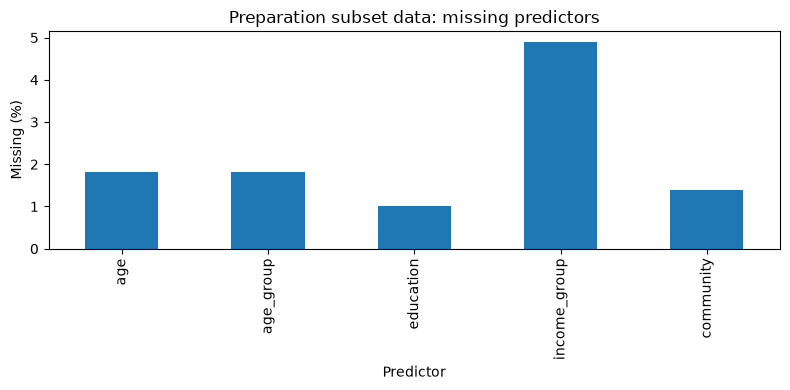

In [5]:
preparation_subset = combined.loc[combined['survey_year'].lt(2025)].copy()
features = ['age','age_group','education','income_group','community']
missing_report = preparation_subset[features].isna().agg(['sum','mean']).T.rename(columns={'sum':'missing_n','mean':'missing_fraction'})
display(missing_report)
print('Observed ages:', preparation_subset['age'].notna().sum())
ax = (missing_report['missing_fraction']*100).plot.bar(figsize=(8,4))
ax.set(title='Preparation subset data: missing predictors', xlabel='Predictor', ylabel='Missing (%)')
plt.tight_layout(); plt.show()


In [6]:
imputation_comparison = []
age_original = preparation_subset['age'].copy()
for name, series in {
    'Observed only': age_original.dropna(),
    'Mean fill': age_original.fillna(age_original.mean()),
    'Median fill': age_original.fillna(age_original.median()),
    'Mode fill (demonstration)': age_original.fillna(age_original.mode().iloc[0])
}.items():
    imputation_comparison.append({'strategy':name, 'n':series.size, 'missing':series.isna().sum(),
        'mean':series.mean(), 'median':series.median(), 'SD':series.std(ddof=1)})
display(pd.DataFrame(imputation_comparison))
print('Original predictor rows:', len(preparation_subset))
print('Rows after any-predictor dropna:', len(preparation_subset[features].dropna()))
print('Columns after dropna(axis=1):', preparation_subset[features].dropna(axis=1).columns.tolist())
age_imputer = SimpleImputer(strategy='median')
age_imputed = age_imputer.fit_transform(preparation_subset[['age']]).ravel()
community_mode = preparation_subset['community'].mode().iloc[0]
community_manual = preparation_subset['community'].fillna(community_mode)
community_imputed = SimpleImputer(strategy='most_frequent').fit_transform(preparation_subset[['community']]).ravel()
assert np.array_equal(community_manual.to_numpy(), community_imputed)
assert np.isfinite(age_imputed).all()
print('SimpleImputer learned median:', age_imputer.statistics_[0])


,strategy,n,missing,mean,median,SD
0,Observed only,11153,0,54.933829,57.0,17.677886
1,Mean fill,11359,0,54.933829,56.0,17.516840
2,Median fill,11359,0,54.971300,57.0,17.519010
3,Mode fill (demonstration),11359,0,55.170790,57.0,17.603408


Original predictor rows: 11359
Rows after any-predictor dropna: 10515


Columns after dropna(axis=1): []
SimpleImputer learned median: 57.0


##### **Outlier Flags and Decision Log**

- Apply |Z|>3 and 1.5×IQR fences to released numeric ages. 
- Use ddof=0 for Z-score SD. 
- Plausible older ages and the top-coded 98+ category are not automatically errors; investigate plots later in EDA. 
- Retain plausible ages and record the reasoning.

In [7]:
outlier_rows=[]
for year,group in preparation_subset.groupby('survey_year'):
    x=group['age'].dropna(); sd=x.std(ddof=0)
    z=(x-x.mean())/sd if sd>0 else pd.Series(0.,index=x.index)
    q1,q3=x.quantile([.25,.75]); iqr=q3-q1
    z_flag=z.abs().gt(3); iqr_flag=x.lt(q1-1.5*iqr)|x.gt(q3+1.5*iqr)
    outlier_rows.append({'year':year,'observed_n':len(x),'Z_abs_gt_3':int(z_flag.sum()),
        'IQR_and_boxplot_rule':int(iqr_flag.sum()),'overlap':int((z_flag&iqr_flag).sum()),
        'IQR_low':q1-1.5*iqr,'IQR_high':q3+1.5*iqr})
outlier_report=pd.DataFrame(outlier_rows); display(outlier_report)
print('Decision: retain plausible observed ages; no statistical outlier deletions.')


,year,observed_n,Z_abs_gt_3,IQR_and_boxplot_rule,overlap,IQR_low,IQR_high
0,2023,5640,0,0,0,-2.0,110.0
1,2024,5513,0,0,0,-3.5,112.5


Decision: retain plausible observed ages; no statistical outlier deletions.


In [8]:
decision_log=pd.DataFrame([
    {'step':'Source harmonization','decision':'Validate codes and align shared categories','reason':'Public releases differ by year'},
    {'step':'Missing codes','decision':'Recode per field, not with a global 99 rule','reason':'99 is refusal in AGE here; other fields require their own metadata'},
    {'step':'Numeric age','decision':'Mask refusal; flag top-coded 98+; leave 2025 unavailable','reason':'Do not invent observed ages'},
    {'step':'Imputation','decision':'Use separate demonstration copies','reason':'Inferential age tests require observed values'},
    {'step':'Outliers','decision':'Retain plausible observed age values','reason':'Statistical extremes can be valid'},
    {'step':'Analysis universe','decision':'Observed internet-user frequency answers','reason':'Do not equate unknown/nonuser with another frequency'}])
display(decision_log)
decision_log.to_csv(RESULTS_DIR/'preprocessing_decisions.csv',index=False)


,step,decision,reason
0,Source harmonization,Validate codes and align shared categories,Public releases differ by year
1,Missing codes,"Recode per field, not with a global 99 rule",99 is refusal in AGE here; other fields requir...
2,Numeric age,Mask refusal; flag top-coded 98+; leave 2025 u...,Do not invent observed ages
3,Imputation,Use separate demonstration copies,Inferential age tests require observed values
4,Outliers,Retain plausible observed age values,Statistical extremes can be valid
5,Analysis universe,Observed internet-user frequency answers,Do not equate unknown/nonuser with another fre...


##### **Reshape NPORS with melt()**

Here we reshape using 3 NPORS datasets.

1. We select six shared questions from all three survey years.
2. Uses melt() to change one row per respondent into one row per respondent–question response.
3. Converts answer codes into readable labels and identifies missing responses.
4. Attaches question descriptions and demographic information using validated merges.
5. Checks that no responses were lost or accidentally duplicated.

The result contains 98,286 response rows from 16,381 respondents. The extra rows represent separate questions—not additional people.

In [9]:
QUESTION_DEFINITIONS={
    'RADIO':('Listens to radio',{1:'Yes',2:'No'}),
    'NHISLL':('Working home landline',{1:'Yes',2:'No'}),
    'VOL12_CPS':('Volunteered in past 12 months',{1:'Yes',2:'No'}),
    'COMTYPE2':('Community type',COMM_LABELS),
    'ECON1MOD':('Current community economic conditions',{1:'Excellent',2:'Good',3:'Only fair',4:'Poor'}),
    'CRIMESAFE':('Neighborhood safety',{1:'Extremely safe',2:'Very safe',3:'Somewhat safe',4:'Not too safe',5:'Not at all safe'})
}
response_parts=[]; question_rows=[]; started=time.perf_counter()
for year in [2023,2024,2025]:
    frame=raw[year]
    wide=frame[list(QUESTION_DEFINITIONS)].copy()
    wide['respondent_key']=str(year)+':'+frame['RESPID'].astype('int64').astype(str)
    wide['survey_year']=year
    long=wide.melt(id_vars=['respondent_key','survey_year'],var_name='question_code',value_name='raw_response')
    assert len(long)==len(frame)*len(QUESTION_DEFINITIONS)
    long['question_code']=long['question_code'].str.strip().str.upper()
    long['question_display']=long['question_code'].str.lower().str.replace('_',' ',regex=False)
    # Missing response codes stay explicit; no missing question is converted to a no.
    long['response_status']=np.where(long['raw_response'].isna(),'System missing/skip',np.where(long['raw_response'].eq(99),'Refused/unknown','Observed'))
    long['response_label']=np.nan
    long['response_label']=long['response_label'].astype(object)
    for question,(description,labels) in QUESTION_DEFINITIONS.items():
        mask=long['question_code'].eq(question)
        long.loc[mask,'response_label']=checked_map(long.loc[mask,'raw_response'],labels,question)
        question_rows.append({'survey_year':year,'question_code':question,'description':description,
            'source_url':f'https://www.thearda.com/data-archive?fid=NPORS{str(year)[-2:]}&tab=2'})
    response_parts.append(long)
responses_long=pd.concat(response_parts,ignore_index=True)
questions=pd.DataFrame(question_rows)
assert not questions.duplicated(['survey_year','question_code']).any()
assert not responses_long.duplicated(['respondent_key','question_code']).any()
enriched=responses_long.merge(questions,on=['survey_year','question_code'],how='left',validate='many_to_one',indicator=True)
assert enriched['_merge'].eq('both').all()
enriched=enriched.drop(columns='_merge').merge(combined[['respondent_key','age_group','community']],on='respondent_key',how='left',validate='many_to_one',indicator=True)
assert enriched['_merge'].eq('both').all()
assert len(enriched)==len(responses_long)
reshape_metrics = pd.DataFrame([{
    'Respondents': len(combined),
    'Long Response Rows': len(responses_long),
    'Melt and Merge Time (seconds)': round(time.perf_counter() - started, 3)
}])
display(reshape_metrics)
response_summary = (
    enriched.groupby(['survey_year', 'question_code', 'description', 'response_status'])
    .size()
    .reset_index(name='response_count')
    .rename(columns={
        'survey_year': 'Survey Year',
        'question_code': 'Question Code',
        'description': 'Question',
        'response_status': 'Response Status',
        'response_count': 'Response Count'
    })
    .sort_values(['Survey Year', 'Question Code', 'Response Status'])
    .reset_index(drop=True)
)
display(response_summary)

,Respondents,Long Response Rows,Melt and Merge Time (seconds)
0,16381,98286,0.187


,Survey Year,Question Code,Question,Response Status,Response Count
0,2023,COMTYPE2,Community type,Observed,5654
1,2023,COMTYPE2,Community type,Refused/unknown,79
2,2023,CRIMESAFE,Neighborhood safety,Observed,5714
3,2023,CRIMESAFE,Neighborhood safety,Refused/unknown,19
4,2023,ECON1MOD,Current community economic conditions,Observed,5720
5,2023,ECON1MOD,Current community economic conditions,Refused/unknown,13
6,2023,NHISLL,Working home landline,Observed,5689
7,2023,NHISLL,Working home landline,Refused/unknown,44
8,2023,RADIO,Listens to radio,Observed,5687
9,2023,RADIO,Listens to radio,Refused/unknown,46


In [10]:
print('Selected wide question columns:', len(QUESTION_DEFINITIONS))
print('Expected long rows:', len(combined) * len(QUESTION_DEFINITIONS))
assert len(responses_long) == 16381 * 6 == 98286

response_preview = (
    responses_long[[
        'respondent_key', 'survey_year', 'question_code',
        'raw_response', 'response_label', 'response_status'
    ]]
    .head(8)
    .rename(columns={
        'respondent_key': 'Respondent Key',
        'survey_year': 'Survey Year',
        'question_code': 'Question Code',
        'raw_response': 'Raw Response',
        'response_label': 'Response Label',
        'response_status': 'Response Status'
    })
)
display(response_preview)

year_response_counts = (
    responses_long.groupby('survey_year')
    .size()
    .reset_index(name='long_response_rows')
    .rename(columns={
        'survey_year': 'Survey Year',
        'long_response_rows': 'Long Response Rows'
    })
)
display(year_response_counts)

Selected wide question columns: 6
Expected long rows: 98286


,Respondent Key,Survey Year,Question Code,Raw Response,Response Label,Response Status
0,2023:202302000906,2023,RADIO,2.0,No,Observed
1,2023:202302000710,2023,RADIO,2.0,No,Observed
2,2023:202302000488,2023,RADIO,1.0,Yes,Observed
3,2023:202302000665,2023,RADIO,1.0,Yes,Observed
4,2023:202302000840,2023,RADIO,1.0,Yes,Observed
5,2023:202302000638,2023,RADIO,2.0,No,Observed
6,2023:202302000317,2023,RADIO,2.0,No,Observed
7,2023:202302000662,2023,RADIO,1.0,Yes,Observed


,Survey Year,Long Response Rows
0,2023,34398
1,2024,33756
2,2025,30132


#### **Task 1.4 – Visualize the Reshaped NPORS Data**

Here we visualize the reshaped NPORS data using the radio-listening question (RADIO).

1. Selects the radio responses from the long-format table.
2. Counts Yes, No and missing responses for each year.
3. Uses observed Yes/No answers to create bar charts showing overall counts and comparisons across years.
4. Calculates the percentage answering Yes within each community type and survey year.
5. Displays those percentages in a heatmap.

The goal is to understand how radio listening varies by year and community, while distinguishing counts from percentages and using the correct denominator.

,survey_year,response_label,n
0,2023,No,1200
1,2023,Yes,4487
2,2023,NaN,46
3,2024,No,1255
4,2024,Yes,4340
5,2024,NaN,31
6,2025,No,1251
7,2025,Yes,3728
8,2025,NaN,43


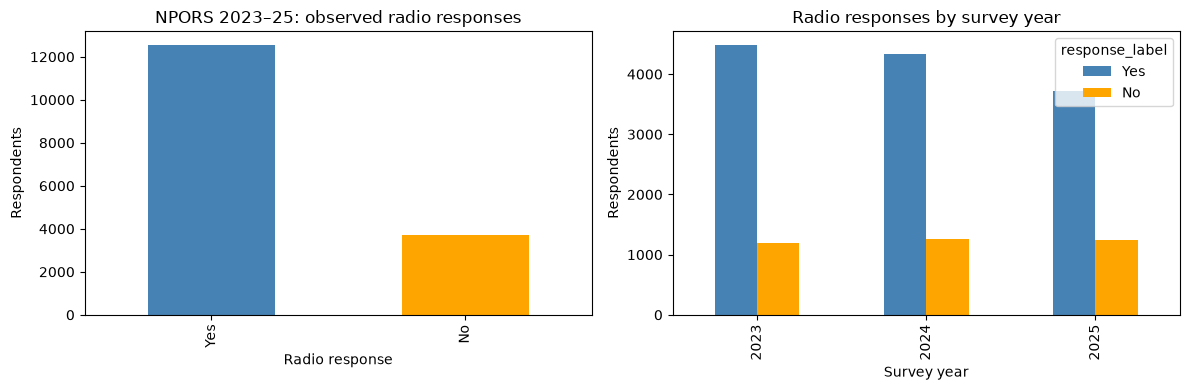

,survey_year,community,n,rate,percent
0,2023,Rural,1435,0.825784,82.578397
1,2023,Suburban,2703,0.792083,79.208287
2,2023,Urban,1472,0.745245,74.524457
3,2024,Rural,1245,0.824096,82.409639
4,2024,Suburban,2794,0.778454,77.845383
5,2024,Urban,1479,0.735632,73.563218
6,2025,Rural,1224,0.796569,79.656863
7,2025,Suburban,2316,0.750000,75.000000
8,2025,Urban,1381,0.703838,70.383780


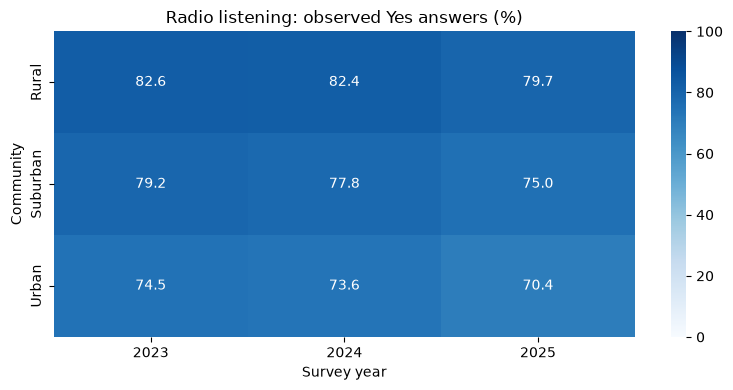

In [11]:
radio_long=enriched.loc[enriched['question_code'].eq('RADIO')].copy()
radio_counts=(radio_long.groupby(['survey_year','response_label'],dropna=False).size().rename('n').reset_index())
display(radio_counts)
observed_radio=radio_long.loc[radio_long['response_status'].eq('Observed')].copy()
radio_table=pd.crosstab(observed_radio['survey_year'],observed_radio['response_label']).reindex(columns=['Yes','No'],fill_value=0)
fig,axes=plt.subplots(1,2,figsize=(12,4))
observed_radio['response_label'].value_counts().reindex(['Yes','No']).plot.bar(ax=axes[0],color=['steelblue','orange'])
axes[0].set(title='NPORS 2023–25: observed radio responses',xlabel='Radio response',ylabel='Respondents')
radio_table.plot.bar(ax=axes[1],color=['steelblue','orange'])
axes[1].set(title='Radio responses by survey year',xlabel='Survey year',ylabel='Respondents')
plt.tight_layout(); plt.show()
radio_rate=observed_radio.assign(radio_yes=lambda x:x['response_label'].eq('Yes')).groupby(['survey_year','community'])['radio_yes'].agg(n='size',rate='mean').reset_index()
display(radio_rate.assign(percent=100*radio_rate['rate']))
heat=radio_rate.pivot(index='community',columns='survey_year',values='rate')*100
fig,ax=plt.subplots(figsize=(8,4))
sns.heatmap(heat,annot=True,fmt='.1f',cmap='Blues',vmin=0,vmax=100,ax=ax)
ax.set(title='Radio listening: observed Yes answers (%)',xlabel='Survey year',ylabel='Community')
plt.tight_layout(); plt.show()


**Observations and Reflection**


- The overall bar chart showed that more respondents answered Yes than No to radio listening.

- The grouped bar chart showed fewer Yes responses in later years. However, survey sample sizes also differed, so counts alone cannot establish a decline in listening rates.

- The heatmap showed the highest radio-listening percentages among rural respondents and the lowest among urban respondents. Percentages were lower in 2025 than in 2023 across all three community types—for example, rural respondents decreased from 82.6% to 79.7%.


- Counts show the number of respondents giving an answer. Proportions show that number relative to the group’s valid responses. Proportions make comparisons easier when group sizes differ. These charts show unweighted sample results, not population estimates.



- Missing answers are neither Yes nor No. Excluding them means the percentage is calculated among respondents who answered the question. For example, the 2023 denominator decreased from 5,733 to 5,687 after excluding 46 missing radio responses. Community comparisons also exclude respondents whose community type is missing.





##### **Age Distributions Before and After Imputation**

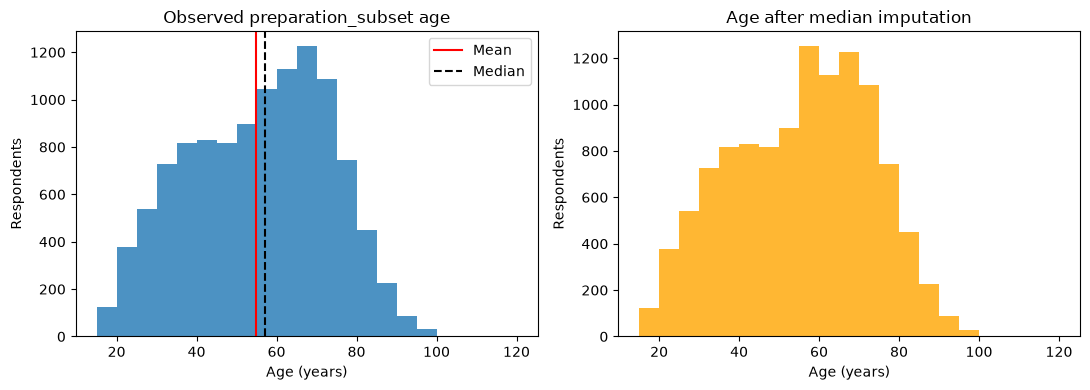

In [12]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].hist(age_original.dropna(), bins=np.arange(15,121,5), alpha=.8)
axes[0].axvline(age_original.mean(), color='red', label='Mean')
axes[0].axvline(age_original.median(), color='black', linestyle='--', label='Median')
axes[0].legend(); axes[0].set(title='Observed preparation_subset age',xlabel='Age (years)',ylabel='Respondents')
axes[1].hist(age_imputed, bins=np.arange(15,121,5), color='orange', alpha=.8)
axes[1].set(title='Age after median imputation',xlabel='Age (years)',ylabel='Respondents')
plt.tight_layout(); plt.show()


**Reflection**

The observed ages vary widely, with an average (mean) of approximately 54.93 years and a middle value (median) of 57 years. The mean being slightly below the median suggests some asymmetry toward younger ages.

Median imputation replaces all 206 missing ages with 57. This keeps every respondent in the demonstration dataset, but adds an artificial spike around age 57 because the same replacement is repeated—not because those respondents actually reported that age.

Imputation also reduces variance: the replacement ages are near the centre rather than spread across the age range. For example, the standard deviation decreases slightly from 17.68 to 17.52 years after median filling.

Therefore, filling missing ages preserves records but can make the distribution appear less variable than the unknown true ages might be.

##### **Category Distributions and Relationships**

,age,age_group,education,income_group,community
count,11153.000000,16119,16220,15595,16165
unique,NaN,4,3,6,3
top,NaN,65+,College graduate+,100k+,Suburban
freq,NaN,5665,7221,5118,7856
mean,54.933829,NaN,NaN,NaN,NaN
std,17.677886,NaN,NaN,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN
25%,40.000000,NaN,NaN,NaN,NaN
50%,57.000000,NaN,NaN,NaN,NaN
75%,69.000000,NaN,NaN,NaN,NaN


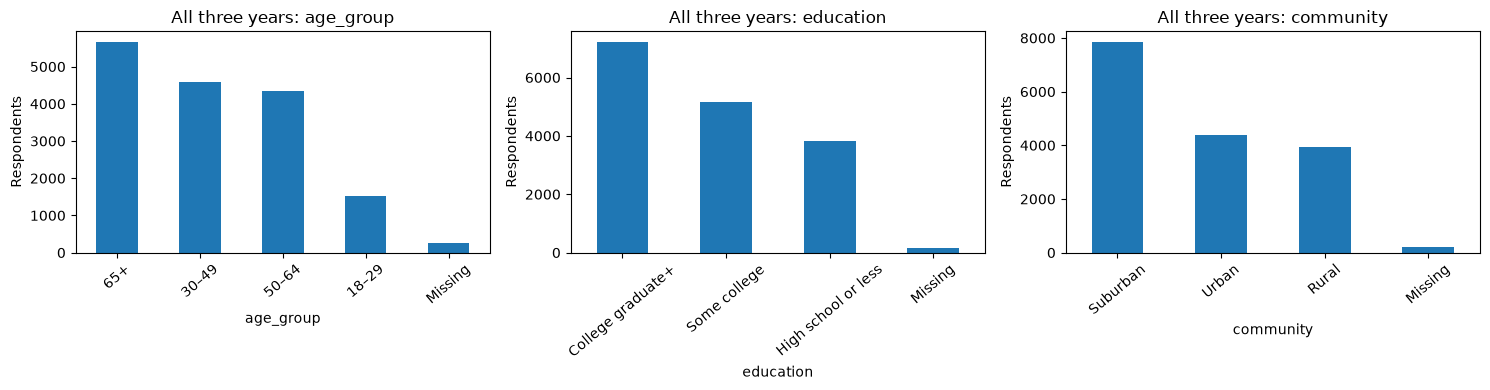

,n
almost_constant,
Other frequency,9489
Almost constantly,6111


,n,rate,percent
age_group,,,
18–29,1500,0.667333,66.733333
30–49,4543,0.581774,58.177416
50–64,4232,0.369329,36.932892
65+,5093,0.165914,16.591400
NaN,232,0.254310,25.431034


,n,rate,percent
education,,,
College graduate+,7139,0.456787,45.678666
High school or less,3326,0.311185,31.118461
Some college,5017,0.355790,35.579031
NaN,118,0.254237,25.423729


,n,rate,percent
income_group,,,
100k+,5077,0.480008,48.000788
30–40k,1388,0.331412,33.141210
40–50k,1272,0.355346,35.534591
50–70k,2140,0.349533,34.953271
70–100k,2421,0.383313,38.331268
<30k,2588,0.341190,34.119011
NaN,714,0.284314,28.431373


,n,rate,percent
community,,,
Rural,3666,0.310147,31.014730
Suburban,7604,0.396502,39.650184
Urban,4140,0.458454,45.845411
NaN,190,0.321053,32.105263


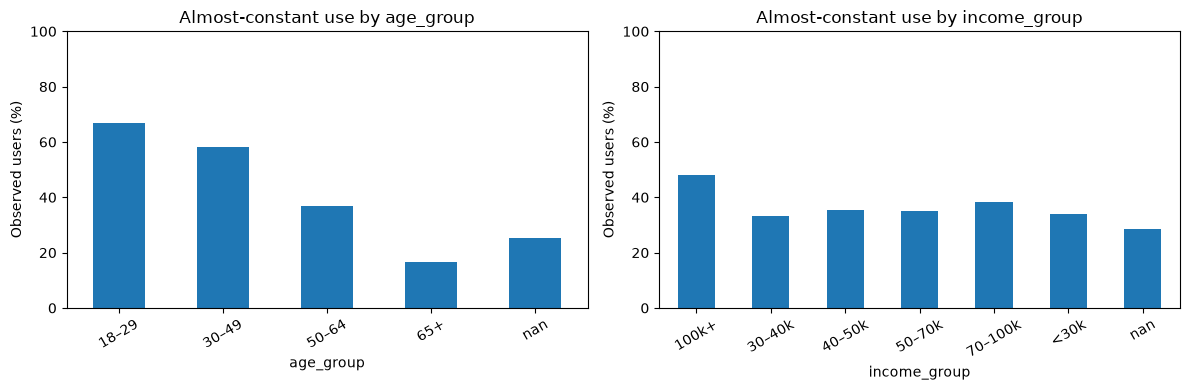

In [13]:
user_dev = combined.loc[combined['is_internet_user']].copy()
display(combined[features].describe(include='all'))
fig, axes=plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axes,['age_group','education','community']):
    combined[col].fillna('Missing').value_counts().plot.bar(ax=ax)
    ax.set(title=f'All three years: {col}',xlabel=col,ylabel='Respondents')
    ax.tick_params(axis='x',rotation=40)
plt.tight_layout(); plt.show()
display(user_dev['almost_constant'].value_counts().rename(index={0.:'Other frequency',1.:'Almost constantly'}).to_frame('n'))
group_rates={}
for col in ['age_group','education','income_group','community']:
    table=user_dev.groupby(col,dropna=False)['almost_constant'].agg(n='size',rate='mean')
    group_rates[col]=table
    display(table.assign(percent=100*table['rate']))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,col in zip(axes,['age_group','income_group']):
    table=group_rates[col]
    (100*table['rate']).plot.bar(ax=ax)
    ax.set(title=f'Almost-constant use by {col}',xlabel=col,ylabel='Observed users (%)',ylim=(0,100))
    ax.tick_params(axis='x',rotation=30)
plt.tight_layout(); plt.show()


##### **Visual Outlier Investigation**

Box plots use conventional IQR whiskers. The scatter plot displays ordinal frequency with slight jitter; its category codes are not continuous hours of internet use.

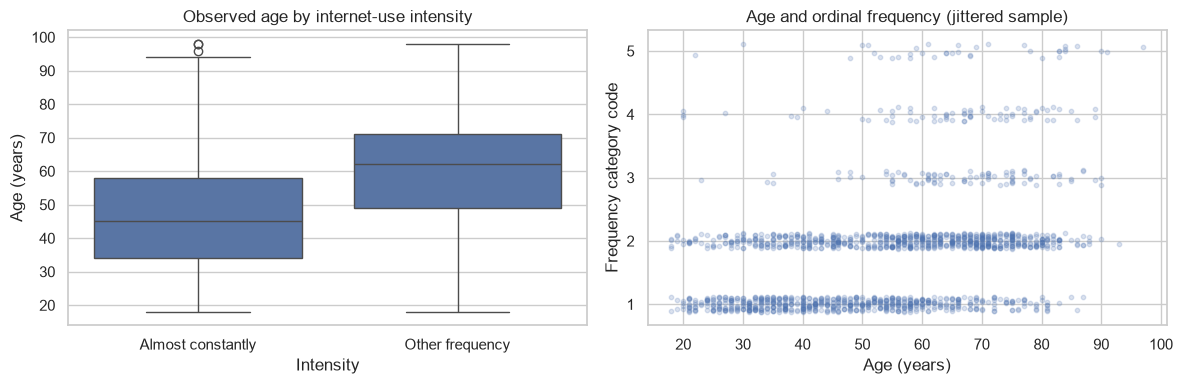

In [14]:
SEED = 42
ALPHA = 0.05
sns.set_theme(style='whitegrid')

observed=user_dev.dropna(subset=['age']).copy()
observed['intensity_label']=observed['almost_constant'].map({0.:'Other frequency',1.:'Almost constantly'})
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=observed,x='intensity_label',y='age',ax=axes[0])
axes[0].set(title='Observed age by internet-use intensity',xlabel='Intensity',ylabel='Age (years)')
sample=observed.sample(n=min(1500,len(observed)),random_state=SEED)
jitter=np.random.default_rng(SEED).uniform(-.12,.12,len(sample))
axes[1].scatter(sample['age'],sample['frequency_code']+jitter,alpha=.2,s=10)
axes[1].set(title='Age and ordinal frequency (jittered sample)',xlabel='Age (years)',ylabel='Frequency category code',yticks=list(range(1,6)))
plt.tight_layout(); plt.show()



#### **Task 1.5 – Inferential Statistics**

All tests are grouped here. Using 2024 only to avoid treating year changes as within-person changes and to keep numeric-age measurement consistent. Using one row per respondent, with observed responses. Imputed ages and melted duplicates are not entering these tests.




##### **The Question**

**Does Mean Age Differ by Internet-Use Intensity?**

H0: μ_almost-constant = μ_other-frequency. 

H1: the means differ.


μ (mu) means the population’s average age. The text after it identifies the group.
- μ_almost-constant: average age of internet users who report using it almost constantly.
- μ_other-frequency: average age of internet users who report using it at any of the other frequencies: several times daily, once daily, several times weekly, or less often.
“Other frequency” excludes nonusers and missing/refused answers.
The hypotheses mean:
- H0 (null hypothesis): The two groups have the same average age.
- H1 (alternative hypothesis): The two groups have different average ages.


Age measurement limitation: the released value 98 means 98 or older. It is retained as a lower-bound value and flagged, so age summaries and test results are approximate. The 2025 file has only age groups and cannot supply exact ages for this test.

In [15]:
display(pd.crosstab(combined['survey_year'],combined['age_status']))


age_status,Not released in 2025,Observed release age,Refused,Top-coded 98+
survey_year,,,,
2023,0,5631,93,9
2024,0,5508,113,5
2025,5022,0,0,0


,count,mean,median,std
almost_constant,,,,
0.0,3172,60.233922,63.0,16.211512
1.0,2109,45.568042,44.0,15.426257


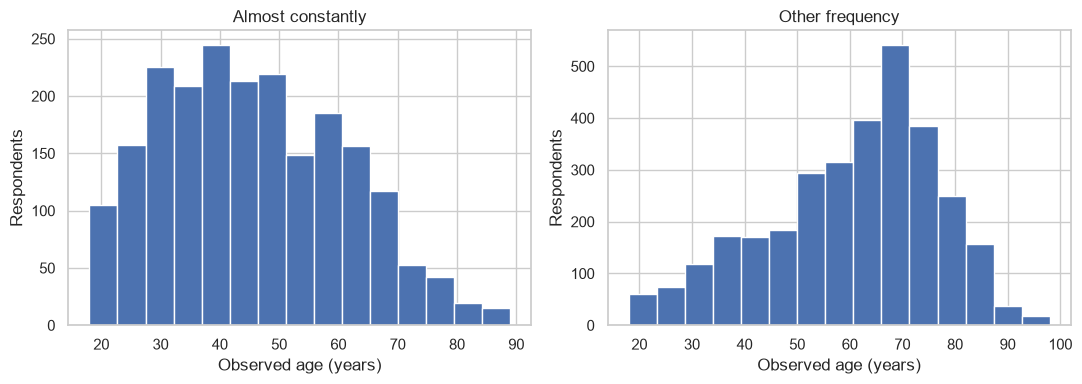

In [16]:
test_data=combined.loc[combined['survey_year'].eq(2024)&combined['is_internet_user']].copy()
numeric_test=test_data.dropna(subset=['age'])
a=numeric_test.loc[numeric_test['almost_constant'].eq(1),'age']
b=numeric_test.loc[numeric_test['almost_constant'].eq(0),'age']
assert min(len(a),len(b))>1
display(numeric_test.groupby('almost_constant')['age'].agg(['count','mean','median','std']))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,x,label in zip(axes,[a,b],['Almost constantly','Other frequency']):
    ax.hist(x,bins=15); ax.set(title=label,xlabel='Observed age (years)',ylabel='Respondents')
plt.tight_layout(); plt.show()


##### **Mandatory Normality Checks: Q–Q Plots and Shapiro–Wilk**


Completing these checks for each group before executing the t-test cell. 
In a Q–Q plot, approximately straight points support an approximately normal shape; examine skew, tails and unusual observations. 
For Shapiro–Wilk, H0 is that the sampled values follow a normal distribution; p<0.05 provides evidence against exact normality. p≥0.05 does not prove normality.

Running Shapiro on all available observations up to 5,000 per group. If a group is larger, use a fixed-seed random sample of 5,000 and report both sizes, because SciPy warns that larger-sample p-values may be inaccurate. Q–Q plots use the full observed group.



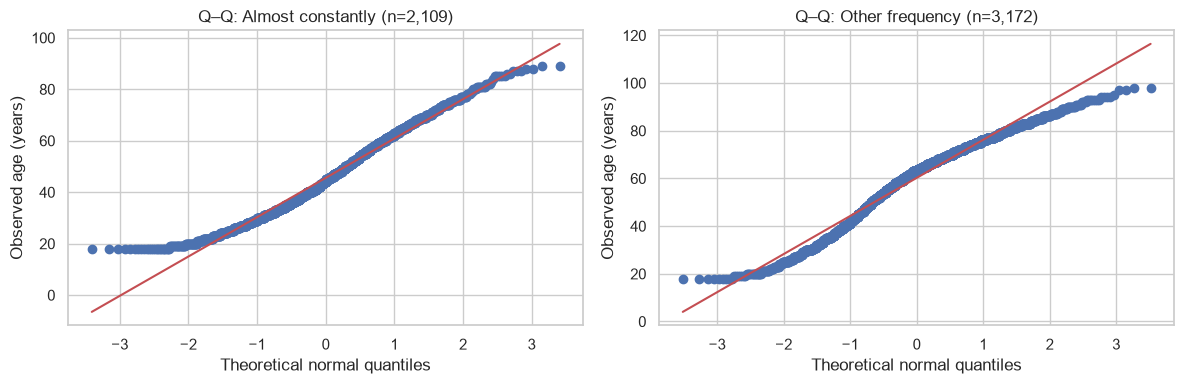

,group,full_n,shapiro_n,W,p_value,normality_decision
0,Almost constantly,2109,2109,0.978723,3.392817e-17,Evidence against exact normality
1,Other frequency,3172,3172,0.969569,2.043717e-25,Evidence against exact normality


In [17]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
normality_rows=[]
for offset,(ax,label,values) in enumerate(zip(axes,['Almost constantly','Other frequency'],[a,b])):
    x=np.asarray(values,dtype=float)
    assert len(x)>=3 and np.isfinite(x).all()
    stats.probplot(x,dist='norm',plot=ax)
    ax.set(title=f'Q–Q: {label} (n={len(x):,})',xlabel='Theoretical normal quantiles',ylabel='Observed age (years)')
    checked=np.random.default_rng(SEED+offset).choice(x,size=5000,replace=False) if len(x)>5000 else x
    shapiro=stats.shapiro(checked)
    normality_rows.append({'group':label,'full_n':len(x),'shapiro_n':len(checked),
        'W':shapiro.statistic,'p_value':shapiro.pvalue,
        'normality_decision':'Evidence against exact normality' if shapiro.pvalue<ALPHA else 'Insufficient evidence against normality'})
plt.tight_layout(); plt.show()
normality_report=pd.DataFrame(normality_rows)
display(normality_report)
normality_report.to_csv(RESULTS_DIR/'rq1_normality_checks.csv',index=False)
normality_checks_completed=True




##### Pre-Test Justification

The Q–Q plots show that ages follow the reference line reasonably closely in the centre, but depart from it in the tails. The departures are more noticeable in the **other-frequency** group, suggesting that neither group’s age distribution is exactly normal.

Shapiro–Wilk tests support this observation:

| Group | Sample size | W | p-value |
|---|---:|---:|---:|
| Almost-constant users | 2,109 | 0.9787 | 3.39 × 10⁻¹⁷ |
| Other-frequency users | 3,172 | 0.9696 | 2.04 × 10⁻²⁵ |

Both p-values are below **α = 0.05**, providing evidence against normality. However, Shapiro–Wilk is sensitive to departures from normality in large samples.

We will proceed with **Welch’s two-sample t-test** because both groups are large and observed ages are bounded. Large group sizes can make inference about means reasonably robust to non-normality. Welch’s test also allows unequal variances, although it does not correct non-normality itself.

The results must remain qualified: observations are treated as independent, missing ages are excluded, some ages are top-coded as 98+, and the calculation does not account for Pew’s complex survey design. 

In [18]:
assert normality_checks_completed, 'Run the mandatory Q–Q and Shapiro checks first.'
t_result=stats.ttest_ind(a,b,equal_var=False)
print(f'Welch t={t_result.statistic:.4f}, p={t_result.pvalue:.6g}, difference={a.mean()-b.mean():.2f} years')
print('Reject H0' if t_result.pvalue<ALPHA else 'Do not reject H0')


Welch t=-33.1531, p=1.26141e-216, difference=-14.67 years
Reject H0


####  Question Reflection

Among the analyzed 2024 respondents, almost-constant internet users had a mean age of **45.57 years**, compared with **60.23 years** for other-frequency users. Almost-constant users were therefore approximately **14.67 years younger on average**.

The Q–Q plots showed departures from normality, particularly in the tails, and both Shapiro–Wilk tests returned p-values below 0.05. Nevertheless, we proceeded with Welch’s t-test as a classroom approximation because both groups were large. Shapiro rejection alone does not automatically invalidate a t-test, and Welch’s method allows unequal variances.

The test produced **t ≈ −33.15** and **p ≈ 1.26 × 10⁻²¹⁶**. Under the test’s assumptions, we reject the null hypothesis of equal population mean ages. The estimated difference of 14.67 years describes the magnitude of the observed association; it does not establish that age causes internet-use intensity.

These findings require caution. The analysis excludes nonusers, unknown/refused frequency answers and missing ages, so respondents with observed answers may differ from those excluded. Ages recorded as 98+ also make age summaries approximate. Finally, the unweighted test does not account for Pew’s complex survey design. Large sample sizes do not correct that limitation, so the result should not be presented as design-corrected inference about all U.S. adults.

In [19]:
statistics_report = pd.DataFrame([{
    'question': 'RQ1',
    'test': 'Welch age vs intensity',
    'n_almost_constant': len(a),
    'n_other_frequency': len(b),
    'mean_almost_constant': a.mean(),
    'mean_other_frequency': b.mean(),
    'statistic': t_result.statistic,
    'p_value': t_result.pvalue,
    'effect': a.mean() - b.mean(),
    'effect_units': 'age years'
}])
statistics_report.to_csv(RESULTS_DIR / 'statistical_tests.csv', index=False)
display(statistics_report)


,question,test,n_almost_constant,n_other_frequency,mean_almost_constant,mean_other_frequency,statistic,p_value,effect,effect_units
0,RQ1,Welch age vs intensity,2109,3172,45.568042,60.233922,-33.153138,1.261411e-216,-14.66588,age years


---
## **Answer to the Research Question**

**The question that was asked was whether mean age differs between almost-constant internet users and users at other frequencies.** 


Among the analyzed 2024 respondents, the 2,109 almost-constant users had a mean age of 45.57 years, while the 3,172 other-frequency users had a mean age of 60.23 years. Almost-constant users were therefore approximately 14.67 years younger on average.

The age-distribution plots supported this difference. However, the Q–Q plots showed departures from normality, particularly in the tails, and both Shapiro–Wilk tests produced p-values below 0.05. These results indicate non-normal distributions but do not automatically invalidate every t-test. We used Welch’s t-test because both groups were large; Welch’s method also allows unequal variances.

The test returned t = −33.15, p < 0.001. Under its assumptions, we reject the null hypothesis of equal population mean ages. The age difference suggests a substantial association between age and internet-use intensity, without establishing causation.

We also take into account that preparation decisions matter when interpreting this result. Missing ages were excluded rather than imputed, preserving the distinction between observed and estimated values. Nevertheless, respondents with observed answers may differ from those excluded. Ages recorded as 98+ also make the means approximate. 

 Finally, the unweighted test does not account for Pew’s complex survey design. Large sample sizes do not resolve that limitation, so these findings should not be presented as design-corrected inference about all U.S. adults.

# **Section 2 – Billboard Dataset (Hot 100, 1958–2021)**

### Replicability Check

| Item | Detail |
|---|---|
| Python | 3.13 (virtual environment `.venv`) |
| Packages | `pip install -r requirements.txt` (uses `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`, `statsmodels`) |
| Run from | the `notebooks/` folder or the project root |
| Data | Neon tables `billboard_hot100_raw` and `billboard_audio_features_raw` (needs `NEON_DATABASE_URL` in `.env`, see the README) |
| Fallback | without `.env`, the notebook reads `data/billboard_hot100.csv` and `data/billboard_audio_features.csv`, which are committed to the repository |
| Source | TidyTuesday 2021-09-14 (`billboard.csv` and `audio_features.csv`) |

The data is already in the shared Neon database, so with a `.env` you can simply restart the kernel and choose **Run All**.

To load or refresh the data in Neon, run this once from the project root. It downloads the two files into `data/` first if they are missing, uploads them, and verifies the Neon copy matches:

```bash
PYTHONPATH=src python -m billboard_dataset.upload
```

Without a `.env`, the notebook reads the committed CSV files in `data/` instead, and the results are identical.

### **The Research Question**

> **Which characteristics of a song, known when it first enters the chart, help explain how many weeks it stays on the Billboard Hot 100?**

This section follows the Section 2 tasks (2.1–2.8) of the lab and then extends them:

1. **Tasks 2.1–2.8** – load, reshape with `melt()`, clean strings, handle missing values, rebuild chart dates, plot, and reflect.
2. **Feature engineering** – turn the weekly rows into one row per song with useful predictors.
3. **Hypothesis testing** – decide which predictors deserve a place in a linear regression.
4. **Linear regression** – compare a model with all features against one built from the tested features.

#### Why this dataset?
The original lab file covers only the year 2000. This file covers more than 60 years of weekly charts (327,895 weekly rows) and can be joined with Spotify audio features, which gives enough columns and rows for feature engineering and regression.

### **Setup**

In [20]:
from pathlib import Path
import ast
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from matplotlib import cbook
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Works from the project root and from the notebooks/ folder; put src/ on Python's search path.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from common.database import NeonDatabase  # shared Neon helper (all sections)
from billboard_dataset import read_billboard_csv, read_billboard_neon
from billboard_dataset.config import CHART_TABLE_NAME, AUDIO_TABLE_NAME

#### **Task 2.1 – Load and Inspect Billboard Data**

Two tables are loaded from the shared Neon database (or, without a `.env`, from the local CSV files):

- **Chart file** – one row per song per week on the chart.
- **Audio file** – one row per song with its Spotify genre and audio features.

The columns are inspected before anything is changed.

In [21]:
connection_string = NeonDatabase.read_connection_string()

if connection_string:
    db = NeonDatabase(connection_string)
    print("Connected to:", db.test_connection()[:60], "...")
    # Read both tables in their original row order (later steps keep the first of each duplicate)
    chart_raw, audio_raw = read_billboard_neon(db)
    data_source = f"Neon tables '{CHART_TABLE_NAME}' and '{AUDIO_TABLE_NAME}'"
    db.close()
else:
    print("WARNING: NEON_DATABASE_URL is not set in .env - reading the local CSV files instead of Neon.")
    chart_raw, audio_raw = read_billboard_csv()
    data_source = "local CSV files (fallback)"

print("Loaded from:", data_source)

print(f"chart_raw: {chart_raw.shape[0]:,} rows x {chart_raw.shape[1]} columns")
print(f"audio_raw: {audio_raw.shape[0]:,} rows x {audio_raw.shape[1]} columns")
print("\nChart columns:", list(chart_raw.columns))
print("\nAudio columns:", list(audio_raw.columns))
chart_raw.head()

Connected to: PostgreSQL 18.6 (653b019) on aarch64-unknown-linux-gnu, comp ...


Loaded from: Neon tables 'billboard_hot100_raw' and 'billboard_audio_features_raw'
chart_raw: 327,895 rows x 10 columns
audio_raw: 29,503 rows x 22 columns

Chart columns: ['url', 'week_id', 'week_position', 'song', 'performer', 'song_id', 'instance', 'previous_week_position', 'peak_position', 'weeks_on_chart']

Audio columns: ['song_id', 'performer', 'song', 'spotify_genre', 'spotify_track_id', 'spotify_track_preview_url', 'spotify_track_duration_ms', 'spotify_track_explicit', 'spotify_track_album', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'spotify_track_popularity']


,url,week_id,week_position,song,performer,song_id,instance,previous_week_position,peak_position,weeks_on_chart
0,http://www.billboard.com/charts/hot-100/1965-0...,7/17/1965,34,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,45.0,34,4
1,http://www.billboard.com/charts/hot-100/1965-0...,7/24/1965,22,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,34.0,22,5
2,http://www.billboard.com/charts/hot-100/1965-0...,7/31/1965,14,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,22.0,14,6
3,http://www.billboard.com/charts/hot-100/1965-0...,8/7/1965,10,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,14.0,10,7
4,http://www.billboard.com/charts/hot-100/1965-0...,8/14/1965,8,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,10.0,8,8


In [22]:
chart_raw.dtypes

url                           str
week_id                       str
week_position               int64
song                          str
performer                     str
song_id                       str
instance                    int64
previous_week_position    float64
peak_position               int64
weeks_on_chart              int64
dtype: object

In [23]:
audio_raw.head(3)

,song_id,performer,song,spotify_genre,spotify_track_id,spotify_track_preview_url,spotify_track_duration_ms,spotify_track_explicit,spotify_track_album,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,spotify_track_popularity
0,-twistin'-White Silver SandsBill Black's Combo,Bill Black's Combo,-twistin'-White Silver Sands,[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,¿Dònde Està Santa Claus? (Where Is Santa Claus...,Augie Rios,¿Dònde Està Santa Claus? (Where Is Santa Claus?),['novelty'],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,......And Roses And RosesAndy Williams,Andy Williams,......And Roses And Roses,"['adult standards', 'brill building pop', 'eas...",3tvqPPpXyIgKrm4PR9HCf0,https://p.scdn.co/mp3-preview/cef4883cfd1e0e53...,166106.0,False,The Essential Andy Williams,0.154,0.185,5.0,-14.063,1.0,0.0315,0.911,0.000267,0.112,0.15,83.969,4.0,38.0


**What the inspection shows**

- The chart file is already **long**: each row is a song-week with `week_position` (the rank), `weeks_on_chart` (a running count) and `peak_position` (best rank so far).
- `week_id` is stored as text such as `7/17/1965`, so it must be converted to a date.
- `spotify_genre` is a list written as text, for example `['pop', 'post-teen pop']`.
- The audio file has `NA` values for songs without a Spotify match.
- **Identifier columns:** `song_id`, `song`, `performer`. **Measured columns:** `week_position` and the weekly counters.

In [24]:
# Quick quality checks that guide later decisions.
print("Unique songs in chart file:", chart_raw["song_id"].nunique())
print("Unique songs in audio file:", audio_raw["song_id"].nunique())
print("Duplicated song_id in audio file:", audio_raw["song_id"].duplicated().sum())
print("Songs charted more than once (instance > 1):",
      chart_raw.loc[chart_raw["instance"] > 1, "song_id"].nunique())
print("\nMissing values per column (chart):")
print(chart_raw.isna().sum()[lambda s: s > 0])

Unique songs in chart file: 29389
Unique songs in audio file: 29386
Duplicated song_id in audio file: 117
Songs charted more than once (instance > 1): 2102

Missing values per column (chart):
previous_week_position    31954
dtype: int64


**Duplicate check.** A song should appear only once per chart week, and the audio file should have one row per song. Both rules are tested before any analysis, because duplicated rows would be counted twice in every statistic.

In [25]:
chart_rows_loaded, audio_rows_loaded = len(chart_raw), len(audio_raw)

chart_dup_keys = chart_raw.duplicated(subset=["song_id", "week_id"]).sum()
audio_dup_rows = audio_raw.duplicated().sum()
audio_dup_ids = audio_raw["song_id"].duplicated().sum()
print("Chart: exact duplicate rows       :", chart_raw.duplicated().sum())
print("Chart: repeated (song, week) pairs:", chart_dup_keys)
print("Audio: exact duplicate rows       :", audio_dup_rows)
print("Audio: repeated song_id           :", audio_dup_ids)

# Show a few repeated chart pairs side by side (keep=False marks every copy).
chart_raw[chart_raw.duplicated(subset=["song_id", "week_id"], keep=False)] \
    .sort_values(["song_id", "week_id"])[["song", "performer", "week_id", "week_position", "instance", "weeks_on_chart"]].head(6)

Chart: exact duplicate rows       : 0
Chart: repeated (song, week) pairs: 13
Audio: exact duplicate rows       : 24
Audio: repeated song_id           : 117


,song,performer,week_id,week_position,instance,weeks_on_chart
91436,Unchained Melody,The Righteous Brothers,10/13/1990,15,3,22
91437,Unchained Melody,The Righteous Brothers,10/13/1990,30,3,23
91438,Unchained Melody,The Righteous Brothers,10/20/1990,13,3,24
91439,Unchained Melody,The Righteous Brothers,10/20/1990,25,3,25
91440,Unchained Melody,The Righteous Brothers,10/27/1990,15,3,26
91441,Unchained Melody,The Righteous Brothers,10/27/1990,22,3,27


In [26]:
# Keep the first row of every repeated (song, week) pair.
chart_raw = chart_raw.drop_duplicates(subset=["song_id", "week_id"]).reset_index(drop=True)
print(f"Chart rows: {chart_rows_loaded:,} -> {len(chart_raw):,} ({chart_rows_loaded - len(chart_raw)} removed)")

Chart rows: 327,895 -> 327,882 (13 removed)


**Result.**
- **Chart file:** there are no exact duplicate rows, but **13 (song, week) pairs appear twice** (for example *Unchained Melody* by The Righteous Brothers appears twice in the week of 10/13/1990, at ranks 15 and 30, because two versions share one `song_id`). Only the first row of each pair was kept, so 13 of 327,895 rows (0.004 %) were removed.
- **Audio file:** **117 `song_id` values are repeated** (24 of them are exact duplicate rows; the others are the same song listed with slightly different Spotify entries). One row per song is kept, which leaves 29,386 songs.

#### **Task 2.2 – Diagnose the Tidiness Problem**

The chart file is already tidy (one observation per row). The lab, however, is about the **wide** layout in which every week is a column (`1st week`, `2nd week`, ...). To practise the same reshaping, a wide table is built first: **one row per song and one column per week on the chart** (first 20 weeks, first run of each song).

Why the wide layout is hard to analyze:

- The week number is stored in the column **names**, not in a column that can be filtered, grouped or plotted.
- Most cells are empty because most songs leave the chart before week 20.
- A single plot of rank against week needs 20 columns to be selected by hand.

| Role | Columns |
|---|---|
| Identifiers (`id_vars`) | `song_id`, `song`, `performer` |
| Weekly measured columns (`value_vars`) | `1st week` ... `20th week` |
| Wanted after reshaping | `Week` (number) and `Rank` |

In [27]:
MAX_WEEKS = 20

def ordinal(n):
    """Return 1 -> '1st', 2 -> '2nd', 11 -> '11th'."""
    suffix = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    return f"{n}{suffix}"

# First run of each song only (instance == 1) so the week counter is continuous.
first_run = chart_raw[(chart_raw["instance"] == 1) & (chart_raw["weeks_on_chart"] <= MAX_WEEKS)]

billboard_wide = (
    first_run
    .pivot_table(index=["song_id", "song", "performer"],
                 columns="weeks_on_chart", values="week_position", aggfunc="first")
    .rename(columns=lambda n: f"{ordinal(n)} week")
    .reset_index()
)
billboard_wide.columns.name = None
print("Wide table shape:", billboard_wide.shape)
billboard_wide.head()

Wide table shape: (29385, 23)


,song_id,song,performer,1st week,2nd week,3rd week,4th week,5th week,6th week,7th week,8th week,9th week,10th week,11th week,12th week,13th week,14th week,15th week,16th week,17th week,18th week,19th week,20th week
0,"""B"" GirlsYoung And Restless","""B"" Girls",Young And Restless,84.0,78.0,68.0,60.0,58.0,55.0,54.0,57.0,67.0,75.0,77.0,79.0,79.0,83.0,91.0,NaN,NaN,NaN,NaN,NaN
1,"""Cherry Cherry"" from Hot August NightNeil Diamond","""Cherry Cherry"" from Hot August Night",Neil Diamond,84.0,64.0,56.0,49.0,42.0,36.0,35.0,31.0,31.0,51.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"""Having A Party"" MedleyThe Ovations (Featuring...","""Having A Party"" Medley",The Ovations (Featuring Louis Williams),99.0,95.0,87.0,79.0,73.0,70.0,63.0,56.0,62.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"""Joy"" Pt. IIsaac Hayes","""Joy"" Pt. I",Isaac Hayes,72.0,62.0,44.0,36.0,33.0,31.0,30.0,30.0,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"""Roots"" MedleyQuincy Jones","""Roots"" Medley",Quincy Jones,87.0,76.0,66.0,64.0,61.0,57.0,83.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### **Task 2.3 – Reshape with `melt()`**

`melt()` moves the 20 week columns into two columns: `Week` (the old column name) and `Rank` (the cell value). The identifier columns stay as they are.

In [28]:
id_vars = ["song_id", "song", "performer"]
week_cols = [c for c in billboard_wide.columns if c.endswith("week")]

billboard_long = billboard_wide.melt(
    id_vars=id_vars, value_vars=week_cols, var_name="Week", value_name="Rank"
)

print("Wide shape:", billboard_wide.shape, "-> Long shape:", billboard_long.shape)
print("Expected rows = songs x week columns =", billboard_wide.shape[0] * len(week_cols))
billboard_long.head(10)

Wide shape: (29385, 23) -> Long shape: (587700, 5)
Expected rows = songs x week columns = 587700


,song_id,song,performer,Week,Rank
0,"""B"" GirlsYoung And Restless","""B"" Girls",Young And Restless,1st week,84.0
1,"""Cherry Cherry"" from Hot August NightNeil Diamond","""Cherry Cherry"" from Hot August Night",Neil Diamond,1st week,84.0
2,"""Having A Party"" MedleyThe Ovations (Featuring...","""Having A Party"" Medley",The Ovations (Featuring Louis Williams),1st week,99.0
3,"""Joy"" Pt. IIsaac Hayes","""Joy"" Pt. I",Isaac Hayes,1st week,72.0
4,"""Roots"" MedleyQuincy Jones","""Roots"" Medley",Quincy Jones,1st week,87.0
5,"""Yep!""Duane Eddy His Twangy Guitar And The Rebels","""Yep!""",Duane Eddy His Twangy Guitar And The Rebels,1st week,99.0
6,#1 Dee JayGoody Goody,#1 Dee Jay,Goody Goody,1st week,88.0
7,#1Nelly,#1,Nelly,1st week,75.0
8,#9 DreamJohn Lennon,#9 Dream,John Lennon,1st week,68.0
9,#BeautifulMariah Carey Featuring Miguel,#Beautiful,Mariah Carey Featuring Miguel,1st week,24.0


#### **Task 2.4 – Clean the Week Labels with String Operations**

The `Week` values look like `1st week`. The steps are:

| Step | Method | Purpose |
|---|---|---|
| 1 | `.str.strip()` | remove stray spaces |
| 2 | `.str.lower()` | one consistent case |
| 3 | `.str.replace(" week", "")` | drop the repeated word |
| 4 | `.str.extract(r"(\d+)")` | keep only the digits |

The result is converted to an integer, so weeks can be sorted and used in arithmetic.

In [29]:
week_clean = (
    billboard_long["Week"]
    .str.strip()
    .str.lower()
    .str.replace(" week", "", regex=False)
)
billboard_long["WeekNumber"] = (
    week_clean.str.extract(r"(\d+)", expand=False).astype("int64")
)

print(billboard_long[["Week", "WeekNumber"]].drop_duplicates().head(8))
print("WeekNumber dtype:", billboard_long["WeekNumber"].dtype)
assert billboard_long["WeekNumber"].between(1, MAX_WEEKS).all()

            Week  WeekNumber
0       1st week           1
29385   2nd week           2
58770   3rd week           3
88155   4th week           4
117540  5th week           5
146925  6th week           6
176310  7th week           7
205695  8th week           8
WeekNumber dtype: int64


The same string tools help with the performer names. Songs with a guest artist are written in several ways (`Featuring`, `feat.`, `With`, `x`). A flag is created now because it is used later as a feature. Duo names such as `Hall & Oates` are *not* flagged, because they are one act.

In [30]:
collab_pattern = r"\b(?:featuring|feat\.?|with|duet|x)\b"
billboard_long["performer_clean"] = (
    billboard_long["performer"].str.strip().str.replace(r"\s+", " ", regex=True)
)
billboard_long["is_collab"] = billboard_long["performer_clean"].str.lower().str.contains(
    collab_pattern, regex=True
)
billboard_long[["performer_clean", "is_collab"]].drop_duplicates().query("is_collab").head(5)

,performer_clean,is_collab
2,The Ovations (Featuring Louis Williams),True
9,Mariah Carey Featuring Miguel,True
11,will.i.am Featuring Justin Bieber,True
12,Lil Dicky Featuring Fetty Wap & Rich Homie Quan,True
13,Jay-Z Featuring Beyonce Knowles,True


#### **Task 2.5 – Clean Ranking Values and Missing Data**

`Rank` is converted with `pd.to_numeric()` and the missing values are counted.

**Decision:** the empty ranks are **dropped, not filled**. An empty cell means the song was *not on the chart* that week (it had already left). Filling it with a mean or with 0 would invent chart positions that never happened.

In [31]:
billboard_long["Rank"] = pd.to_numeric(billboard_long["Rank"], errors="coerce")

n_missing = billboard_long["Rank"].isna().sum()
print(f"Missing ranks: {n_missing:,} of {len(billboard_long):,} ({n_missing / len(billboard_long):.1%})")

billboard_ranked = billboard_long.dropna(subset=["Rank"]).copy()
billboard_ranked["Rank"] = billboard_ranked["Rank"].astype(int)
print(f"Rows kept: {len(billboard_ranked):,}")
print("Ranks within 1-100:", billboard_ranked["Rank"].between(1, 100).all())

Missing ranks: 297,639 of 587,700 (50.6%)
Rows kept: 290,061
Ranks within 1-100: True


**Missing audio features.** The audio file has a different kind of missing data: songs without a Spotify match have `NA` in *every* audio column at once.

In [32]:
audio = audio_raw.drop_duplicates(subset="song_id").copy()   # one row per song (see the duplicate check in Task 2.1)
audio_cols = ["danceability", "energy", "key", "loudness", "mode", "speechiness",
              "acousticness", "instrumentalness", "liveness", "valence", "tempo",
              "time_signature", "spotify_track_duration_ms", "spotify_track_popularity"]

missing_pct = audio[audio_cols + ["spotify_track_explicit", "spotify_genre"]].isna().mean().mul(100).round(1)
print(missing_pct.to_string())

# Are the audio columns missing together?
print("\nSongs with ALL audio columns missing:", audio[audio_cols].isna().all(axis=1).sum())
print("Songs with SOME (but not all) missing:",
      (audio[audio_cols].isna().any(axis=1) & ~audio[audio_cols].isna().all(axis=1)).sum())

danceability                 17.6
energy                       17.6
key                          17.6
loudness                     17.6
mode                         17.6
speechiness                  17.6
acousticness                 17.6
instrumentalness             17.6
liveness                     17.6
valence                      17.6
tempo                        17.6
time_signature               17.6
spotify_track_duration_ms    17.3
spotify_track_popularity     17.3
spotify_track_explicit       17.3
spotify_genre                 5.4

Songs with ALL audio columns missing: 5094
Songs with SOME (but not all) missing: 71


**Decision for audio features.** The values are missing as a block (no Spotify match), not one at a time. Imputing a mean or median would give hundreds of songs an identical, made-up sound profile. Therefore:

- songs are **kept** for the chart analysis (Tasks 2.6–2.7), and
- for the regression, only songs with audio features (**complete cases**) are used. The notebook later checks whether the missing songs are mostly old, because that affects how far results can be generalised.

Missing genres (`[]`, an empty list) are labelled `Unknown`.

**Impossible values.** Spotify features are measured by an algorithm, so errors look like physically impossible numbers (a tempo of 0 BPM, a time signature of 0). They are errors, not unusual songs, so they are checked against plausible ranges, in the same way as the zero-valued glucose and mileage readings in the other sections.

In [33]:
plausible_ranges = {                       # (lowest, highest) value a real song can have
    "tempo": (30, 250),                    # beats per minute
    "time_signature": (1, 7),
    "spotify_track_duration_ms": (20_000, 1_800_000),   # 20 seconds to 30 minutes
    "loudness": (-60, 5),                  # decibels
    "key": (0, 11),
    **{c: (0, 1) for c in ["danceability", "energy", "speechiness", "acousticness",
                           "instrumentalness", "liveness", "valence"]},
}
rows = []
for col, (low, high) in plausible_ranges.items():
    values = audio[col].dropna()
    rows.append({"feature": col, "allowed_min": low, "allowed_max": high,
                 "observed_min": values.min(), "observed_max": values.max(),
                 "below_min": int((values < low).sum()), "above_max": int((values > high).sum())})
plausibility = pd.DataFrame(rows).set_index("feature")
plausibility["total_invalid"] = plausibility["below_min"] + plausibility["above_max"]
audio_missing_before = int(audio[audio_cols].isna().sum().sum())
plausibility.round(2)

,allowed_min,allowed_max,observed_min,observed_max,below_min,above_max,total_invalid
feature,,,,,,,
tempo,30,250,0.00,241.01,1,0,1
time_signature,1,7,0.00,5.00,2,0,2
spotify_track_duration_ms,20000,1800000,29688.00,3079157.00,0,1,1
loudness,-60,5,-28.03,2.29,0,0,0
key,0,11,0.00,11.00,0,0,0
danceability,0,1,0.00,0.99,0,0,0
energy,0,1,0.00,1.00,0,0,0
speechiness,0,1,0.00,0.95,0,0,0
acousticness,0,1,0.00,0.99,0,0,0


In [34]:
# Recode impossible values as missing (the song stays in the table; the model uses complete cases).
for col, (low, high) in plausible_ranges.items():
    audio.loc[~audio[col].between(low, high) & audio[col].notna(), col] = np.nan
audio_missing_after = int(audio[audio_cols].isna().sum().sum())
print("Impossible values recoded to missing:", audio_missing_after - audio_missing_before)

Impossible values recoded to missing: 4


**Result.** Only **4 impossible values** were found among 29,386 songs: a tempo of 0 BPM (1 song), a time signature of 0 (2 songs) and a track longer than 30 minutes (1 song). They were recoded to missing instead of being imputed, because a value that cannot exist tells nothing about the song. All other features stay inside their plausible ranges (loudness reaches +2.3 dB, which is possible). The effect is small, but without this check a tempo of 0 would have entered the regression as a real measurement.

##### Validation of the cleaning steps

Before and after for the checks above:

In [35]:
validation = pd.DataFrame({
    "before": [chart_rows_loaded, chart_dup_keys, audio_rows_loaded, audio_dup_ids, audio_missing_before],
    "after":  [len(chart_raw), chart_raw.duplicated(subset=["song_id", "week_id"]).sum(),
               len(audio), audio.duplicated(subset="song_id").sum(), audio_missing_after],
}, index=["chart rows", "chart repeated (song, week) pairs", "audio rows",
          "audio repeated song_id", "audio missing numeric cells"])
assert validation.loc["chart repeated (song, week) pairs", "after"] == 0
assert validation.loc["audio repeated song_id", "after"] == 0
assert billboard_ranked["Rank"].between(1, 100).all()
validation

,before,after
chart rows,327895,327882
"chart repeated (song, week) pairs",13,0
audio rows,29503,29386
audio repeated song_id,117,0
audio missing numeric cells,72128,72132


#### **Task 2.6 – Date Enhancement**

The chart date of each weekly observation is rebuilt from the song's debut date:

$$
\text{chart date} = \text{debut date} + (\text{week number} - 1) \times 7\ \text{days}
$$

The `-1` matters: week 1 is the debut week itself, so it adds zero days. Without it every date would be one week late (an off-by-one error).

The rebuilt dates are compared with the real chart dates in the file.

In [36]:
chart = chart_raw.copy()
chart["chart_date"] = pd.to_datetime(chart["week_id"], format="%m/%d/%Y")

# Debut = the first week a song appears in the file (21 songs already show a week counter above 1 on that row).
debut = (
    chart.sort_values("chart_date")
    .groupby("song_id", as_index=False)
    .first()[["song_id", "chart_date", "week_position"]]
    .rename(columns={"chart_date": "debut_date", "week_position": "debut_position"})
)

dated = billboard_ranked.merge(debut[["song_id", "debut_date"]], on="song_id", how="left")
dated["chart_date_calc"] = dated["debut_date"] + pd.to_timedelta((dated["WeekNumber"] - 1) * 7, unit="D")

# Compare with the real date for the same song and week count.
real = first_run[["song_id", "weeks_on_chart"]].assign(
    chart_date_real=pd.to_datetime(first_run["week_id"], format="%m/%d/%Y")
)
dated = dated.merge(real, left_on=["song_id", "WeekNumber"], right_on=["song_id", "weeks_on_chart"], how="left")

mismatch = (dated["chart_date_calc"] != dated["chart_date_real"]).sum()
print(f"Rows checked: {len(dated):,}")
print(f"Rows where calculated date differs from the real date: {mismatch:,} ({mismatch / len(dated):.2%})")
print("Date range:", dated["chart_date_calc"].min().date(), "->", dated["chart_date_calc"].max().date())

Rows checked: 290,061
Rows where calculated date differs from the real date: 173 (0.06%)
Date range: 1958-08-02 -> 2021-05-29


In [37]:
# Look at the differences: are they off by one week, or gaps in the chart history?
diff_days = (dated["chart_date_real"] - dated["chart_date_calc"]).dt.days
print(diff_days[diff_days != 0].value_counts().head(6))

-49    46
-21    29
-7     23
-28    23
-35    15
-42    14
Name: count, dtype: int64


**Result.** The calculated date matches the real chart date for 290,061 − 173 rows; only **173 rows (0.06 %)** differ. All differences are exact multiples of 7 days and negative (the real date is *earlier* than the calculated one). They come from 21 songs whose first row in the file already has a week counter above 1 (they entered the chart before the file starts counting them), so the "debut date" used in the formula is really week 2, 3, ... of their run. The `- 1` in the formula is therefore correct; the remaining differences are a data-quality limitation, not an off-by-one error. The `debut_date` of those 21 songs is only approximate.

#### **Task 2.7 – Billboard Visualization and Trend Analysis**

Two plots:

1. **Rank trajectories** of a few songs. A smaller number is a better rank, so the y-axis is inverted: the best position is at the top.
2. **Distribution of peak position by decade.**

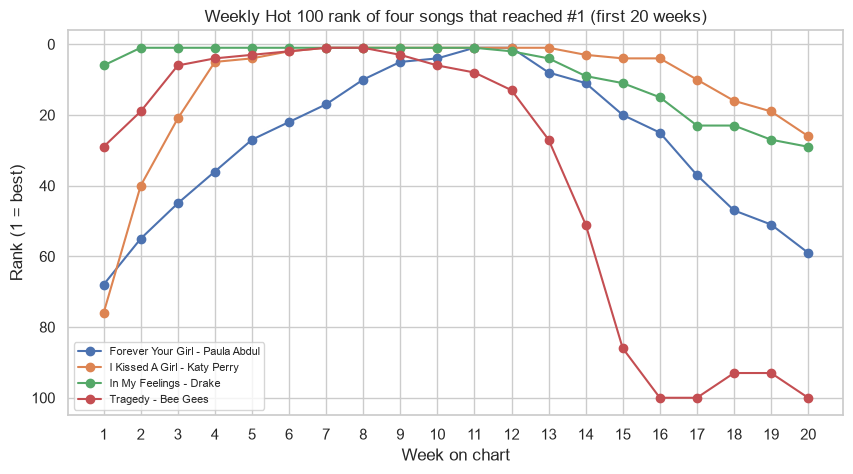

In [38]:
# Pick the three songs that stayed longest in their first 20 weeks and reached #1 (clear, readable lines).
top_songs = (
    billboard_ranked.groupby("song_id")["Rank"].agg(["min", "count"])
    .query("`min` == 1 and `count` == @MAX_WEEKS").sample(4, random_state=RANDOM_STATE).index
)
fig, ax = plt.subplots(figsize=(10, 5))
for sid, grp in billboard_ranked[billboard_ranked["song_id"].isin(top_songs)].groupby("song_id"):
    label = f"{grp['song'].iloc[0][:30]} - {grp['performer'].iloc[0][:20]}"
    ax.plot(grp["WeekNumber"], grp["Rank"], marker="o", label=label)
ax.invert_yaxis()
ax.set_xlabel("Week on chart")
ax.set_ylabel("Rank (1 = best)")
ax.set_title("Weekly Hot 100 rank of four songs that reached #1 (first 20 weeks)")
ax.set_xticks(range(1, MAX_WEEKS + 1, 1))
ax.legend(fontsize=8)
plt.show()

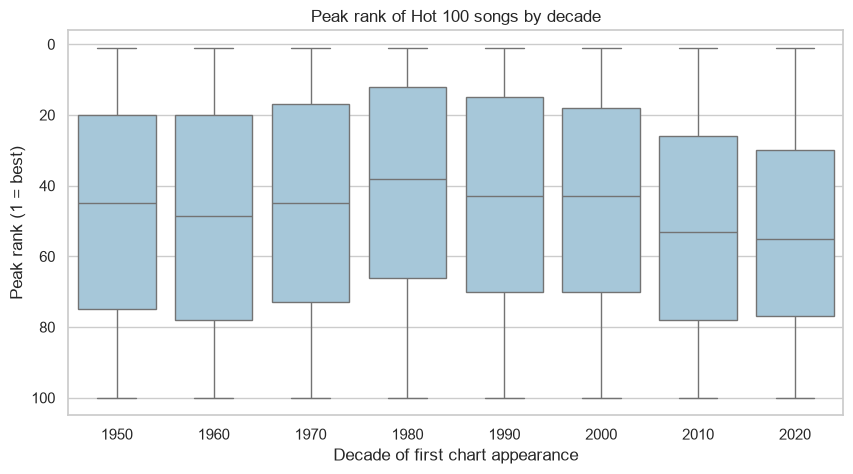

In [39]:
peaks = chart_raw.groupby("song_id").agg(peak=("week_position", "min"), first_year=("week_id", lambda s: pd.to_datetime(s, format="%m/%d/%Y").min().year))
peaks["decade"] = (peaks["first_year"] // 10 * 10).astype(int)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=peaks, x="decade", y="peak", ax=ax, color="#9ecae1")
ax.invert_yaxis()
ax.set_xlabel("Decade of first chart appearance")
ax.set_ylabel("Peak rank (1 = best)")
ax.set_title("Peak rank of Hot 100 songs by decade")
plt.show()

**What the plots show**

- **Trajectories:** the four songs rise to #1 at different speeds (Drake and Katy Perry jump in within one to four weeks; Paula Abdul climbs for 11 weeks) and then decline. `Tragedy` falls out of the top 50 by week 15 and sits at rank 100 for weeks 16–20, which is typical of a song that peaks quickly and fades.
- **Peak rank by decade:** the typical (median) peak is best for songs that debuted in the 1980s (about rank 38) and gets worse in the 2010s and 2020s (about rank 53–55). The 2020s box is based on only about a year and a half of data, so it should not be over-interpreted.

#### **Task 2.8 – Billboard Reflection**

**1. Why was `melt()` appropriate for the weekly ranking columns?**
The week number was stored in 20 column names (`1st week` ... `20th week`) and the cell values were ranks. `melt()` moves the names into a `Week` column and the values into a `Rank` column, so there is one row per song per week. That layout can be filtered, grouped and plotted directly.

**2. Which string operations did you use and what did each accomplish?**
- `.str.strip()` removed stray spaces.
- `.str.lower()` made the text a single case.
- `.str.replace(" week", "")` removed the repeated word.
- `.str.extract(r"(\d+)")` kept only the digits of the week number.
- `.str.contains()` with a regular expression flagged guest artists in the performer name.

**3. Why should the cleaned week number be numeric?**
Text sorts alphabetically (`"10th"` comes before `"2nd"`), cannot be used in arithmetic, and plots in the wrong order. As an integer it sorts correctly and can be used to calculate dates (`debut date + (week − 1) × 7 days`).

**4. How did you handle missing ranking values, and why?**
There were 297,639 empty ranks out of 587,700 cells (50.6 %). I dropped them because an empty cell means the song was not on the chart that week. Filling them would invent chart positions. For the Spotify audio features, the missing values come as a block (5,094 songs have no Spotify match), so I kept those songs for the chart analysis but used only complete cases for the regression.

**5. What trend did your visualization reveal?**
Songs usually climb for several weeks, peak, and then fall; how fast differs a lot between songs. Across decades, the typical peak rank was best in the 1980s and worse in the 2010s, probably because more songs now enter the chart and leave quickly.

**6. What data-quality issue could lead to an incorrect ranking trend?**
- Rank 1 is the *best*, so averaging or plotting ranks without inverting the axis can reverse the reading.
- Filling missing ranks with 0 or the mean would create false positions.
- Songs that re-enter the chart (`instance` > 1) and the 21 songs whose first row already has a week counter above 1 make the "week number" and the debut date unreliable if they are not checked.
- The 2020s are an incomplete decade.

**7. How is this Billboard transformation more complex than the PEW transformation?**
PEW only needed one `melt()` because the column names were already clean income ranges. Here the column names also had to be cleaned with string methods and converted to numbers, the cells contained missing values that had a meaning (not on the chart), and the weeks could be converted to dates. The data also had to be joined with a second file and rebuilt into a song-level table.

---
## **Part B – Feature Engineering and Hypothesis Testing**

The regression needs **one row per song**. The weekly rows are collapsed into a song-level table, and only information that is known **at debut** is used as a predictor, so the model does not use the future to explain the future.

**Target:** `weeks_on_chart` (total weeks on the chart). It is a count with a long right tail, so its logarithm `log_weeks = log(weeks_on_chart)` is used.

In [40]:
songs = (
    chart.groupby("song_id")
    .agg(song=("song", "first"), performer=("performer", "first"),
         weeks_on_chart=("weeks_on_chart", "max"),
         peak_position=("week_position", "min"),
         n_instances=("instance", "max"))
    .reset_index()
    .merge(debut, on="song_id", how="left")
)
songs["debut_year"] = songs["debut_date"].dt.year
songs["debut_decade"] = (songs["debut_year"] // 10 * 10)
songs["debut_month"] = songs["debut_date"].dt.month
songs["is_collab"] = songs["performer"].str.lower().str.contains(collab_pattern, regex=True)
songs["log_weeks"] = np.log(songs["weeks_on_chart"])

# Audio features and genre.
audio["explicit"] = audio["spotify_track_explicit"].map({True: 1, False: 0, "True": 1, "False": 0})
audio["duration_min"] = audio["spotify_track_duration_ms"] / 60_000
audio["genres"] = audio["spotify_genre"].fillna("[]").apply(ast.literal_eval)

def main_genre(genres):
    """Group the long Spotify genre list into a few broad families."""
    text = " ".join(genres).lower()
    if not text:
        return "Unknown"
    for family, keywords in [("Hip hop / rap", ["hip hop", "rap"]),
                             ("Country", ["country"]),
                             ("R&B / soul", ["r&b", "soul", "motown", "funk"]),
                             ("Rock", ["rock", "metal", "grunge"]),
                             ("Dance / electronic", ["dance", "edm", "disco", "house", "electro"]),
                             ("Pop", ["pop"])]:
        if any(k in text for k in keywords):
            return family
    return "Other"

audio["genre_main"] = audio["genres"].apply(main_genre)
audio["n_genres"] = audio["genres"].apply(len)

songs = songs.merge(audio[["song_id", "genre_main", "n_genres", "explicit", "duration_min"] + audio_cols[:-2]
                          + ["spotify_track_popularity"]].drop(columns=["time_signature"], errors="ignore"),
                    on="song_id", how="left")
songs["has_audio"] = songs["danceability"].notna()
songs["genre_main"] = songs["genre_main"].fillna("Unknown")

print("Songs table:", songs.shape)
songs.head()

Songs table: (29389, 30)


,song_id,song,performer,weeks_on_chart,peak_position,n_instances,debut_date,debut_position,debut_year,debut_decade,debut_month,is_collab,log_weeks,genre_main,n_genres,explicit,duration_min,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,spotify_track_popularity,has_audio
0,"""B"" GirlsYoung And Restless","""B"" Girls",Young And Restless,15,54,1,1990-05-05,84,1990,1990,5,False,2.708050,Unknown,0.0,0.0,4.035100,0.615,0.497,7.0,-11.913,1.0,0.439,0.0160,0.000000,0.312,0.769,193.762,20.0,True
1,"""Cherry Cherry"" from Hot August NightNeil Diamond","""Cherry Cherry"" from Hot August Night",Neil Diamond,10,31,1,1973-03-17,84,1973,1970,3,False,2.302585,Rock,8.0,0.0,7.388667,0.340,0.948,9.0,-5.061,1.0,0.137,0.0941,0.000907,0.867,0.604,172.349,16.0,True
2,"""Having A Party"" MedleyThe Ovations (Featuring...","""Having A Party"" Medley",The Ovations (Featuring Louis Williams),9,56,1,1973-10-13,99,1973,1970,10,True,2.197225,R&B / soul,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,"""Joy"" Pt. IIsaac Hayes","""Joy"" Pt. I",Isaac Hayes,9,30,1,1973-12-22,72,1973,1970,12,False,2.197225,R&B / soul,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,"""Roots"" MedleyQuincy Jones","""Roots"" Medley",Quincy Jones,7,57,1,1977-03-05,87,1977,1970,3,False,1.945910,R&B / soul,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


**Engineered features**

| Feature | Meaning | Known at debut? |
|---|---|---|
| `debut_position` | rank in the first week | yes |
| `debut_year`, `debut_decade`, `debut_month` | when the song entered | yes |
| `is_collab` | performer name contains featuring / feat. / with / x (guest artist) | yes |
| `explicit`, `duration_min`, `genre_main` | content flags from Spotify | yes |
| audio features | danceability, energy, loudness, tempo, valence, ... | yes |
| `n_instances` | re-entries on the chart | **no** (uses later weeks) – excluded |
| `peak_position` | best rank ever | **no** – excluded (leakage) |
| `spotify_track_popularity` | Spotify score measured today | **no** – reflects later success, excluded |

**Are songs with missing audio features different?** If they are mostly old, the regression result applies to the Spotify-era mix of songs, and that must be stated.

          debut_year                  weeks_on_chart              
               count     mean  median          count   mean median
has_audio                                                         
False           5165  1980.41  1975.0           5165   8.48    7.0
True           24224  1987.64  1985.0          24224  11.73   10.0


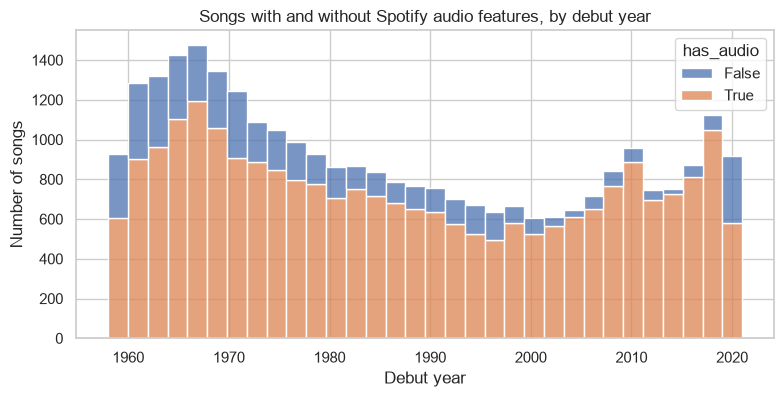

In [41]:
print(songs.groupby("has_audio")[["debut_year", "weeks_on_chart"]].agg(["count", "mean", "median"]).round(2))

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=songs, x="debut_year", hue="has_audio", multiple="stack", bins=32, ax=ax)
ax.set_xlabel("Debut year")
ax.set_ylabel("Number of songs")
ax.set_title("Songs with and without Spotify audio features, by debut year")
plt.show()

Songs used for modelling: 24,218 of 29,389


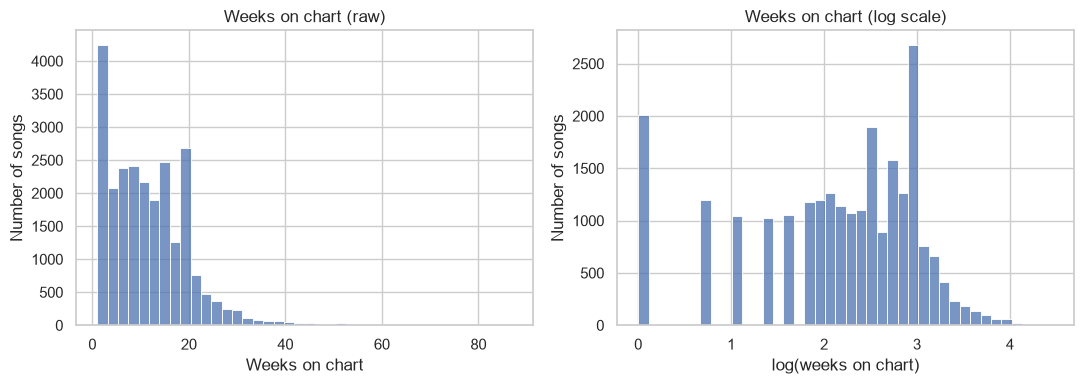

Skewness raw: 1.26 | log: -0.85


In [42]:
model_df = songs[songs["has_audio"]].copy()
numeric_features = ["debut_position", "debut_year", "debut_month", "duration_min", "danceability",
                    "energy", "loudness", "speechiness", "acousticness", "instrumentalness",
                    "liveness", "valence", "tempo", "mode", "key", "n_genres"]
model_df = model_df.dropna(subset=numeric_features + ["explicit", "log_weeks"]).copy()
model_df["debut_decade"] = model_df["debut_decade"].astype(int)
print(f"Songs used for modelling: {len(model_df):,} of {len(songs):,}")

# Target distribution: raw vs log.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(model_df["weeks_on_chart"], bins=40, ax=axes[0])
axes[0].set(title="Weeks on chart (raw)", xlabel="Weeks on chart", ylabel="Number of songs")
sns.histplot(model_df["log_weeks"], bins=40, ax=axes[1])
axes[1].set(title="Weeks on chart (log scale)", xlabel="log(weeks on chart)", ylabel="Number of songs")
plt.tight_layout()
plt.show()
print("Skewness raw:", round(stats.skew(model_df["weeks_on_chart"]), 2),
      "| log:", round(stats.skew(model_df["log_weeks"]), 2))

### **Correlation Between Features**

Before testing features one at a time, a heatmap shows which features move together. Strongly related features (for example `energy` and `loudness`) carry overlapping information and can make regression coefficients unstable.

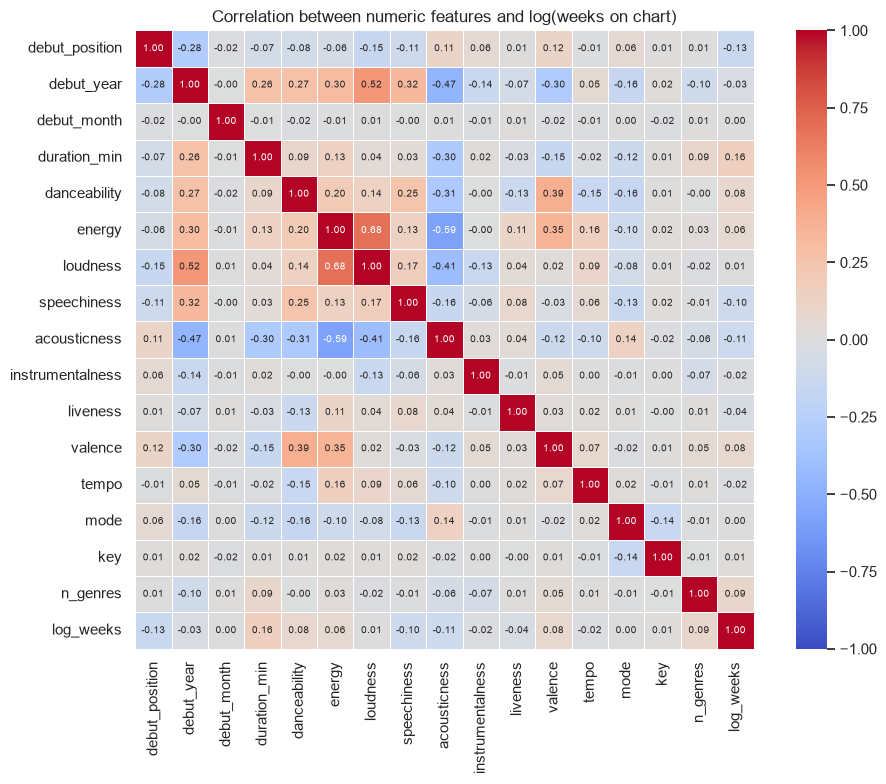

In [43]:
corr = model_df[numeric_features + ["log_weeks"]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            linewidths=0.5, annot_kws={"size": 7}, ax=ax)
ax.set(title="Correlation between numeric features and log(weeks on chart)")
plt.tight_layout()
plt.show()

**Reading the heatmap.** Most features are only weakly related to each other. The notable pairs are `energy` and `loudness` (r ≈ +0.68) and `energy` and `acousticness` (r ≈ −0.59): loud songs are energetic and acoustic songs are quiet. This overlap is the reason a VIF check is run before the regression. None of the audio features has a strong relationship with `log_weeks` (|r| < 0.17), which already suggests that the final model cannot be very accurate.

### **Outlier Detection**

An outlier is a value far from the rest. Outliers can distort means, correlations and regression coefficients, but detecting one does **not** mean it must be removed. Three views are compared on the main numeric variables:

| Rule | Flags a value when | Based on |
|---|---|---|
| Box plot | it is drawn beyond the whiskers (1.5 × IQR from the box) | quartiles (visual) |
| IQR rule | it is below Q1 − 1.5·IQR or above Q3 + 1.5·IQR | quartiles (robust) |
| Z-score | the absolute z is above 3, with z = (x − mean) / standard deviation | mean and SD (pulled by outliers) |

In [44]:
outlier_features = ["weeks_on_chart", "log_weeks", "duration_min", "tempo", "loudness", "speechiness", "debut_position"]
data = model_df[outlier_features]

z_mask = ((data - data.mean()) / data.std(ddof=0)).abs() > 3
q1, q3 = data.quantile(0.25), data.quantile(0.75)
iqr = q3 - q1
iqr_mask = (data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)
box_counts = pd.Series({f: len(cbook.boxplot_stats(data[f], whis=1.5)[0]["fliers"]) for f in outlier_features})

outlier_summary = pd.DataFrame({
    "box_plot": box_counts, "z_score": z_mask.sum(), "iqr_rule": iqr_mask.sum(),
    "flagged_by_both": (z_mask & iqr_mask).sum(), "skewness": data.skew().round(2),
})
outlier_summary["iqr_%"] = (outlier_summary["iqr_rule"] / len(model_df) * 100).round(2)
outlier_summary

,box_plot,z_score,iqr_rule,flagged_by_both,skewness,iqr_%
weeks_on_chart,375,306,375,306,1.26,1.55
log_weeks,0,0,0,0,-0.85,0.00
duration_min,561,280,561,280,2.13,2.32
tempo,277,69,277,69,0.52,1.14
loudness,180,129,180,129,-0.65,0.74
speechiness,3344,717,3344,717,3.17,13.81
debut_position,1441,641,1441,641,-1.74,5.95


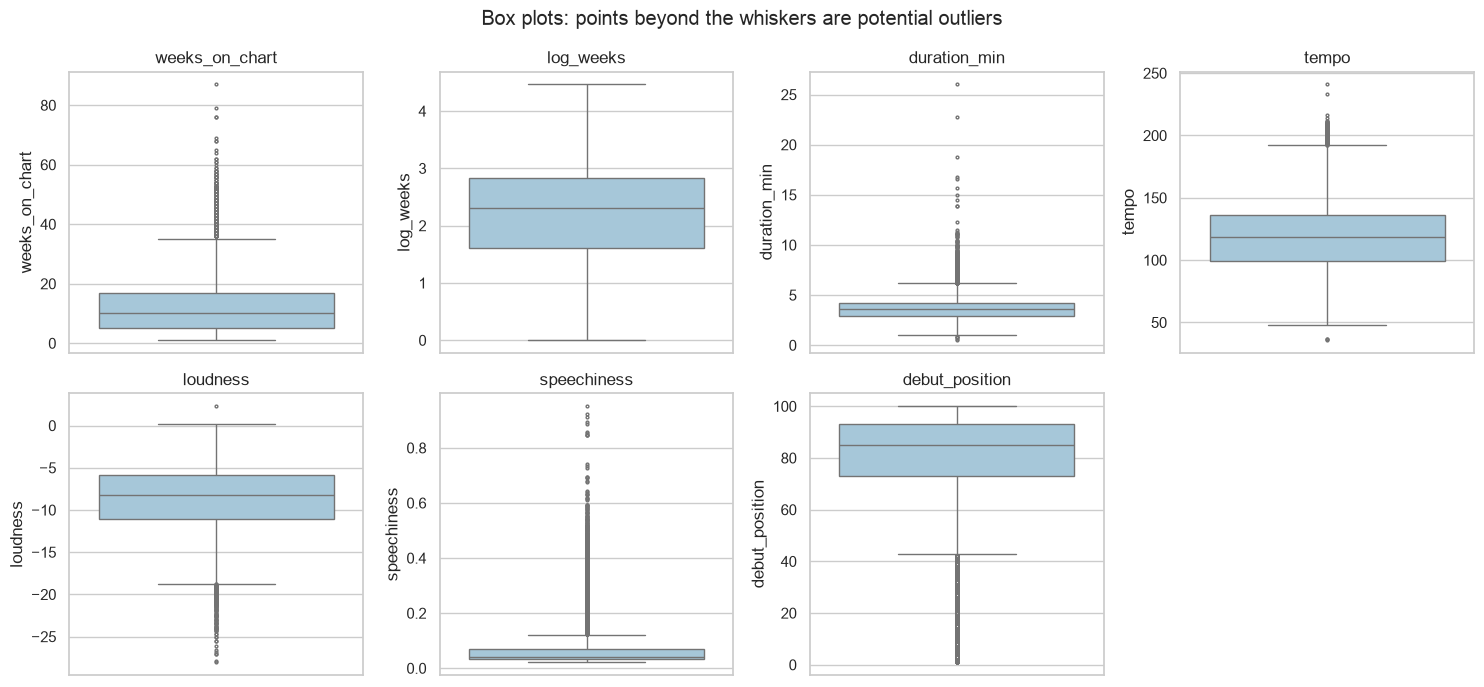

In [45]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, outlier_features):
    sns.boxplot(y=model_df[col], ax=ax, color="#9ecae1", fliersize=2)
    ax.set(title=col, ylabel=col)
axes.flat[-1].set_visible(False)
fig.suptitle("Box plots: points beyond the whiskers are potential outliers")
plt.tight_layout()
plt.show()

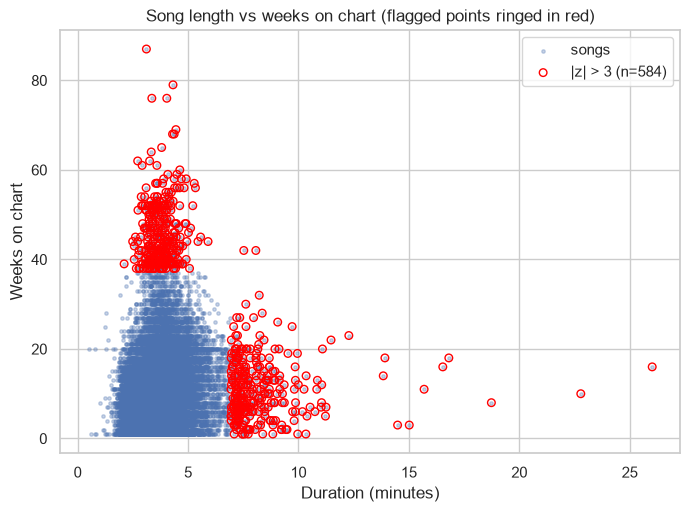

In [46]:
fig, ax = plt.subplots(figsize=(8, 5.5))
flag = z_mask["duration_min"] | z_mask["weeks_on_chart"]
ax.scatter(model_df["duration_min"], model_df["weeks_on_chart"], s=6, alpha=0.3, label="songs")
ax.scatter(model_df.loc[flag, "duration_min"], model_df.loc[flag, "weeks_on_chart"], s=30,
           facecolor="none", edgecolor="red", label=f"|z| > 3 (n={int(flag.sum())})")
ax.set(title="Song length vs weeks on chart (flagged points ringed in red)",
       xlabel="Duration (minutes)", ylabel="Weeks on chart")
ax.legend()
plt.show()

**Who are the outliers?** Before removing anything, look at which songs the rules flag.

In [47]:
long_runs = model_df[iqr_mask["weeks_on_chart"]]
print(f"Songs flagged on weeks_on_chart by the IQR rule: {len(long_runs):,} "
      f"(upper bound = {q3['weeks_on_chart'] + 1.5 * iqr['weeks_on_chart']:.1f} weeks)")
print("\nShare of flagged songs by decade (%):")
print((long_runs["debut_decade"].value_counts(normalize=True).sort_index() * 100).round(1).to_string())
long_runs.nlargest(5, "weeks_on_chart")[["song", "performer", "weeks_on_chart", "peak_position", "debut_year"]]

Songs flagged on weeks_on_chart by the IQR rule: 375 (upper bound = 35.0 weeks)

Share of flagged songs by decade (%):
debut_decade
1950     0.3
1960     0.8
1970     0.8
1980     1.6
1990    15.7
2000    28.8
2010    50.7
2020     1.3


,song,performer,weeks_on_chart,peak_position,debut_year
19483,Radioactive,Imagine Dragons,87,3,2012
20477,Sail,AWOLNATION,79,17,2011
2874,Blinding Lights,The Weeknd,76,1,2019
12105,I'm Yours,Jason Mraz,76,6,2008
10190,How Do I Live,LeAnn Rimes,69,2,1997


In [48]:
mid = model_df["duration_min"].median()
short_songs = model_df[iqr_mask["duration_min"] & (model_df["duration_min"] < mid)]
long_songs = model_df[iqr_mask["duration_min"] & (model_df["duration_min"] > mid)]
print(f"Unusually short songs: {len(short_songs)} | unusually long songs: {len(long_songs)}")
long_songs.nlargest(3, "duration_min")[["song", "performer", "duration_min", "weeks_on_chart"]]

Unusually short songs: 5 | unusually long songs: 556


,song,performer,duration_min,weeks_on_chart
26131,Tubular Bells,Mike Oldfield,26.018883,16
1815,Autobahn,Kraftwerk,22.784883,10
3487,By The Time I Get To Phoenix,Isaac Hayes,18.735883,8


**Reading the outlier results**

- **`log_weeks` has no outliers** on any rule, while the raw `weeks_on_chart` has 375 (IQR) / 306 (Z-score). The skew was a scale problem that the log transform removes, which is another reason for using the log target.
- **Z-score vs IQR:** the IQR rule flags more values than the Z-score for every variable (for example `speechiness`: 3,344 vs 717). The reason is that the two methods use different centres and spreads: the SD is inflated by the extreme values themselves, so |z| > 3 is a wider fence. `speechiness` is highly right-skewed (skew 3.2), so 13.8 % of songs lie beyond the IQR fence. Those are rap and spoken-word songs, which are a real group, not errors.
- **Long chart runs are legitimate hits.** The 375 songs above 35 weeks include *Radioactive* (87 weeks), *Blinding Lights* (76) and *How Do I Live* (69). About 96 % of them debuted in 1990 or later, because the chart rules changed and long runs became possible. Deleting them would remove the very songs the research question is about, so they are **kept** in the main model.
- **Duration:** 556 songs are unusually long (over about 7 minutes; the longest is *Tubular Bells* at 26 minutes) and only 5 unusually short. These are rare but real tracks, so they were kept; the only values removed as errors were the 4 impossible ones in Task 2.5.
- **Scatter plot:** the long-running songs cluster at 3–5 minutes, while songs longer than 7 minutes almost never stay on the chart for 20+ weeks.

### **Hypothesis Tests**

With more than 20,000 songs, almost any correlation is "statistically significant", so **two** criteria are used for keeping a feature:

1. **Statistical:** the p-value stays below 0.05 after a Holm correction for running many tests at once.
2. **Practical:** the effect is not tiny (|r| ≥ 0.05 for a numeric feature, η² ≥ 0.01 for a group variable).

#### Step 1 – Check assumptions

Shapiro-Wilk on log_weeks (sample of 5,000): W = 0.9153, p = 1.88e-46
Levene test (explicit vs not): statistic = 1390.78, p = 4.92e-296


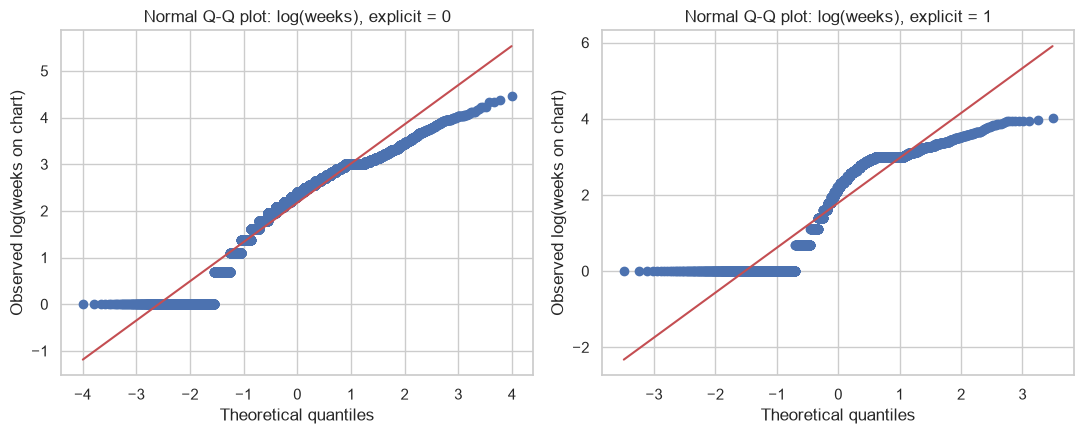

In [49]:
sample = model_df["log_weeks"].sample(5000, random_state=RANDOM_STATE)
w, p = stats.shapiro(sample)
print(f"Shapiro-Wilk on log_weeks (sample of 5,000): W = {w:.4f}, p = {p:.2e}")
lev = stats.levene(*[g["log_weeks"].values for _, g in model_df.groupby("explicit")])
print(f"Levene test (explicit vs not): statistic = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (label, grp) in zip(axes, model_df.groupby("explicit")):
    stats.probplot(grp["log_weeks"], dist="norm", plot=ax)
    ax.set(title=f"Normal Q-Q plot: log(weeks), explicit = {int(label)}",
           xlabel="Theoretical quantiles", ylabel="Observed log(weeks on chart)")
plt.tight_layout()
plt.show()

**Reading the Q-Q plots.** Neither group follows the straight line. `log_weeks` has a **floor at 0**, because every song that charted for only one week has log(1) = 0, which creates the flat stretch on the left; the right end is cut off because there is a limit to how long songs stay. That agrees with the Shapiro–Wilk result (p < 0.001). With more than 24,000 songs the t-test and ANOVA are still reasonably robust, and the rank-based tests below are used as a cross-check.

Normality is only approximate, but with thousands of observations the t-test, ANOVA and correlation are robust to mild departures. Spearman correlation and Kruskal–Wallis are added as checks that do not assume normality. Welch's t-test is used because it does not assume equal variances.

#### Step 2 – Numeric features: correlation with `log_weeks`

- **H₀:** the feature has no linear relationship with `log_weeks` (ρ = 0).
- **H₁:** ρ ≠ 0.

In [50]:
rows = []
for col in numeric_features:
    r, p_r = stats.pearsonr(model_df[col], model_df["log_weeks"])
    rho, p_s = stats.spearmanr(model_df[col], model_df["log_weeks"])
    rows.append({"feature": col, "pearson_r": r, "p_pearson": p_r, "spearman_rho": rho, "p_spearman": p_s})
corr_tbl = pd.DataFrame(rows)
corr_tbl["p_holm"] = multipletests(corr_tbl["p_pearson"], method="holm")[1]
corr_tbl["keep"] = (corr_tbl["p_holm"] < 0.05) & (corr_tbl["pearson_r"].abs() >= 0.05)
corr_tbl = corr_tbl.reindex(corr_tbl["pearson_r"].abs().sort_values(ascending=False).index).reset_index(drop=True)
corr_tbl.round(4)

,feature,pearson_r,p_pearson,spearman_rho,p_spearman,p_holm,keep
0,duration_min,0.1608,0.0000,0.2394,0.0000,0.0000,True
1,debut_position,-0.1345,0.0000,-0.2019,0.0000,0.0000,True
2,acousticness,-0.1150,0.0000,-0.1471,0.0000,0.0000,True
3,speechiness,-0.1039,0.0000,-0.0380,0.0000,0.0000,True
4,n_genres,0.0884,0.0000,0.0759,0.0000,0.0000,True
5,danceability,0.0806,0.0000,0.1142,0.0000,0.0000,True
6,valence,0.0759,0.0000,0.0167,0.0094,0.0000,True
7,energy,0.0632,0.0000,0.0852,0.0000,0.0000,True
8,liveness,-0.0419,0.0000,-0.0686,0.0000,0.0000,False
9,debut_year,-0.0316,0.0000,0.1257,0.0000,0.0000,False


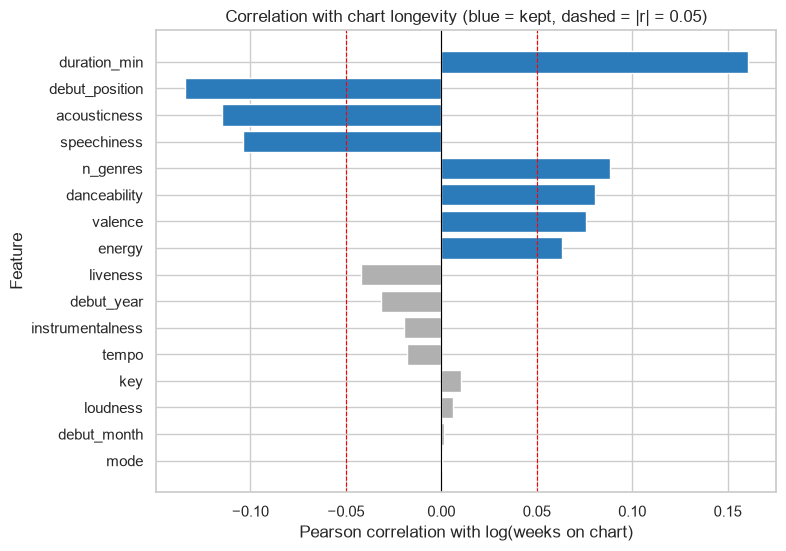

In [51]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = corr_tbl["keep"].map({True: "#2b7bba", False: "#b0b0b0"})
ax.barh(corr_tbl["feature"], corr_tbl["pearson_r"], color=colors)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.axvline(0.05, color="red", ls="--", lw=0.8)
ax.axvline(-0.05, color="red", ls="--", lw=0.8)
ax.set_xlabel("Pearson correlation with log(weeks on chart)")
ax.set_ylabel("Feature")
ax.set_title("Correlation with chart longevity (blue = kept, dashed = |r| = 0.05)")
plt.show()

#### Step 3 – Two-group comparisons (Welch's t-test)

- **H₀:** mean `log_weeks` is the same in both groups.
- **H₁:** the means differ.

**Mann–Whitney U** is added as a rank-based back-up that does not assume normality; the two tests should agree.

In [52]:
def welch(df, flag):
    g1 = df.loc[df[flag] == 1, "log_weeks"]
    g0 = df.loc[df[flag] == 0, "log_weeks"]
    t, p = stats.ttest_ind(g1, g0, equal_var=False)
    p_mw = stats.mannwhitneyu(g1, g0, alternative="two-sided").pvalue   # rank-based back-up, no normality needed
    pooled = np.sqrt((g1.var() + g0.var()) / 2)
    return {"feature": flag, "n_yes": len(g1), "n_no": len(g0), "mean_yes": g1.mean(),
            "mean_no": g0.mean(), "t": t, "p_value": p, "p_mannwhitney": p_mw,
            "cohens_d": (g1.mean() - g0.mean()) / pooled}

model_df["is_collab_int"] = model_df["is_collab"].astype(int)
two_group = pd.DataFrame([welch(model_df, "explicit"), welch(model_df, "is_collab_int")])
two_group["p_holm"] = multipletests(two_group["p_value"], method="holm")[1]
two_group.round(4)

,feature,n_yes,n_no,mean_yes,mean_no,t,p_value,p_mannwhitney,cohens_d,p_holm
0,explicit,2872,21346,1.7909,2.1714,-15.5989,0.0000,0.0,-0.3495,0.0000
1,is_collab_int,2144,22074,2.1015,2.1287,-1.0487,0.2944,0.0,-0.0260,0.2944


#### Step 4 – Several groups (one-way ANOVA and Kruskal–Wallis)

- **H₀:** mean `log_weeks` is equal in every genre family (or decade).
- **H₁:** at least one group mean differs.

Effect size: η² (eta squared) = share of the variance explained by the grouping.

In [53]:
def anova_row(df, group):
    groups = [g["log_weeks"].values for _, g in df.groupby(group) if len(g) >= 20]
    f, p = stats.f_oneway(*groups)
    h, p_kw = stats.kruskal(*groups)
    grand = df["log_weeks"].mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = ((df["log_weeks"] - grand) ** 2).sum()
    return {"feature": group, "groups": len(groups), "F": f, "p_anova": p, "H": h,
            "p_kruskal": p_kw, "eta_squared": ss_between / ss_total}

multi = pd.DataFrame([anova_row(model_df, "genre_main"), anova_row(model_df, "debut_decade")])
multi["p_holm"] = multipletests(multi["p_anova"], method="holm")[1]
multi["keep"] = (multi["p_holm"] < 0.05) & (multi["eta_squared"] >= 0.01)
multi.round(4)

,feature,groups,F,p_anova,H,p_kruskal,eta_squared,p_holm,keep
0,genre_main,8,116.2387,0.0,627.8643,0.0,0.0325,0.0,True
1,debut_decade,8,507.7398,0.0,3066.1332,0.0,0.1280,0.0,True


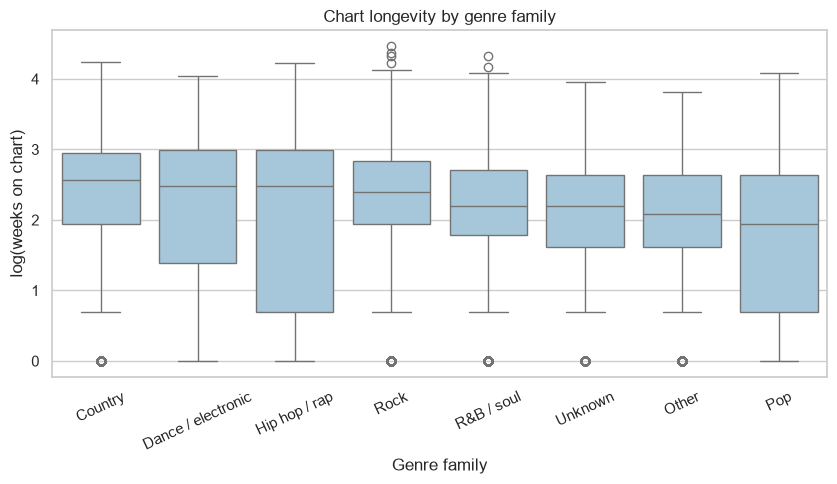

In [54]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = model_df.groupby("genre_main")["log_weeks"].median().sort_values(ascending=False).index
sns.boxplot(data=model_df, x="genre_main", y="log_weeks", order=order, ax=ax, color="#9ecae1")
ax.set_xlabel("Genre family")
ax.set_ylabel("log(weeks on chart)")
ax.set_title("Chart longevity by genre family")
plt.xticks(rotation=25)
plt.show()

#### Step 5 – Decision: which features go into the regression?

In [55]:
selected_numeric = corr_tbl.loc[corr_tbl["keep"], "feature"].tolist()
selected_flags = two_group.loc[(two_group["p_holm"] < 0.05) & (two_group["cohens_d"].abs() >= 0.1), "feature"].tolist()
selected_groups = multi.loc[multi["keep"], "feature"].tolist()

print("Numeric features kept:", selected_numeric)
print("Flags kept:           ", selected_flags)
print("Group variables kept: ", selected_groups)

Numeric features kept: ['duration_min', 'debut_position', 'acousticness', 'speechiness', 'n_genres', 'danceability', 'valence', 'energy']
Flags kept:            ['explicit']
Group variables kept:  ['genre_main', 'debut_decade']


**Reading the tests**

- **Numeric features:** the strongest relationships with chart longevity are `duration_min` (r = +0.16, longer songs stay longer), `debut_position` (r = −0.13, songs that enter higher stay longer), `acousticness` (−0.12), `speechiness` (−0.10), `danceability` (+0.08), `valence` (+0.08) and `energy` (+0.06). `loudness`, `key`, `mode` and `debut_month` have no detectable relationship, and `liveness`, `tempo`, `instrumentalness` and `debut_year` were dropped because their linear effect is below |r| = 0.05.
- **Explicit songs** have a clearly lower mean `log_weeks` (1.79 vs 2.17, Cohen's d = −0.35), and Mann–Whitney U agrees, so `explicit` is kept.
- **Guest-artist songs** (`is_collab`): Welch's test finds no difference in means (p = 0.29) and the effect size is negligible (d = −0.03), so the flag is dropped. Mann–Whitney U does report a difference (p < 0.001), because the *medians* are slightly higher for guest-artist songs while the *means* are slightly lower. With such a small effect the flag adds nothing practical to the model.
- **Genre family** (η² = 0.03) and **debut decade** (η² = 0.13) both differ significantly. The decade effect is not linear in the year (r = −0.03 for the numeric year, but Spearman ρ = +0.13 and η² = 0.13), which is why the decade enters the regression as dummy variables rather than as a number.
- The Kruskal–Wallis tests agree with the ANOVA results.

**Caution:** the p-values are tiny because there are more than 24,000 songs. They show that effects are *real*, not that they are *large*. This is why the effect-size rule is used as well.

### **Linear Regression**

Two models predict `log_weeks`:

- **Model A – all candidate features** (every numeric feature, the two flags and genre family).
- **Model B – tested features only** (the features kept in Step 5).

Both use the same 80/20 train/test split. A collinearity check (VIF) comes first, because audio features such as `energy`, `loudness` and `acousticness` move together.

In [56]:
def design(df, numeric, flags, groups):
    X = df[numeric].copy()
    for f in flags:
        X[f] = df[f]
    for g in groups:
        X = X.join(pd.get_dummies(df[g], prefix=g, drop_first=True, dtype=float))
    return X.astype(float)

all_numeric = numeric_features
X_all = design(model_df, all_numeric, ["explicit", "is_collab_int"], ["genre_main"])
y = model_df["log_weeks"]

vif = pd.DataFrame({"feature": X_all.columns,
                    "VIF": [variance_inflation_factor(sm.add_constant(X_all).values, i + 1)
                            for i in range(X_all.shape[1])]}).sort_values("VIF", ascending=False)
vif.head(8).round(2)

,feature,VIF
5,energy,3.47
19,genre_main_Hip hop / rap,3.41
1,debut_year,2.98
6,loudness,2.70
23,genre_main_Rock,2.50
22,genre_main_R&B / soul,2.30
16,explicit,2.25
11,valence,2.12


In [57]:
sel_numeric = selected_numeric
sel_flags = selected_flags
sel_groups = selected_groups   # genre_main and debut_decade enter as dummy variables
X_sel = design(model_df, sel_numeric, sel_flags, sel_groups)

train_idx, test_idx = train_test_split(model_df.index, test_size=0.2, random_state=RANDOM_STATE)

def fit_eval(X, name):
    ols = sm.OLS(y.loc[train_idx], sm.add_constant(X.loc[train_idx])).fit()
    pred = ols.predict(sm.add_constant(X.loc[test_idx]))
    lr = LinearRegression().fit(X.loc[train_idx], y.loc[train_idx])   # same model in scikit-learn, as a cross-check
    return ols, {"model": name, "n_features": X.shape[1],
                 "R2_train": ols.rsquared, "adj_R2_train": ols.rsquared_adj,
                 "R2_test": r2_score(y.loc[test_idx], pred),
                 "RMSE_test (log weeks)": np.sqrt(mean_squared_error(y.loc[test_idx], pred)),
                 "sklearn_R2_test": lr.score(X.loc[test_idx], y.loc[test_idx])}

ols_all, res_all = fit_eval(X_all, "A: all candidates")
ols_sel, res_sel = fit_eval(X_sel, "B: tested features")
pd.DataFrame([res_all, res_sel]).round(4)

,model,n_features,R2_train,adj_R2_train,R2_test,RMSE_test (log weeks),sklearn_R2_test
0,A: all candidates,25,0.1222,0.1211,0.1242,0.8727,0.1242
1,B: tested features,23,0.1877,0.1867,0.1856,0.8416,0.1856


In [58]:
coef = pd.DataFrame({"coef": ols_sel.params, "p_value": ols_sel.pvalues,
                     "ci_low": ols_sel.conf_int()[0], "ci_high": ols_sel.conf_int()[1]})
coef.round(4)

,coef,p_value,ci_low,ci_high
const,2.8202,0.0000,2.6806,2.9597
duration_min,0.0369,0.0000,0.0235,0.0503
debut_position,-0.0093,0.0000,-0.0099,-0.0086
acousticness,-0.1373,0.0000,-0.1972,-0.0773
speechiness,-0.6827,0.0000,-0.8651,-0.5003
n_genres,0.0039,0.1104,-0.0009,0.0087
danceability,0.4025,0.0000,0.2992,0.5059
valence,0.0985,0.0067,0.0273,0.1697
energy,-0.1096,0.0104,-0.1934,-0.0258
explicit,-0.1836,0.0000,-0.2392,-0.1280


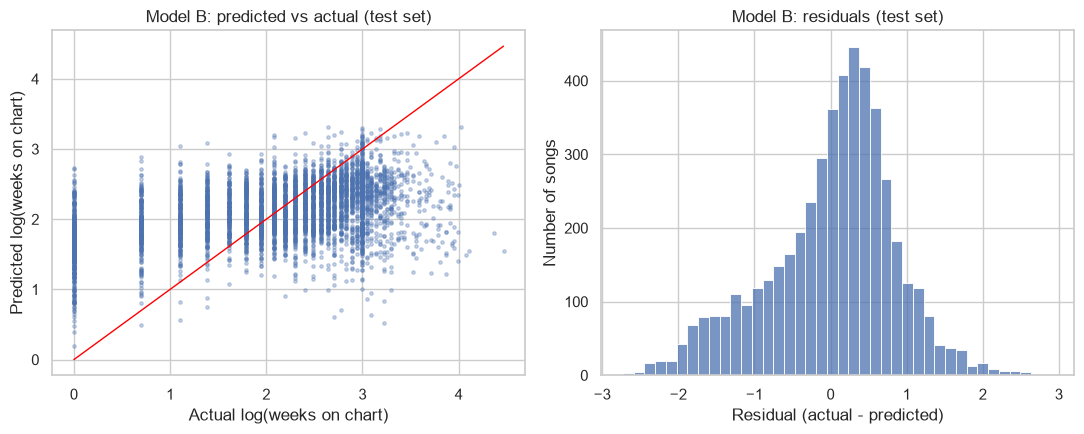

In [59]:
pred_test = ols_sel.predict(sm.add_constant(X_sel.loc[test_idx]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(y.loc[test_idx], pred_test, s=6, alpha=0.3)
lims = [y.min(), y.max()]
axes[0].plot(lims, lims, color="red", lw=1)
axes[0].set(xlabel="Actual log(weeks on chart)", ylabel="Predicted log(weeks on chart)",
            title="Model B: predicted vs actual (test set)")
resid = y.loc[test_idx] - pred_test
sns.histplot(resid, bins=40, ax=axes[1])
axes[1].set(xlabel="Residual (actual - predicted)", ylabel="Number of songs",
            title="Model B: residuals (test set)")
plt.tight_layout()
plt.show()

#### Sensitivity check – do the outliers drive the result?

The chart outliers (very long runs) are real hits, so they stay in the main model. As a check, Model B is refitted **without** the songs flagged by the IQR rule on `weeks_on_chart` or `duration_min`, and the results are compared.

In [60]:
trim_mask = iqr_mask["weeks_on_chart"] | iqr_mask["duration_min"]      # indexed like model_df
keep = ~trim_mask
tr = [i for i in train_idx if keep.loc[i]]
te = [i for i in test_idx if keep.loc[i]]

ols_trim = sm.OLS(y.loc[tr], sm.add_constant(X_sel.loc[tr])).fit()
pred_trim = ols_trim.predict(sm.add_constant(X_sel.loc[te]))

sens = pd.DataFrame({
    "coef (all songs)": ols_sel.params,
    "coef (outliers removed)": ols_trim.params,
    "p (all songs)": ols_sel.pvalues,
    "p (outliers removed)": ols_trim.pvalues,
})
sens["same sign"] = np.sign(sens["coef (all songs)"]) == np.sign(sens["coef (outliers removed)"])
print(f"Songs removed: {int(trim_mask.sum()):,} of {len(model_df):,} ({trim_mask.mean():.1%})")
print(f"R2 test  - all songs: {res_sel['R2_test']:.3f} | outliers removed: {r2_score(y.loc[te], pred_trim):.3f}")
print(f"RMSE test - all songs: {res_sel['RMSE_test (log weeks)']:.3f} | outliers removed: "
      f"{np.sqrt(mean_squared_error(y.loc[te], pred_trim)):.3f}")
print("Coefficients with the same sign in both fits:", int(sens.drop(index="const")["same sign"].sum()), "of", len(sens) - 1, "(excluding the constant)")
sens.drop(index="const").round(4)

Songs removed: 934 of 24,218 (3.9%)
R2 test  - all songs: 0.186 | outliers removed: 0.201
RMSE test - all songs: 0.842 | outliers removed: 0.818
Coefficients with the same sign in both fits: 23 of 23 (excluding the constant)


,coef (all songs),coef (outliers removed),p (all songs),p (outliers removed),same sign
duration_min,0.0369,0.0698,0.0000,0.0000,True
debut_position,-0.0093,-0.0091,0.0000,0.0000,True
acousticness,-0.1373,-0.1409,0.0000,0.0000,True
speechiness,-0.6827,-0.6673,0.0000,0.0000,True
n_genres,0.0039,0.0047,0.1104,0.0549,True
danceability,0.4025,0.3490,0.0000,0.0000,True
valence,0.0985,0.1078,0.0067,0.0031,True
energy,-0.1096,-0.0835,0.0104,0.0510,True
explicit,-0.1836,-0.1596,0.0000,0.0000,True
genre_main_Dance / electronic,-0.3136,-0.3292,0.0000,0.0000,True


**Result.** Removing the 934 songs (3.9 %) flagged on `weeks_on_chart` or `duration_min` leaves the conclusions the same. All coefficients keep their sign, the test R² rises a little (0.186 → 0.201) and the error falls (RMSE 0.842 → 0.818), which is expected because the hardest-to-predict songs were removed. The main effects (speechiness, danceability, explicit, genre family, decade) change by only a few hundredths. The conclusion does not depend on the outliers, so the outliers stay in the final model.

#### Leak-safe modelling with a scikit-learn `Pipeline`

The statsmodels fit above is useful for coefficients and p-values. For judging **prediction quality** the preprocessing is packaged with the model in a `Pipeline`, so that scaling and encoding are learned from the training rows only and then applied unchanged to the test rows. Three models are compared on the same split:

- a **baseline** that always predicts the training mean (R² ≈ 0 by construction);
- **Model A** with all candidate features;
- **Model B** with the tested features.

A 5-fold cross-validation then checks that the result does not depend on one lucky split.

In [61]:
def build_pipeline(numeric, flags, categories, regressor):
    """Scale numeric columns, one-hot encode categories, then fit the regressor."""
    prep = ColumnTransformer([
        ("num", StandardScaler(), numeric + flags),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categories),
    ])
    return Pipeline([("prep", prep), ("model", regressor)])

def raw_frame(numeric, flags, categories):
    frame = model_df[numeric + flags + categories].copy()
    for col in categories:
        frame[col] = frame[col].astype(str)          # decade becomes a category, not a number
    return frame

features_A = (all_numeric, ["explicit", "is_collab_int"], ["genre_main"])
features_B = (sel_numeric, sel_flags, sel_groups)
X_A, X_B = raw_frame(*features_A), raw_frame(*features_B)

models = {
    "Baseline (training mean)": (X_B, DummyRegressor(strategy="mean"), features_B),
    "A: all candidates":        (X_A, LinearRegression(), features_A),
    "B: tested features":       (X_B, LinearRegression(), features_B),
}
rows, fitted = [], {}
for name, (X_raw, reg, feats) in models.items():
    pipe = build_pipeline(*feats, reg).fit(X_raw.loc[train_idx], y.loc[train_idx])
    pred = pipe.predict(X_raw.loc[test_idx])
    fitted[name] = pipe
    rows.append({"model": name, "MAE": mean_absolute_error(y.loc[test_idx], pred),
                 "RMSE": np.sqrt(mean_squared_error(y.loc[test_idx], pred)),
                 "R2": r2_score(y.loc[test_idx], pred)})
pipe_results = pd.DataFrame(rows).set_index("model")
pipe_results.round(3)

,MAE,RMSE,R2
model,,,
Baseline (training mean),0.742,0.933,-0.000
A: all candidates,0.689,0.873,0.124
B: tested features,0.655,0.842,0.186


In [62]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, (X_raw, reg, feats) in models.items():
    out = cross_validate(build_pipeline(*feats, reg), X_raw, y, cv=cv,
                         scoring=("r2", "neg_mean_absolute_error"))
    cv_rows.append({"model": name, "R2 mean": out["test_r2"].mean(), "R2 std": out["test_r2"].std(),
                    "MAE mean": -out["test_neg_mean_absolute_error"].mean()})
pd.DataFrame(cv_rows).set_index("model").round(3)

,R2 mean,R2 std,MAE mean
model,,,
Baseline (training mean),-0.000,0.000,0.746
A: all candidates,0.120,0.006,0.696
B: tested features,0.185,0.004,0.661


**Reading the pipeline results**

| Model | Test MAE | Test RMSE | Test R² | 5-fold CV R² (mean ± SD) |
|---|---|---|---|---|
| Baseline (training mean) | 0.742 | 0.933 | 0.000 | 0.000 ± 0.000 |
| A: all candidates | 0.689 | 0.873 | 0.124 | 0.120 ± 0.006 |
| B: tested features | 0.655 | 0.842 | 0.186 | 0.185 ± 0.004 |

- Both regression models beat the baseline, and Model B beats Model A on the test set and in all five folds (the standard deviation is small), so the advantage is not a lucky split.
- The pipeline reproduces the statsmodels result (test R² 0.186), which confirms that both implementations agree.
- A typical prediction is off by about 0.66 in log-weeks (roughly a factor of 1.9 in weeks). That is a meaningful improvement over the baseline, but still large.

**Reading the regression**

| | Model A (all candidates) | Model B (tested features) |
|---|---|---|
| Features | 25 | 23 |
| R² on the test set | 0.124 | 0.186 |
| RMSE on the test set (log weeks) | 0.873 | 0.842 |

- Model B has fewer numeric features but **performs better on unseen songs**: the decade dummies capture the non-linear time effect that the single year column in Model A misses. Dropping features that fail the tests did not hurt.
- **Even the better model explains only about 19 % of the variation.** Characteristics known at debut (sound, length, genre, era, starting rank) are weak predictors of how long a song lasts; popularity, promotion and listener behaviour are not in the data.
- With the log target, a coefficient of 0.1 means about 10 % more weeks. Examples (baseline: Country songs, 1950s): `explicit` ≈ −0.18 (about 17 % fewer weeks), `speechiness` ≈ −0.68, `danceability` ≈ +0.40. Pop is the genre family with the shortest stay (−0.55) and the 1990s have the longest (+0.37).
- `n_genres` is not significant inside the model (p = 0.11) even though it passed the correlation test, because it overlaps with the genre family. It could be dropped in a further iteration.
- The residuals are roughly bell-shaped but the predicted values are squeezed into a narrow band (the model cannot predict very short or very long chart runs well).
- VIF values stay below 3.5, so collinearity among the audio features is not a problem.
- Limitation: only songs with Spotify data (24,218 of 29,389) are used, and the songs without data are older (median debut 1975 vs 1985), so the result mostly describes the more recent chart.

---
## **Answer to the Research Question**

**Short answer:** a little. Characteristics known at debut explain only about **19 % of the variation** in chart longevity on unseen songs (test R² = 0.186, cross-validated R² = 0.185 ± 0.004, against 0 for the baseline). They are statistically real but practically modest.

| Factor | Direction (effect on weeks on chart) |
|---|---|
| Longer song duration | more weeks |
| Higher debut rank (smaller number) | more weeks |
| Danceability and valence | more weeks |
| Speechiness, acousticness and energy | fewer weeks |
| Explicit lyrics | fewer weeks (about 17 % fewer, other factors equal) |
| Genre family | Country stays longest, Pop shortest |
| Debut decade | 1980s–2000s stay longer than the 1950s–1970s |
| Guest artist, key, mode, tempo, release month | no useful effect |

**How we got here**

1. Loaded and inspected the chart and audio files, and checked duplicates (Tasks 2.1 and 2.5).
2. Built a wide table, reshaped it with `melt()`, cleaned the week labels with string methods, and handled missing ranks, impossible values and missing audio features (Tasks 2.2–2.5).
3. Rebuilt the chart dates and checked them against the real ones (Task 2.6).
4. Created one row per song with features known at debut and kept leaking variables (`peak_position`, `n_instances`, Spotify popularity) out of the model.
5. Compared outlier rules (box plot, IQR, Z-score); kept the long-running hits because they are real, and showed the model does not depend on them.
6. Used correlation tests, Welch t-tests with Mann–Whitney back-ups, and ANOVA (with a Holm correction and effect-size rules) to choose the features.
7. Compared a model with all features against one with the tested features in a leak-safe pipeline with cross-validation: the tested model generalised better.


# **Section 3 – Data Cleaning (Car Details Dataset)**

This section uses the CarDekho *Car details v3* dataset: 8,128 used-car listings from India, with price, kilometres driven, fuel type, transmission, ownership history, fuel efficiency (`mileage`), engine size, power, torque and seat count.

**Why not Auto MPG?** The handout suggests the UCI Auto MPG data. As a team we each chose our own comparable dataset, so this section uses CarDekho, which raises the same cleaning problems on a larger scale: numbers stored as text with units, hidden placeholders, impossible values, missing values and duplicate rows.

The raw data is stored in a **Neon** (cloud PostgreSQL) database and loaded from there. Reusable helpers (loading, unit stripping, the missing-value report, feature engineering, and Neon upload/read) live in [`src/car_dataset/`](src/car_dataset/). The Neon connection class `NeonDatabase` lives in [`src/common/database.py`](src/common/database.py) and is shared with Section 4, so both sections connect the same way. Each section uses its own table in the same database.

### **The Research Question**

> **Do diesel cars achieve significantly better fuel efficiency (mileage) than petrol cars, and how well can a car's listed characteristics (engine size, power, age, fuel type, transmission) predict its mileage?**

Why fuel efficiency?

- **Mileage** (km per litre) is one of the biggest running costs for a used-car buyer, and it is listed for almost every car in the dataset.
- **Fuel type** is the first choice most buyers make. Diesel is commonly assumed to be more economical, so it is worth testing whether that belief shows up in the data and how big the difference really is.
- **Engine size, power and age** are the physical characteristics most expected to drive fuel consumption. If they explain mileage well, a buyer could estimate it for a car whose listing leaves it out.

Every part of the notebook feeds this question: **cleaning** makes mileage trustworthy (units stripped, km/kg cars separated, impossible zeros and duplicate listings removed), **feature engineering** adds power per litre, **EDA** gives a first look at mileage by fuel, transmission and engine size, **inferential statistics** tests the diesel-vs-petrol difference formally, and the **regression model** measures how predictable mileage is.

In [63]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer

# Locate the project root whether Jupyter was started in the project folder or in notebooks/,
# then put src/ on Python's search path so our own packages can be imported.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from car_dataset import load_car_data, extract_number, missing_report, add_power_per_litre, read_cars
from car_dataset.config import RAW_CSV_PATH, RAW_TABLE_NAME
from common.database import NeonDatabase  # shared Neon helper (also used by Section 4)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

#### **Task 3.1 – Load and Inspect the Cars Dataset**

##### Load the data from Neon

```text
data/Car details v3.csv ──one-time upload script──▶ Neon table "car_details_raw" ──SELECT … ORDER BY row_id──▶ pandas DataFrame
```

- **The notebook only reads.** The CSV is loaded into Neon once with `PYTHONPATH=src python -m car_dataset.upload` (run from the project root), which also verifies the Neon copy matches the CSV. Because the notebook never writes, it works with a read-only database login.
- **The connection string never goes in the notebook.** It contains a username and password, so it lives in the git-ignored `.env` file as `NEON_DATABASE_URL` (see the README).
- **Row order is preserved.** SQL tables have no guaranteed row order, so a plain `SELECT *` could come back shuffled. That would change `head()`/`tail()`, which duplicate copy is kept, and the train/test split. The upload therefore stores a `row_id`, and `read_cars` sorts by it and then drops it.
- **Fallback.** If `.env` has no connection string, the cell prints a warning and reads the local CSV instead, so the notebook still runs. Both routes give identical data.

The data is loaded **raw**, without telling pandas what counts as missing. That way any hidden placeholders can be discovered from the data instead of assumed.

In [64]:
connection_string = NeonDatabase.read_connection_string()

if connection_string:
    db = NeonDatabase(connection_string)
    print("Connected to:", db.test_connection()[:60], "...")
    # Read the table in its original row order (it is uploaded once by car_dataset.upload)
    cars_raw = read_cars(db, RAW_TABLE_NAME)
    data_source = f"Neon table '{RAW_TABLE_NAME}'"
    db.close()
else:
    print("WARNING: NEON_DATABASE_URL is not set in .env - reading the local CSV instead of Neon.")
    cars_raw = load_car_data(RAW_CSV_PATH)
    data_source = "local CSV (fallback)"

print(f"Loaded {cars_raw.shape[0]:,} rows x {cars_raw.shape[1]} columns from {data_source}")
cars_raw.dtypes

Connected to: PostgreSQL 18.6 (653b019) on aarch64-unknown-linux-gnu, comp ...


Loaded 8,128 rows x 13 columns from Neon table 'car_details_raw'


name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
mileage              str
engine               str
max_power            str
torque               str
seats            float64
dtype: object

The dataset has **8,128 rows and 13 columns**. Three columns that should be numeric (`mileage`, `engine` and `max_power`) are stored as **text** (`str`), because their units are glued onto the numbers (`"23.4 kmpl"`, `"1248 CC"`, `"74 bhp"`). `torque` is also text and mixes units (`Nm` and `kgm`) with rpm ranges. `seats` is `float64` rather than an integer type, which is a sign that it contains missing values.

In [65]:
cars_raw.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [66]:
cars_raw.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [67]:
# Check for metadata/label rows: if a header or label row were mixed into the data,
# pandas could not have parsed `year` as integers.
print("year dtype:", cars_raw["year"].dtype)
print("Year range:", cars_raw["year"].min(), "to", cars_raw["year"].max())

year dtype: int64
Year range: 1983 to 2020


In [68]:
# Hunt for invalid placeholders: values that are present (not NaN) but contain no number at all.
for col in ["mileage", "engine", "max_power"]:
    has_value = cars_raw[col].notna()
    no_digits = has_value & ~cars_raw[col].str.contains(r"\d", na=False)
    print(f"{col}: {no_digits.sum()} value(s) with no number -> {cars_raw.loc[no_digits, col].unique().tolist()}")

mileage: 0 value(s) with no number -> []
engine: 0 value(s) with no number -> []
max_power: 1 value(s) with no number -> [' bhp']


One `max_power` value is `" bhp"`: a unit with no number. pandas treats it as a present value, but it carries no information. It is this dataset's equivalent of the `?` placeholder in Auto MPG. The cell below checks whether `mileage` is also recorded in more than one unit.

In [69]:
# Which units appear at the end of the mileage values?
cars_raw["mileage"].str.extract(r"([a-z/]+)$")[0].value_counts()

0
kmpl     7819
km/kg      88
Name: count, dtype: int64

In [70]:
# Mark the placeholder as missing (the same role na_values="?" plays for Auto MPG).
# cars_raw is kept untouched as the original reference.
cars = cars_raw.replace(" bhp", np.nan)
print("max_power missing — raw:", cars_raw["max_power"].isna().sum(), "| after marking placeholder:", cars["max_power"].isna().sum())

max_power missing — raw: 215 | after marking placeholder: 216


**Task 3.1 findings**

- **No metadata or label rows.** `year` was parsed as `int64` across all 8,128 rows (range 1983–2020). A header or label row mixed into the data would have forced the column to text. No rows are removed at this stage.
- **One hidden missing value.** A single `max_power` entry is `" bhp"` with no number. Replacing it with `NaN` raises the `max_power` missing count from 215 to 216.
- **Mixed units in `mileage`.** 7,819 values are in **kmpl** (km per litre) and 88 are in **km/kg** (CNG/LPG cars). The two units are not comparable, so they must be handled *before* the units are stripped (Task 3.2).
- **Possible duplicates.** The last two rows from `tail()` (Tata Indigo CR4, 2013) are identical in every column. Duplicates are checked properly in Task 3.3.

#### **Task 3.2 – Assess Missing and Invalid Values**

The order of operations matters here:

1. **Remove the km/kg rows first.** If the units were stripped first, `26.6 km/kg` would silently become `26.6` and be compared with km/l values. The unit information is lost the moment you convert.
2. **Convert** the unit columns to numbers.
3. **Treat physically impossible zeros as missing.** No car does 0 km/l or has 0 bhp.
4. **Only then count what's missing**, because steps 1–3 change the counts.

In [71]:
cars["fuel"].value_counts()

fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64

In [72]:
# CNG/LPG mileage is in km/kg, which is not comparable with km/l, and these cars are only about 1% of rows.
cars = cars[cars["fuel"].isin(["Diesel", "Petrol"])].copy()
cars.shape

(8033, 13)

In [73]:
# Strip the units and convert to float. The unit moves into the column name so it isn't lost.
cars["mileage_kmpl"] = extract_number(cars["mileage"])
cars["engine_cc"] = extract_number(cars["engine"])
cars["max_power_bhp"] = extract_number(cars["max_power"])

# torque mixes units (Nm vs kgm) and rpm ranges, so it is dropped. Parsing it is out of scope for this lab.
cars = cars.drop(columns=["mileage", "engine", "max_power", "torque"])
cars.dtypes

name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
seats            float64
mileage_kmpl     float64
engine_cc        float64
max_power_bhp    float64
dtype: object

In [74]:
# Physically impossible values
num_cols = ["mileage_kmpl", "engine_cc", "max_power_bhp"]
(cars[num_cols] == 0).sum()

mileage_kmpl     17
engine_cc         0
max_power_bhp     6
dtype: int64

In [75]:
cars[num_cols] = cars[num_cols].replace(0, np.nan)
missing_report(cars)

,missing,percent
mileage_kmpl,231,2.88
seats,214,2.66
engine_cc,214,2.66
max_power_bhp,214,2.66
name,0,0.00
year,0,0.00
selling_price,0,0.00
km_driven,0,0.00
fuel,0,0.00
seller_type,0,0.00


In [76]:
# notna(): confirm how many observations are valid
print("Cars with a valid max_power:", cars["max_power_bhp"].notna().sum(), "of", len(cars))
complete = cars[cars["mileage_kmpl"].notna() & cars["max_power_bhp"].notna()]
print("Rows with both mileage and power present:", complete.shape)

Cars with a valid max_power:

 7819 of 8033
Rows with both mileage and power present: (7802, 12)


In [77]:
# Snapshot for the before/after validation in Task 3.7
cars_before = cars.copy()

**Task 3.2 findings**

- **Scope.** The 95 CNG/LPG cars were removed because their mileage is measured in km/kg. That leaves **8,033 Diesel/Petrol cars**.
- **Type conversion.** `mileage`, `engine` and `max_power` were converted from text to `float64` as `mileage_kmpl`, `engine_cc` and `max_power_bhp`. `torque` was dropped (mixed units).
- **Invalid values.** 17 cars had `0 kmpl` and 6 had `0 bhp`, which are impossible values, so they were recoded as missing.
- **Missing values.** `mileage_kmpl` 231 (2.88%), and `seats`, `engine_cc` and `max_power_bhp` 214 each (2.66%). Every other column is complete. The counts are nearly identical because the same listings are missing all their technical specs at once.

#### **Task 3.3 – Check Duplicates**

An exact duplicate (every column identical, including price and kilometres driven) is almost certainly the same listing posted twice. Keeping duplicates double-counts those cars in every statistic. In a model, a duplicated car could also land in both the training and the test set, which makes the test score look better than it really is.

In [78]:
n_dups = cars.duplicated().sum()
print(f"Exact duplicate rows: {n_dups}")

# keep=False marks every copy, not just the 2nd one, so the pairs can be seen side by side
cars[cars.duplicated(keep=False)].sort_values(["name", "year", "km_driven"]).head(4)

Exact duplicate rows: 1201


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,seats,mileage_kmpl,engine_cc,max_power_bhp
1977,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,5.0,15.73,1968.0,174.33
7324,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,5.0,15.73,1968.0,174.33
2129,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,5.0,13.22,2967.0,241.40
7775,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,5.0,13.22,2967.0,241.40


In [79]:
cars = cars.drop_duplicates().reset_index(drop=True)
print(cars.shape, "| duplicates remaining:", cars.duplicated().sum())

(6832, 12) | duplicates remaining: 0


**1,201 exact duplicate rows** were found and removed. That is about 15% of the Diesel/Petrol data, a major data-quality problem. **6,832 unique cars** remain.

#### **Task 3.4 – Compare Missing-Value Strategies**

Each strategy runs on its own **copy**, so all of them start from the same data.

In [80]:
drop_rows = cars.dropna()
drop_cols = cars.dropna(axis=1)

rows_lost = len(cars) - len(drop_rows)
print(f"dropna (rows):    {cars.shape} -> {drop_rows.shape}  ({rows_lost} rows lost, {rows_lost / len(cars):.1%})")
print(f"dropna (columns): {cars.shape} -> {drop_cols.shape}; lost {sorted(set(cars.columns) - set(drop_cols.columns))}")

dropna (rows):    (6832, 12) -> (6616, 12)  (216 rows lost, 3.2%)
dropna (columns): (6832, 12) -> (6832, 8); lost ['engine_cc', 'max_power_bhp', 'mileage_kmpl', 'seats']


In [81]:
mean_fill = cars.copy()
mean_fill["max_power_bhp"] = mean_fill["max_power_bhp"].fillna(cars["max_power_bhp"].mean())

median_fill = cars.copy()
median_fill["max_power_bhp"] = median_fill["max_power_bhp"].fillna(cars["max_power_bhp"].median())

# mode() returns a Series (there can be ties), so [0] takes the first value
seats_mode = cars["seats"].mode()[0]
mode_fill = cars.copy()
mode_fill["seats"] = mode_fill["seats"].fillna(seats_mode)
print("Seats mode:", seats_mode, "| seats still missing:", mode_fill["seats"].isna().sum())

Seats mode: 5.0 | seats still missing: 0


In [82]:
comparison = pd.DataFrame({
    "original (NaN skipped)": cars["max_power_bhp"].describe(),
    "mean-filled": mean_fill["max_power_bhp"].describe(),
    "median-filled": median_fill["max_power_bhp"].describe(),
}).round(2)
comparison

,original (NaN skipped),mean-filled,median-filled
count,6631.00,6832.00,6832.00
mean,88.12,88.12,87.93
std,31.75,31.28,31.30
min,34.20,34.20,34.20
25%,68.00,68.00,68.00
50%,81.86,82.00,81.86
75%,100.00,99.00,99.00
max,400.00,400.00,400.00


**Comparing the strategies**

| Strategy | Result | Assessment |
|---|---|---|
| `dropna()` rows | 6,832 → 6,616 rows (216 lost, 3.2%) | Acceptable at this level, but the dropped cars all lack specs, so it is not a random sample |
| `dropna(axis=1)` columns | 12 → 8 columns | **Too aggressive.** It throws away mileage, engine, power and seats (the very features we want to study) to avoid about 3% missing values |
| Mean fill (`max_power_bhp`) | mean stays 88.12, std 31.75 → 31.28 | Keeps the mean by construction, but the mean is inflated by the skew |
| Median fill (`max_power_bhp`) | mean 88.12 → 87.93, std → 31.30 | Robust to the long right tail |
| Mode fill (`seats`) | 214 missing values filled with 5 | Right for a discrete variable. "5.44 seats" would be meaningless |

Both fills **shrink the standard deviation**, because each one adds many identical values at the centre. That is the main cost of simple imputation.

#### **Task 3.5 – Use Visualization to Support an Imputation Decision**

The mean equals the median only when a distribution is symmetric. Two columns are compared below.

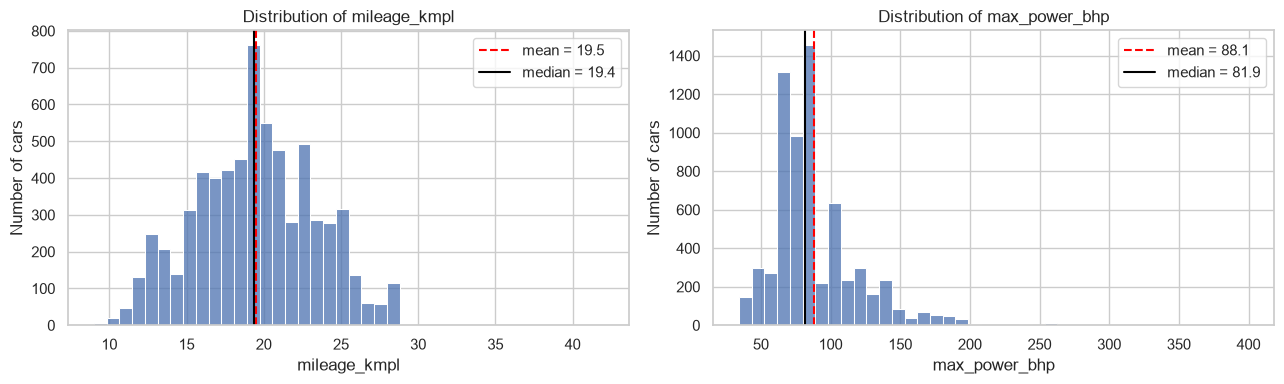

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["mileage_kmpl", "max_power_bhp"]):
    values = cars[col].dropna()
    sns.histplot(values, bins=40, ax=ax)
    ax.axvline(values.mean(), color="red", linestyle="--", label=f"mean = {values.mean():.1f}")
    ax.axvline(values.median(), color="black", label=f"median = {values.median():.1f}")
    ax.set(title=f"Distribution of {col}", xlabel=col, ylabel="Number of cars")
    ax.legend()
plt.tight_layout()
plt.show()

In [84]:
for col in ["mileage_kmpl", "max_power_bhp"]:
    print(f"{col}: mean={cars[col].mean():.2f}, median={cars[col].median():.2f}, skew={cars[col].skew():.2f}")

mileage_kmpl: mean=19.48, median=19.40, skew=0.03
max_power_bhp: mean=88.12, median=81.86, skew=1.71


**Decision.** `mileage_kmpl` is close to symmetric (skew 0.03; mean 19.48 vs median 19.40), so the mean and median would both work. `max_power_bhp` is clearly **right-skewed** (skew 1.71): a small number of high-power cars (up to 400 bhp) pull the mean (88.1) above the median (81.9). The median is the better simple imputation choice for power, and also for `engine_cc` (skew 1.2). For consistency and robustness, **the median is used for all three numeric columns**.

#### **Task 3.6 – Apply `SimpleImputer`**

`SimpleImputer` separates two stages:
- **`fit`** learns the replacement statistic (here the median) and stores it in `statistics_`.
- **`transform`** applies the stored value.

`fit_transform()` does both in one call. The split matters for machine learning: you fit on the training data only, then transform both the training and test data with the *training* median. `fillna(df.median())` recomputes the median from whatever data it is given, which leaks information from the test set.

In [85]:
num_imputer = SimpleImputer(strategy="median")
num_imputer.fit(cars[num_cols])
print("Learned medians:", dict(zip(num_cols, num_imputer.statistics_)))

cars_clean = cars.copy()
cars_clean[num_cols] = num_imputer.transform(cars[num_cols])

# seats is discrete, so use the mode. scikit-learn needs a 2-D input, hence [["seats"]].
seat_imputer = SimpleImputer(strategy="most_frequent")
cars_clean[["seats"]] = seat_imputer.fit_transform(cars[["seats"]])

missing_report(cars_clean)

Learned medians: {'mileage_kmpl': np.float64(19.4), 'engine_cc': np.float64(1248.0), 'max_power_bhp': np.float64(81.86)}


,missing,percent
name,0,0.0
year,0,0.0
selling_price,0,0.0
km_driven,0,0.0
fuel,0,0.0
seller_type,0,0.0
transmission,0,0.0
owner,0,0.0
seats,0,0.0
mileage_kmpl,0,0.0


#### **Task 3.7 – Validate the Cleaned Cars Dataset**

In [86]:
summary = pd.DataFrame({
    "before": [cars_before.shape, cars_before.isna().sum().sum(), cars_before.duplicated().sum()],
    "after": [cars_clean.shape, cars_clean.isna().sum().sum(), cars_clean.duplicated().sum()],
}, index=["shape", "missing cells", "duplicate rows"])
summary

,before,after
shape,"(8033, 12)","(6832, 12)"
missing cells,873,0
duplicate rows,1201,0


In [87]:
pd.concat({"before": cars_before[num_cols].describe(), "after": cars_clean[num_cols].describe()}, axis=1).round(2)

before                                after            \
      mileage_kmpl engine_cc max_power_bhp mileage_kmpl engine_cc   
count      7802.00   7819.00       7819.00      6832.00   6832.00   
mean         19.43   1463.09         91.94        19.48   1430.17   
std           3.90    504.66         35.77         3.85    488.25   
min           9.00    624.00         34.20         9.00    624.00   
25%          16.78   1197.00         69.00        16.96   1197.00   
50%          19.30   1248.00         82.40        19.40   1248.00   
75%          22.32   1582.00        102.00        22.32   1498.00   
max          42.00   3604.00        400.00        42.00   3604.00   

                     
      max_power_bhp  
count       6832.00  
mean          87.93  
std           31.30  
min           34.20  
25%           68.00  
50%           81.86  
75%           99.00  
max          400.00

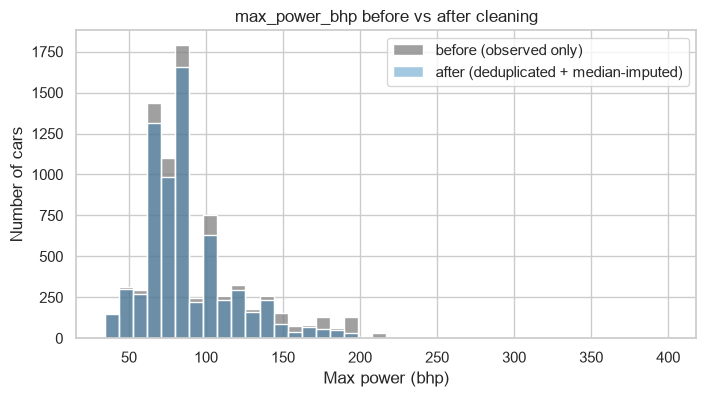

In [88]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(cars_before["max_power_bhp"].dropna(), bins=40, color="grey", label="before (observed only)", ax=ax)
sns.histplot(cars_clean["max_power_bhp"], bins=40, color="tab:blue", alpha=0.4, label="after (deduplicated + median-imputed)", ax=ax)
ax.set(title="max_power_bhp before vs after cleaning", xlabel="Max power (bhp)", ylabel="Number of cars")
ax.legend()
plt.show()

**Validation**

- **Shape** went from 8,033 to 6,832 rows (duplicates removed). **Missing cells** went from 873 to 0, and **duplicate rows** from 1,201 to 0.
- `mileage_kmpl` barely moved (mean 19.43 → 19.48, median 19.30 → 19.40).
- `max_power_bhp` fell (mean 91.94 → 87.93) and so did `engine_cc` (mean 1463 → 1430). The cause is the **deduplication**, not the imputation: the duplicated listings were disproportionately larger, more powerful cars, so they were inflating these averages.
- **The histogram keeps its shape after cleaning.** The bars are lower mainly because the duplicates are gone, most noticeably in the 150–200 bhp range. All 201 imputed values equal 81.86 bhp and land in the bin that was already the tallest (~80 bhp), so they create no new peak. With much heavier missingness, though, that single bin would grow out of proportion and distort the distribution.

### **Feature Engineering**

- **`power_per_litre`** = `max_power_bhp / (engine_cc / 1000)`. This dataset has no weight column, so engine size stands in for "how big is the car". The ratio shows how hard an engine is tuned: two 100 bhp cars behave differently with a 1.0 L and a 3.0 L engine.
- **Categorical features** (`fuel`, `transmission`, `seller_type`, `owner`) take the role that `Origin` plays in Auto MPG. Models need numbers, so each category becomes its own 0/1 column (one-hot encoding). `drop_first=True` drops one category per feature because it is implied: if `fuel_Petrol` is 0, the car is Diesel. Keeping it would make the columns perfectly redundant (the "dummy variable trap" for linear regression).
- **`name` is left out of the first model.** It has thousands of unique values, so one-hot encoding it would create thousands of near-empty columns.

In [89]:
cars_clean = add_power_per_litre(cars_clean)
print(cars_clean["power_per_litre"].describe().round(2))

# Always check the extremes of a new feature, because that is where bugs and oddities show up
cars_clean.nlargest(3, "power_per_litre")[["name", "engine_cc", "max_power_bhp", "power_per_litre"]]

count    6832.00
mean       62.71
std        12.17
min        21.31
25%        59.21
50%        64.83
75%        68.39
max       203.15
Name: power_per_litre, dtype: float64


,name,engine_cc,max_power_bhp,power_per_litre
167,Volvo XC90 T8 Excellence BSIV,1969.0,400.00,203.148807
1198,Ford Ecosport 1.0 Ecoboost Titanium Optional,999.0,123.37,123.493493
6351,Ford Ecosport 1.0 Ecoboost Titanium Optional,999.0,123.37,123.493493


In [90]:
cat_cols = ["fuel", "transmission", "seller_type", "owner"]
encoded_preview = pd.get_dummies(cars_clean[cat_cols], drop_first=True, dtype=int)
print(encoded_preview.columns.tolist())
encoded_preview.head(3)

['fuel_Petrol', 'transmission_Manual', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Test Drive Car', 'owner_Third Owner']


,fuel_Petrol,transmission_Manual,seller_type_Individual,seller_type_Trustmark Dealer,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,0,1,1,0,0,0,0,0
1,0,1,1,0,0,1,0,0
2,1,1,1,0,0,0,0,1


The typical car produces about **65 bhp per litre** (median 64.83). The maximum, 203 bhp/L, is a Volvo XC90 T8: a plug-in hybrid whose combined power rating is listed against a 2.0 L engine. It is a legitimate car rather than a data error, and it shows why the extremes of a new feature are worth checking. The four categorical columns become **8 binary columns** after encoding.

### **Exploratory Data Analysis**

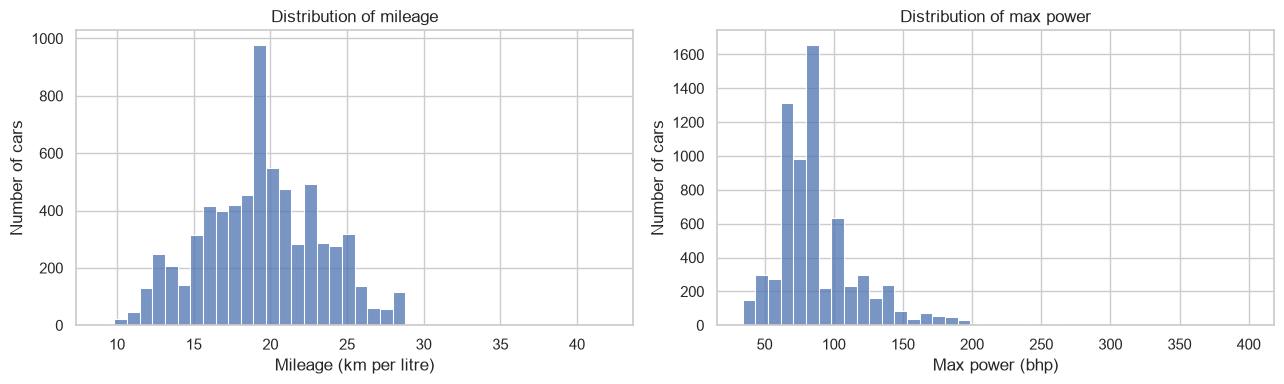

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(cars_clean["mileage_kmpl"], bins=40, ax=axes[0])
axes[0].set(title="Distribution of mileage", xlabel="Mileage (km per litre)", ylabel="Number of cars")
sns.histplot(cars_clean["max_power_bhp"], bins=40, ax=axes[1])
axes[1].set(title="Distribution of max power", xlabel="Max power (bhp)", ylabel="Number of cars")
plt.tight_layout()
plt.show()

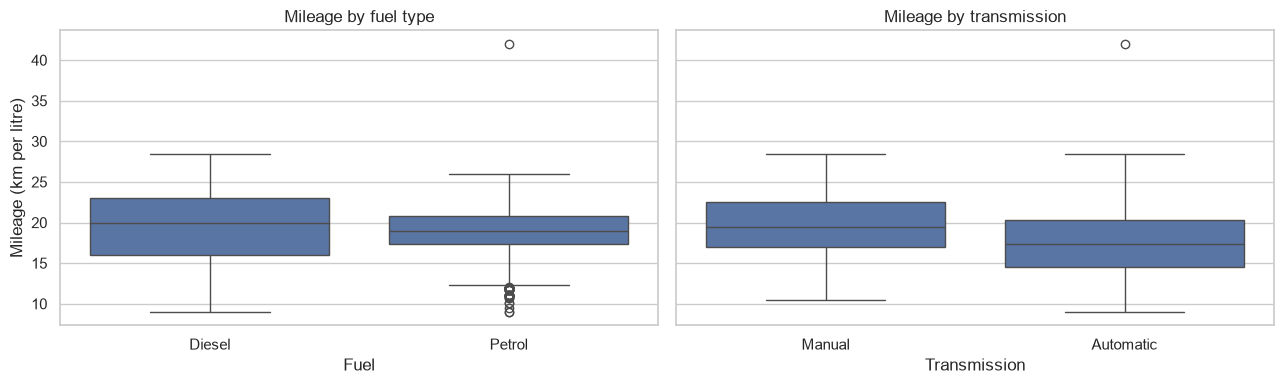

fuel
Diesel    20.0
Petrol    19.0
Name: mileage_kmpl, dtype: float64
transmission
Automatic    17.38
Manual       19.50
Name: mileage_kmpl, dtype: float64


In [92]:
# sharey=True puts both plots on the same mileage axis so they can be compared honestly
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
sns.boxplot(data=cars_clean, x="fuel", y="mileage_kmpl", ax=axes[0])
axes[0].set(title="Mileage by fuel type", xlabel="Fuel", ylabel="Mileage (km per litre)")
sns.boxplot(data=cars_clean, x="transmission", y="mileage_kmpl", ax=axes[1])
axes[1].set(title="Mileage by transmission", xlabel="Transmission", ylabel="")
plt.tight_layout()
plt.show()

print(cars_clean.groupby("fuel")["mileage_kmpl"].median())
print(cars_clean.groupby("transmission")["mileage_kmpl"].median())

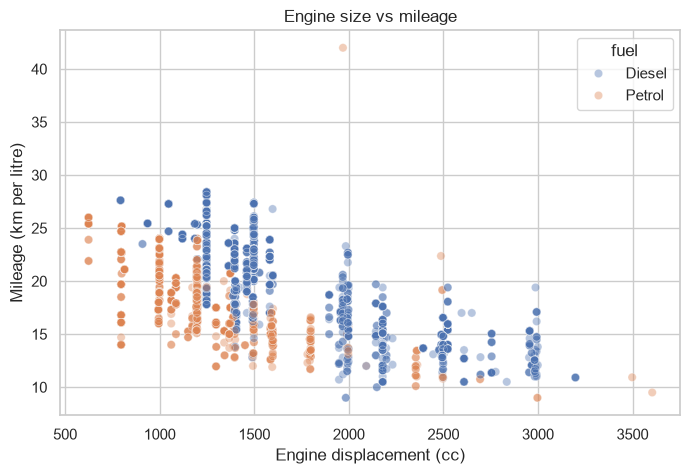

In [93]:
# alpha makes points semi-transparent, so dense regions show up darker
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=cars_clean, x="engine_cc", y="mileage_kmpl", hue="fuel", alpha=0.4, ax=ax)
ax.set(title="Engine size vs mileage", xlabel="Engine displacement (cc)", ylabel="Mileage (km per litre)")
plt.show()

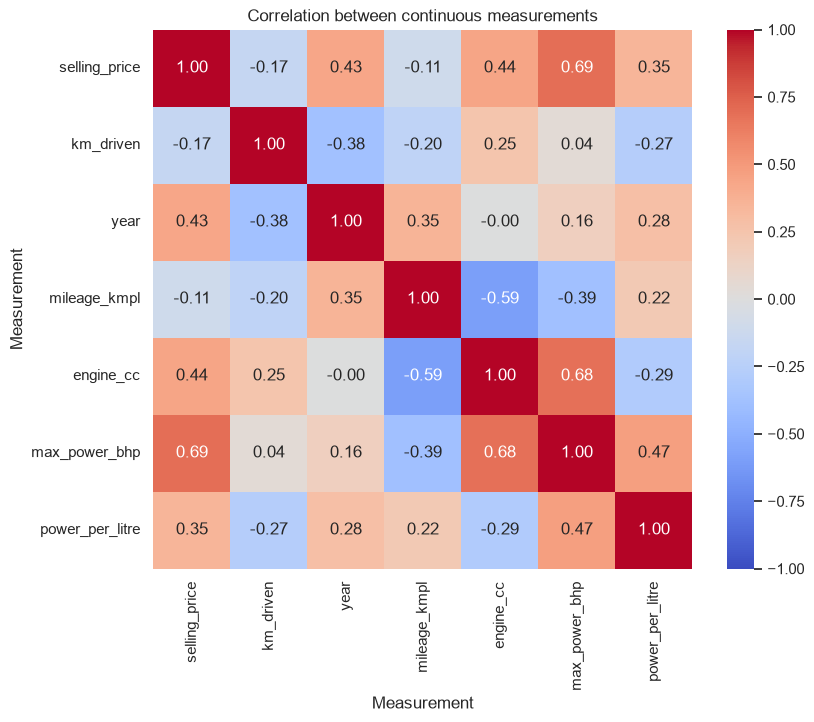

In [94]:
continuous = ["selling_price", "km_driven", "year", "mileage_kmpl", "engine_cc", "max_power_bhp", "power_per_litre"]
corr = cars_clean[continuous].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set(title="Correlation between continuous measurements", xlabel="Measurement", ylabel="Measurement")
plt.show()

**EDA observations**

- **Distributions.** Mileage is roughly bell-shaped, centred around 19–20 km/l. The unusually tall bar at about 19.4 km/l is partly the **216 imputed medians**, which is why the hypothesis test below uses observed values only. Max power is right-skewed: most cars fall between 60 and 120 bhp, with a long tail of premium vehicles.
- **Fuel type.** Diesel cars have a slightly higher median mileage (20.0 vs 19.0 km/l) and a much wider spread than petrol cars.
- **Transmission.** Manual cars are more efficient (median 19.5 vs 17.4 km/l). This is partly because automatics in this data tend to be larger, more powerful cars.
- **Engine size vs mileage.** There is a clear negative relationship (r = −0.59): bigger engines burn more fuel. The points form vertical stripes because manufacturers use a few standard engine sizes (about 1200, 1500 and 2000 cc). One petrol car sits far above the rest at **42 km/l**. It is the Volvo XC90 T8 plug-in hybrid (the same car that tops `power_per_litre`), whose official rating includes electric driving. It is a genuine car, but its mileage is not comparable with ordinary petrol cars.
- **Correlations.** Selling price tracks power most closely (r = 0.69). Engine size and power are strongly related (0.68), so a model using both carries some redundancy (multicollinearity). Newer cars have better mileage (year vs mileage r = 0.35) and fewer kilometres (−0.38). `power_per_litre` correlates *positively* with mileage (0.22), even though raw engine size correlates negatively: small, efficiently tuned engines are both frugal and punchy for their size.

### **Inferential Statistics – Diesel vs Petrol Mileage**

**The comparison is defined in advance**, before any test is run. Choosing a hypothesis after seeing which test comes out significant makes the p-value meaningless (p-hacking).

> **Question:** Do diesel and petrol cars in this dataset differ in fuel efficiency?
> **Variable:** `mileage_kmpl`, using **observed values only**. The deduplicated `cars` table is used, not `cars_clean`, because 216 imputed medians stacked at 19.4 would create a fake spike and understate the variance.
> **H₀:** mean mileage is the same for Diesel and Petrol cars. **H₁:** the means differ (two-sided).
> **Significance level:** α = 0.05.
> **Plan:** check normality per group (Q-Q plot and Shapiro–Wilk) and equal variances (Levene), then choose the two-sample test.

In [95]:
observed = cars.dropna(subset=["mileage_kmpl"])
diesel = observed.loc[observed["fuel"] == "Diesel", "mileage_kmpl"]
petrol = observed.loc[observed["fuel"] == "Petrol", "mileage_kmpl"]

pd.DataFrame({
    "n": [len(diesel), len(petrol)],
    "mean": [diesel.mean(), petrol.mean()],
    "median": [diesel.median(), petrol.median()],
    "std": [diesel.std(), petrol.std()],
}, index=["Diesel", "Petrol"]).round(2)

,n,mean,median,std
Diesel,3653,19.77,20.0,4.56
Petrol,2963,19.12,18.9,2.87


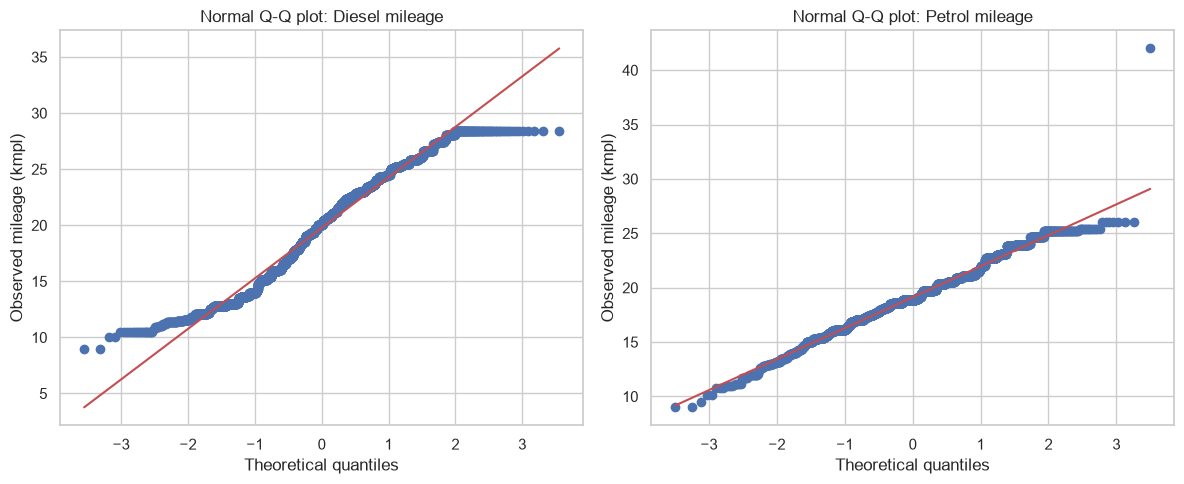

In [96]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (label, values) in zip(axes, [("Diesel", diesel), ("Petrol", petrol)]):
    stats.probplot(values, dist="norm", plot=ax)
    ax.set(title=f"Normal Q-Q plot: {label} mileage", xlabel="Theoretical quantiles", ylabel="Observed mileage (kmpl)")
plt.tight_layout()
plt.show()

In [97]:
for label, values in [("Diesel", diesel), ("Petrol", petrol)]:
    w, p = stats.shapiro(values)
    print(f"Shapiro-Wilk {label}: W = {w:.4f}, p = {p:.2e}")

lev = stats.levene(diesel, petrol)
print(f"Levene (equal variances): W = {lev.statistic:.1f}, p = {lev.pvalue:.2e}")

Shapiro-Wilk Diesel: W = 0.9719, p = 3.22e-26
Shapiro-Wilk Petrol: W = 0.9858, p = 1.13e-16
Levene (equal variances): W = 947.8, p = 1.25e-194


**Checking the assumptions**

- **Normality.** Shapiro–Wilk rejects normality for both groups (p < 0.001). However, W ≈ 0.97–0.99 is *very close* to 1. With thousands of observations, Shapiro–Wilk flags even trivial departures from normality, so the Q-Q plots matter more. **Petrol** follows the line closely across almost its whole range. The only clear departure is the single hybrid at 42 km/l in the top-right corner. **Diesel** follows the line through the middle but flattens into plateaus at both ends (around 10–11 km/l and 28.4 km/l). Its tails are *lighter* than a normal distribution's, because diesel mileage values are bounded: 85 unique listings share the 28.4 km/l maximum. Neither group is exactly normal, but neither is badly skewed.
- **Equal variances.** Levene's test strongly rejects equal variances: the diesel spread (std 4.56) is much larger than the petrol spread (2.87).

**Choice of test**

- The groups are independent, but the variances differ, so Student's t-test is ruled out.
- With n ≈ 3,000 per group, the **Central Limit Theorem** makes the *sampling distribution of the mean* approximately normal even though the raw data are not.
- The primary test is therefore **Welch's t-test** (`equal_var=False`). As a robustness check, the **Mann–Whitney U** test, which makes no normality assumption, is also run. If both agree, the conclusion does not depend on the normality assumption.

In [98]:
welch = stats.ttest_ind(diesel, petrol, equal_var=False)
print(f"Welch's t-test: t = {welch.statistic:.2f}, df = {welch.df:.0f}, p = {welch.pvalue:.2e}")

mwu = stats.mannwhitneyu(diesel, petrol, alternative="two-sided")
print(f"Mann-Whitney U: U = {mwu.statistic:.0f}, p = {mwu.pvalue:.2e}")

# Effect size: a significant result is not necessarily an important one
pooled_sd = np.sqrt(((len(diesel) - 1) * diesel.var() + (len(petrol) - 1) * petrol.var()) / (len(diesel) + len(petrol) - 2))
cohens_d = (diesel.mean() - petrol.mean()) / pooled_sd
print(f"Mean difference = {diesel.mean() - petrol.mean():.2f} kmpl, Cohen's d = {cohens_d:.2f}")

Welch's t-test: t = 6.97, df = 6246, p = 3.41e-12
Mann-Whitney U: U = 5981641, p = 1.64e-13
Mean difference = 0.64 kmpl, Cohen's d = 0.16


**Interpretation**

Both tests reject H₀ at α = 0.05: Welch's t = 6.97 (df ≈ 6,246, p ≈ 3.4 × 10⁻¹²) and Mann–Whitney U also gives p ≈ 1.6 × 10⁻¹³. Diesel cars in this dataset are **more fuel-efficient on average than petrol cars**.

However, the difference is **small in practical terms**: about **0.64 km/l** on means and 1.1 km/l on medians, with **Cohen's d = 0.16** (where 0.2 counts as "small"). The p-value is tiny because the sample is large, not because the effect is big. With about 6,600 cars, even a modest difference is detected with near certainty.

**Caveat.** This is observational data, so the test shows that the groups differ, not *why*. Diesel and petrol cars also differ in engine size, vehicle type and age, so fuel type alone should not be read as the cause.

### **Optional – Predicting Mileage with Regression**

**Goal:** predict `mileage_kmpl` from the car's other characteristics, compare the model against a simple baseline, and evaluate it on held-out data.

In [99]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

model_df = add_power_per_litre(cars.dropna(subset=["mileage_kmpl"]))

numeric_features = ["year", "km_driven", "engine_cc", "max_power_bhp", "power_per_litre", "seats"]
categorical_features = ["fuel", "transmission", "seller_type", "owner"]

X = model_df[numeric_features + categorical_features]
y = model_df["mileage_kmpl"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")


Train: (5292, 10), Test: (1324, 10)


In [100]:
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_features),
])


def evaluate(name, regressor):
    pipe = Pipeline([("prep", clone(preprocess)), ("model", regressor)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    scores = {
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": root_mean_squared_error(y_test, pred),
        "R2": r2_score(y_test, pred),
        "MAPE (%)": mean_absolute_percentage_error(y_test, pred) * 100,
    }
    return scores, pipe, pred


In [101]:
baseline_scores, baseline_pipe, baseline_pred = evaluate("Baseline (predict mean)", DummyRegressor(strategy="mean"))
linreg_scores, linreg_pipe, linreg_pred = evaluate("Linear regression", LinearRegression())

pd.DataFrame([baseline_scores, linreg_scores]).set_index("model").round(3)


,MAE,RMSE,R2,MAPE (%)
model,,,,
Baseline (predict mean),3.234,4.016,-0.000,18.031
Linear regression,1.660,2.118,0.722,8.782


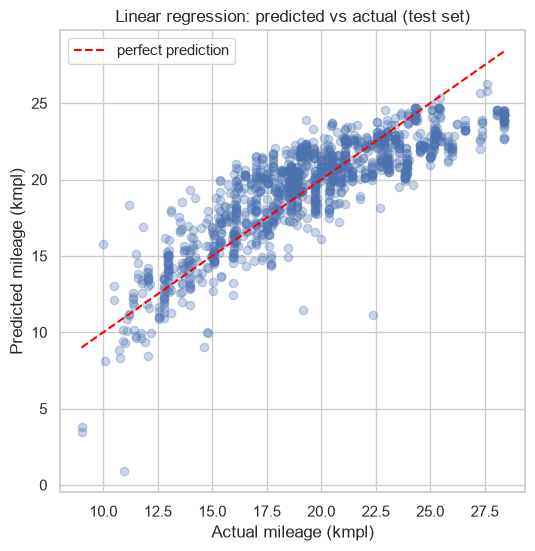

In [102]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, linreg_pred, alpha=0.3)
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, color="red", linestyle="--", label="perfect prediction")
ax.set(
    title="Linear regression: predicted vs actual (test set)",
    xlabel="Actual mileage (kmpl)",
    ylabel="Predicted mileage (kmpl)",
)
ax.legend()
plt.show()


**Model results**

- The **baseline** (always predicting the training mean) has MAE 3.23 km/l and R² ≈ 0, as expected, since R² measures improvement over the mean.
- **Linear regression** roughly **halves the error**: MAE 1.66 km/l, RMSE 2.12 km/l, R² 0.72. The features explain about 72% of the variation in mileage on cars the model never saw during training.
- **MAPE 8.8%:** a typical prediction is within about 9% of the true mileage, against 18.0% for the baseline. Regression has no "accuracy" in the classification sense (a continuous prediction is almost never exactly right), so R², MAE and MAPE together describe how close the predictions are.
- RMSE is only somewhat larger than MAE, so the model makes some larger misses but no extreme ones.
- In the predicted-vs-actual plot, most points follow the diagonal, with a pattern typical of linear regression: the model **under-predicts the most efficient cars** (actual 25–28 km/l are mostly predicted at 22–24) and tends to **over-predict thirsty cars**, pulling predictions toward the average. A few predictions are physically implausible (about 1–4 km/l for cars that actually achieve 9–11 km/l), which shows that a straight-line model can extrapolate badly for unusual cars.

**Why this evaluation is trustworthy:** duplicates were removed before splitting, the target was never imputed, and imputation and encoding were learned from the training set only inside the pipeline. No information from the test set leaked into training.

**Possible next steps:** a non-linear model such as a random forest, adding brand extracted from `name`, or cross-validation for a more stable estimate than a single split.


#### **Task 3.8 – Cars Reflection**

**1. What were the main data-quality problems?**
- **Numbers stored as text.** `mileage`, `engine` and `max_power` had their units glued on (`"23.4 kmpl"`, `"1248 CC"`, `"74 bhp"`), so pandas read them as strings.
- **A hidden placeholder.** One `max_power` value was `" bhp"`, a unit with no number. pandas counted it as present even though it carried no information.
- **Mixed units.** 88 mileage values were in km/kg (CNG/LPG cars) rather than km/l.
- **Impossible values.** 17 cars had 0 km/l and 6 had 0 bhp.
- **Missing values.** About 3% of cars were missing their technical specs, and usually all of them at once.
- **Duplicates.** 1,201 exact duplicate listings, about 15% of the Diesel/Petrol rows.
- **An unusable column.** `torque` mixed units (Nm and kgm) and rpm ranges, so it was too inconsistent to use without heavy parsing.

**2. How many missing values did you find?**
In the raw file: `mileage` 221, `engine` 221, `max_power` 215 (216 once the `" bhp"` placeholder is counted), `torque` 222 and `seats` 221. After restricting to Diesel/Petrol cars and recoding impossible zeros as missing, there were **873 missing cells** across 8,033 rows. That is `mileage_kmpl` 231 (2.88%) plus `engine_cc`, `max_power_bhp` and `seats` at 214 each (2.66%). After deduplication, 819 missing cells remained across 6,832 rows.

**3. What happened when you dropped rows containing missing values?**
The data went from 6,832 to 6,616 rows: **216 cars (3.2%) were lost.** That is a modest loss, but the dropped rows are not a random sample. 201 of the 216 are listings missing *all* their specifications (the other 15 had an impossible 0 km/l mileage), so dropping them can bias the data if those listings differ systematically (for example, by coming from a particular kind of seller).

**4. Why might dropping entire columns be inappropriate?**
`dropna(axis=1)` removed `mileage_kmpl`, `engine_cc`, `max_power_bhp` and `seats`, which are the most informative features in the dataset, to avoid about 3% missingness. More than 97% of the valid values in those columns would be thrown away. Dropping a column only makes sense when most of it is missing or it is irrelevant.

**5. When is mean imputation reasonable?**
When the variable is roughly symmetric with no strong outliers and only a small share is missing, the mean is a fair "typical" value. `mileage_kmpl` is an example: skew 0.03, mean 19.48 vs median 19.40, so the two are almost interchangeable.

**6. When might median be safer than mean?**
When the distribution is skewed or has outliers, because the median is not pulled by extreme values. `max_power_bhp` is right-skewed (skew 1.71), and a few cars of up to 400 bhp drag the mean (88.12) well above the median (81.86). Filling with the mean would assign a typical car more power than it really has.

**7. Where would mode imputation be appropriate?**
For categorical or discrete variables, where an average is meaningless. `seats` was filled with its mode, 5, because a car cannot have 5.44 seats. Mode imputation would also suit `fuel` or `transmission` if those columns had missing values.

**8. How did `SimpleImputer` differ from manually calling `fillna()`?**
`SimpleImputer` separates **`fit`** (learn and store the statistic in `statistics_`) from **`transform`** (apply it). The learned medians (19.4 km/l, 1,248 cc, 81.86 bhp) can then be reused unchanged on new data. In machine learning this means fitting on the training set only and applying the *training* median to the test set, which avoids leakage. It also handles several columns in one step and plugs directly into a scikit-learn `Pipeline`. `fillna(df.median())` recomputes the statistic from whatever data it is given, and has to be written column by column.

**9. Did cleaning materially change the dataset statistics?**
For mileage, barely: the mean moved from 19.43 to 19.48 km/l. For power and engine size, yes. Mean power fell from 91.94 to 87.93 bhp and mean engine size from 1,463 to 1,430 cc. Comparing the strategies shows this came mostly from **removing duplicates**, which had over-represented larger, more powerful cars, rather than from imputation. Imputation's main side effect was a small reduction in standard deviation (for example, 31.75 → 31.30 bhp for power), because many identical values were added at the centre.

**10. Which cleaning decisions would you carry forward into an ML pipeline, and why?**
- **Deterministic fixes** (parsing units, recoding placeholders and zeros as missing, dropping `torque`) belong in reusable code, as already done in `src/car_dataset/`. They follow fixed rules and learn nothing from the data, so they are safe to apply before splitting.
- **Remove duplicates before the train/test split.** Otherwise the same car can appear in both sets and inflate the test score.
- **Keep the CNG/LPG exclusion**, or model those cars separately, because their mileage is in different units.
- **Median imputation (and mode imputation for `seats`) inside a `Pipeline` via `SimpleImputer`,** so the statistics are learned from training data only.
- **One-hot encode the categorical features inside the pipeline** with `OneHotEncoder(handle_unknown="ignore")`, so categories seen only in the test data don't cause errors.
- **Never impute the target.** Rows with missing `mileage_kmpl` are dropped before modelling, because the model would otherwise be trained to predict the median.

---
## **Answer to the Research Question**

> **Do diesel cars achieve significantly better fuel efficiency (mileage) than petrol cars, and how well can a car's listed characteristics (engine size, power, age, fuel type, transmission) predict its mileage?**

**Part 1: yes, diesel cars are significantly more efficient, but only slightly.**

| | Diesel | Petrol |
|---|---|---|
| Cars (observed mileage) | 3,653 | 2,963 |
| Mean mileage | 19.77 km/l | 19.12 km/l |
| Median mileage | 20.0 km/l | 18.9 km/l |

- Welch's t-test: t = 6.97, p ≈ 3.4 × 10⁻¹². Mann–Whitney U confirms it (p ≈ 1.6 × 10⁻¹³).
- **Effect size is small** (Cohen's d = 0.16; mean difference 0.64 km/l). The result is highly significant because the sample is large, not because the gap is big.

**Part 2: mileage is fairly predictable from the listing.**

| Model (held-out test set, 1,324 cars) | MAE | MAPE | R² |
|---|---|---|---|
| Baseline (always predict the mean) | 3.23 km/l | 18.0% | 0.00 |
| Linear regression | **1.66 km/l** | **8.8%** | **0.72** |

- The model explains about **72%** of the variation in mileage and **halves** the baseline's error. A typical prediction is within about 9% of the true value.
- **Engine size** is the strongest single factor (r = −0.59 with mileage: bigger engines, lower mileage). Newer cars are more efficient (r = 0.35), and manual cars beat automatics (median 19.5 vs 17.4 km/l).

**How we got here**

1. **Preparation:** units were stripped from text columns, 95 CNG/LPG cars (mileage in km/kg) were excluded, impossible zeros were recoded as missing, **1,201 duplicate listings** were removed, and the remaining ~3% of missing values were median/mode-imputed with `SimpleImputer`.
2. **Feature engineering:** `power_per_litre` was added, and the categorical columns were one-hot encoded.
3. **EDA:** showed diesel's slightly higher median mileage, the manual-vs-automatic gap, and the strong negative engine-size relationship.
4. **Inferential statistics:** Q-Q plots and Shapiro–Wilk showed the data are not exactly normal. With large samples (CLT), Welch's t-test is still valid, and Mann–Whitney U confirmed the result.
5. **Regression:** a pipeline that learns imputation and encoding from the training set only, compared against a mean baseline on held-out data.

**Limitations**

- This is **observational** data. It shows *association*, not *causation*. Diesel and petrol cars also differ in engine size, body type and age, so fuel type alone is not shown to *cause* the mileage difference.
- The mileage values appear to be **listed ratings** rather than measured real-world consumption (for example, 85 unique diesel listings, covering 14 different models, share exactly 28.4 km/l).
- The conclusions apply to **diesel and petrol cars only**, because CNG/LPG cars were excluded.
- The linear model **under-predicts the most efficient cars** and makes a few implausible predictions for unusual cars. A non-linear model (for example, a random forest) or adding the brand from `name` are natural next steps.

# **Section 4 – Diabetes: Data Preparation, EDA, Inferential Statistics & Outlier Detection**

**PROG8245 – Lab 2: Tidying, Cleaning, Imputation, and Outlier Detection**

This notebook takes a raw diabetes dataset all the way from a cloud database to a statistically tested answer:

| Part | What happens | Why it matters |
|---|---|---|
| **0. Setup & Neon** | Load the data from a Neon PostgreSQL database into pandas | Real projects read data from databases, not loose files |
| **1. Data Preparation** | Clean, validate, and engineer features | Every later result is only as good as this foundation |
| **2. EDA** | Visualise distributions and relationships | Understand the data *before* testing anything |
| **3. Inferential Statistics** | Normality checks (Q-Q + Shapiro-Wilk) → t-tests | Decide whether differences are real or just chance |
| **4. Outlier Detection** | Lab tasks 4.1 – 4.8: box plot, scatter, Z-score, IQR, treatment | Check how extreme values affect our conclusions |

All reusable logic lives in classes inside [`src/diabetes_dataset/`](src/diabetes_dataset/) so this notebook stays readable. Each class is explained the first time it is used.

### **The Research Question**

> **Do diabetic patients have significantly higher blood glucose, BMI, and systolic blood pressure than non-diabetic patients — and does that conclusion still hold once outliers are taken into account?**

Why these three measurements?

- **Glucose** – high blood sugar is the defining feature of diabetes, so we expect a large difference. It is a good "sanity check" for our method.
- **BMI** – excess body weight is one of the best-known risk factors for type 2 diabetes.
- **Systolic blood pressure** – hypertension and diabetes frequently occur together.

Every part of the notebook feeds this question: **preparation** makes the measurements trustworthy, **EDA** gives us a first look at the group differences, **inferential statistics** tests them formally, and **outlier detection** checks whether a handful of extreme values are driving the result.

#### A note about the dataset

The lab handout describes the 768-row *Pima Indians Diabetes* file. This notebook uses **`data/diabetes_dataset.csv`** instead: **5,288 patients × 15 columns**, with readings such as age, gender, pulse rate, blood pressure, glucose (in **mmol/L**), height, weight, BMI, family history flags, and a `diabetic` (Yes/No) outcome.

All Section 4 techniques (box plots, scatter plots, Z-scores, IQR, treatment) apply exactly the same way. Only the column names are different.

---
## **Part 0 – Setup**

### 0.1 Imports

- **pandas / numpy** – tables and maths
- **matplotlib / seaborn** – charts
- **scipy.stats** – statistical tests
- **`diabetes_dataset`** – *our own* package in `src/`. Python only finds it if the `src` folder is on its search path (`sys.path`), so we add it first.

In [103]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the project root whether Jupyter was started in the project folder or in notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from diabetes_dataset import (
    NeonDatabase,
    DiabetesDataPreparer,
    EDAVisualizer,
    NormalityChecker,
    GroupComparison,
    OutlierDetector,
    format_p_values,
)
from diabetes_dataset.config import (
    RAW_CSV_PATH,
    RAW_TABLE_NAME,
    ENV_VAR_NAME,
    NUMERIC_FEATURES,
    ANALYSIS_FEATURES,
    TARGET,
    ALPHA,
    Z_THRESHOLD,
    IQR_MULTIPLIER,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
%matplotlib inline

print("Project root:", PROJECT_ROOT)
print("Raw CSV     :", RAW_CSV_PATH.relative_to(PROJECT_ROOT))

Project root: /Users/namy/Desktop/SCHOOL/Machine Learning Programming/PROG8245-Lab2-Tidying_Cleaning_Imputation_Outlier-Detection
Raw CSV     : data/diabetes_dataset.csv


### 0.2 Load the data from Neon

**Neon** is a cloud-hosted PostgreSQL database. The workflow is:

```text
data/diabetes_dataset.csv ──one-time upload script──▶ Neon table "diabetes_raw" ──SELECT … ORDER BY row_id──▶ pandas DataFrame
```

#### Where does the password go?
The connection string contains your username and password, so it must **never** be written into the notebook or committed to GitHub. It lives in a file called **`.env`** in the project root:

```text
NEON_DATABASE_URL=postgresql://<user>:<password>@<host>/<database>?sslmode=require
```

`.env` is already listed in `.gitignore`, so Git ignores it. The `python-dotenv` package reads the file and exposes the value as an *environment variable*.

#### The `NeonDatabase` class ([database.py](src/common/database.py))

| Method | What it does |
|---|---|
| `NeonDatabase.from_env()` | Reads `.env` and opens a connection (a SQLAlchemy *engine*) |
| `test_connection()` | Runs `SELECT version()` to prove we are connected |
| `read_ordered(table)` | Runs `SELECT * FROM table ORDER BY row_id` and returns a DataFrame with `pd.read_sql()`, in the CSV's original row order |
| `list_tables()` | Lists the tables in the database |

**The notebook only reads.** The CSV is loaded into Neon once with `PYTHONPATH=src python -m diabetes_dataset.upload` (run from the project root). The script stores a `row_id` so the original row order can be restored, replaces the table if it already exists, and verifies the Neon copy matches the CSV. Because the notebook never writes, it works with a read-only database login.

> **Fallback:** until you paste a real connection string into `.env`, the cell below prints a warning and reads the CSV directly so the rest of the notebook still runs.

In [104]:
connection_string = NeonDatabase.read_connection_string()

if connection_string:
    db = NeonDatabase(connection_string)
    print("Connected to:", db.test_connection()[:60], "...")

    print("Tables in database:", db.list_tables())

    # Read the table in its original row order (it is uploaded once by diabetes_dataset.upload)
    raw_df = db.read_ordered(RAW_TABLE_NAME)
    data_source = f"Neon table '{RAW_TABLE_NAME}'"
    db.close()
else:
    print(f"WARNING: {ENV_VAR_NAME} is not set in .env - reading the local CSV instead of Neon.")
    raw_df = pd.read_csv(RAW_CSV_PATH)
    data_source = "local CSV (fallback)"

print(f"\nLoaded {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns from {data_source}")

Connected to: PostgreSQL 18.6 (653b019) on aarch64-unknown-linux-gnu, comp ...
Tables in database: ['npors25_raw', 'employees', 'ontario_housing', 'car_details_raw', 'npors23_raw', 'npors24_raw', 'npors_value_labels', 'billboard_hot100_raw', 'billboard_audio_features_raw', 'diabetes_raw']



Loaded 5,288 rows x 15 columns from Neon table 'diabetes_raw'


---
## **Part 1 – Data Preparation Pipeline**

Before any chart or test we need a **clean foundation**. The `DiabetesDataPreparer` class ([preprocessing.py](src/diabetes_dataset/preprocessing.py)) breaks the work into small steps:

| Step | Method | Purpose |
|---|---|---|
| 1 | `standardise_columns()` | Consistent lowercase `snake_case` column names |
| 2 | `clean_categoricals()` | Trim/case-fix text so `"female "` and `"Female"` are one category |
| 3 | `enforce_dtypes()` | Make numbers numeric and Yes/No flags small integers |
| 4 | `remove_duplicates()` | Drop exact duplicate rows |
| 5 | `remove_implausible_rows()` | Drop physiologically **impossible** values (data errors) |
| 6 | `drop_missing()` | Drop anything still missing |
| 7 | `engineer_features()` | Add new, more useful columns |

Each step records rows before/after in a log, and the class always works on a **copy**, so `raw_df` stays untouched as our baseline.

### 1.1 First look at the raw data

In [105]:
print("Shape:", raw_df.shape)
display(raw_df.head())

Shape: (5288, 15)


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,1.65,70.2,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,1.47,42.5,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,1.52,47.0,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,1.63,57.4,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,1.42,36.0,17.79,0,0,0,0,0,No


In [106]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5288 entries, 0 to 5287
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     5288 non-null   int64  
 1   gender                  5288 non-null   str    
 2   pulse_rate              5288 non-null   int64  
 3   systolic_bp             5288 non-null   int64  
 4   diastolic_bp            5288 non-null   int64  
 5   glucose                 5288 non-null   float64
 6   height                  5288 non-null   float64
 7   weight                  5288 non-null   float64
 8   bmi                     5288 non-null   float64
 9   family_diabetes         5288 non-null   int64  
 10  hypertensive            5288 non-null   int64  
 11  family_hypertension     5288 non-null   int64  
 12  cardiovascular_disease  5288 non-null   int64  
 13  stroke                  5288 non-null   int64  
 14  diabetic                5288 non-null   str    
dty

**What we see:** 15 columns, no obvious text-vs-number problems. `gender` and `diabetic` are text; the five history columns (`family_diabetes`, `hypertensive`, …) are 0/1 flags; the rest are measurements.

### 1.2 Data-quality report

`quality_report()` builds one table with each column's data type, missing values, number of unique values, and number of zeros. Zeros matter because in medical data a zero often means "not measured" rather than a real reading.

In [107]:
preparer = DiabetesDataPreparer(raw_df)
display(preparer.quality_report())
print("Duplicate rows:", raw_df.duplicated().sum())

,dtype,missing,missing_%,unique,zeros
age,int64,0,0.0,60,0
gender,str,0,0.0,2,0
pulse_rate,int64,0,0.0,91,0
systolic_bp,int64,0,0.0,136,0
diastolic_bp,int64,0,0.0,73,0
glucose,float64,0,0.0,937,1
height,float64,0,0.0,54,0
weight,float64,0,0.0,509,0
bmi,float64,0,0.0,1370,0
family_diabetes,int64,0,0.0,2,5119


Duplicate rows: 0


**Interpretation**

- **No missing values (NaN)** and **no duplicate rows**.
- Zeros in the 0/1 flag columns are expected (0 = "no").
- One patient has **glucose = 0**. That is impossible for a living person, so a clean-looking file can still hide bad values. That is why we run the next check.

### 1.3 Checking for impossible values

`describe()` shows the minimum and maximum of every measurement. Extremes that can't happen in a real patient show up quickly here.

In [108]:
display(raw_df[NUMERIC_FEATURES].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age,5288.0,45.75,13.42,21.00,35.00,45.00,55.00,80.00
pulse_rate,5288.0,76.63,12.23,5.00,69.00,76.00,84.00,133.00
systolic_bp,5288.0,134.00,22.23,62.00,119.00,130.00,147.00,231.00
diastolic_bp,5288.0,82.23,12.48,45.00,73.00,81.00,90.00,119.00
glucose,5288.0,7.56,2.94,0.00,6.00,6.93,8.13,33.46
height,5288.0,1.55,0.08,0.36,1.52,1.55,1.60,1.96
weight,5288.0,53.64,10.08,3.00,46.78,53.00,59.90,100.70
bmi,5288.0,22.47,8.82,1.22,19.62,21.87,24.47,574.13


Several minimums and maximums are physically impossible:

- **height 0.36 m** and **BMI 574** (the world-record BMI is around 200)
- **weight 3 kg** for an adult
- **pulse 5 beats/min**
- **glucose 0 – 1.9 mmol/L** (below about 2 mmol/L a patient would be unconscious)

These are **data errors** such as typos, wrong units, or a sensor fault. They are not genuine extreme patients. `implausible_value_report()` checks every column against the medically plausible ranges stored in [config.py](src/diabetes_dataset/config.py) (`PLAUSIBLE_RANGES`).

In [109]:
display(preparer.implausible_value_report())

invalid_rows = raw_df[preparer.invalid_row_mask()]
print(f"Rows with at least one impossible value: {len(invalid_rows)} "
      f"({len(invalid_rows) / len(raw_df):.2%} of the data)")
print("\nOutcome of those rows:")
print(invalid_rows[TARGET].value_counts())
display(invalid_rows.head(10))

,allowed_min,allowed_max,observed_min,observed_max,below_min,above_max,total_invalid
feature,,,,,,,
age,18.0,110.0,21.00,80.00,0,0,0
pulse_rate,30.0,220.0,5.00,133.00,3,0,3
systolic_bp,60.0,260.0,62.00,231.00,0,0,0
diastolic_bp,30.0,160.0,45.00,119.00,0,0,0
glucose,2.0,40.0,0.00,33.46,26,0,26
height,1.0,2.3,0.36,1.96,3,0,3
weight,25.0,300.0,3.00,100.70,4,0,4
bmi,10.0,80.0,1.22,574.13,2,2,4


Rows with at least one impossible value: 35 (0.66% of the data)

Outcome of those rows:
diabetic
No     34
Yes     1
Name: count, dtype: int64


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
152,24,Male,63,165,89,4.89,0.36,72.6,574.13,0,0,0,0,0,No
157,32,Male,77,106,73,1.17,1.60,52.1,20.35,0,0,0,0,0,No
613,44,Female,81,114,72,1.61,1.37,55.8,29.66,0,0,0,0,0,No
680,55,Male,77,123,91,0.89,1.63,62.7,23.73,0,0,0,0,0,No
718,36,Female,68,140,96,1.09,1.50,46.5,20.71,0,0,0,0,0,No
726,25,Female,88,145,91,0.43,1.50,42.0,18.70,0,0,0,0,0,No
885,75,Female,71,200,89,7.24,0.64,62.8,155.74,0,1,0,0,0,No
1138,28,Female,98,181,92,0.00,1.52,55.0,23.81,0,0,0,0,0,No
1279,46,Female,104,100,59,12.00,1.57,3.0,1.22,0,0,0,0,0,No
1308,50,Female,89,130,89,0.84,1.52,54.1,23.29,0,0,0,0,0,No


#### Decision: drop the impossible rows (do not impute)

- They are **errors, not outliers**. A value that cannot exist tells us nothing about real patients.
- There are only **35 rows (0.66 %)**, so very little information is lost.
- **Imputing** them (for example, with the median, as in Section 3) would put made-up values into the exact columns we are about to test. That would artificially shrink the spread and could bias the t-tests.
- Only **one** of the 35 is diabetic, so dropping them barely changes the class balance.

> **Errors vs. outliers:** in this notebook, Part 1 removes values that are *impossible*. Section 4 deals with values that are *possible but unusual* (statistical outliers). Those are kept unless there is a clear reason to remove them.

### 1.4 Feature engineering

`engineer_features()` adds columns that make the data easier to analyse:

| New column | How it is built | Why |
|---|---|---|
| `diabetic_flag` | `1` if diabetic = "Yes", else `0` | The mean of a 0/1 column is a rate ("% diabetic") |
| `bmi` (recalculated) | weight ÷ height² | Guarantees BMI matches height and weight |
| `pulse_pressure` | systolic − diastolic | Marker of arterial stiffness |
| `age_group` | `pd.cut` into decades | Trends are easier to read in bands |
| `bmi_category` | WHO cut-offs 18.5 / 25 / 30 | Underweight / Normal / Overweight / Obese |
| `bp_category` | ACC/AHA cut-offs | Normal / Elevated / Stage 1 / Stage 2 |

### 1.5 Run the full pipeline

`run()` calls every step in order. This is called **method chaining**: each method returns the object itself (`return self`), so the calls can be written one after another.

In [110]:
preparer = DiabetesDataPreparer(raw_df)
df = preparer.run()

display(preparer.summary())
print("Clean shape:", df.shape)
display(df.head())

,step,rows_before,rows_after,rows_removed
0,standardise column names,5288,5288,0
1,"clean text categories (gender, diabetic)",5288,5288,0
2,enforce data types,5288,5288,0
3,remove duplicate rows (0 found),5288,5288,0
4,remove rows with impossible values (35 rows),5288,5253,35
5,drop rows with missing values (0 rows),5253,5253,0
6,"engineer features (diabetic_flag, bmi, pulse_p...",5253,5253,0


Clean shape: (5253, 20)


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic,diabetic_flag,pulse_pressure,age_group,bmi_category,bp_category
0,42,Female,66,110,73,5.88,1.65,70.2,25.79,0,0,0,0,0,No,0,37,40-49,Overweight,Normal
1,35,Female,60,125,68,5.71,1.47,42.5,19.67,0,0,0,0,0,No,0,57,30-39,Normal,Elevated
2,62,Female,57,127,74,6.85,1.52,47.0,20.34,0,0,0,0,0,No,0,53,60-69,Normal,Elevated
3,73,Male,55,193,112,6.28,1.63,57.4,21.60,0,0,0,0,0,No,0,81,70+,Normal,Stage 2
4,68,Female,71,150,81,5.71,1.42,36.0,17.85,0,0,0,0,0,No,0,69,60-69,Underweight,Stage 2


### 1.6 Validate the cleaned data

**Assertions** are automatic checks. If any condition is false, the cell stops with an error. They protect the analysis from silently running on bad data if the source ever changes.

In [111]:
assert df.isna().sum().sum() == 0, "There should be no missing values"
assert df.duplicated().sum() == 0, "There should be no duplicate rows"
assert (df["systolic_bp"] > df["diastolic_bp"]).all(), "Systolic must exceed diastolic"
assert set(df[TARGET].unique()) == {"Yes", "No"}, "Target must be Yes/No"
assert len(raw_df) == 5288, "raw_df must be unchanged (baseline)"

print("All validation checks passed.")
print(f"Rows: {len(raw_df):,} raw  ->  {len(df):,} clean  ({len(raw_df) - len(df)} removed)")
print(df[TARGET].value_counts())
display(df[["bmi_category", "bp_category", "age_group"]].describe())

All validation checks passed.
Rows: 5,288 raw  ->  5,253 clean  (35 removed)
diabetic
No     4912
Yes     341
Name: count, dtype: int64


,bmi_category,bp_category,age_group
count,5253,5253,5253
unique,4,4,6
top,Normal,Stage 2,30-39
freq,3330,2120,1521


---
## **Part 2 – Exploratory Data Analysis (EDA)**

EDA means *looking* at the data before testing it. The `EDAVisualizer` class ([eda.py](src/diabetes_dataset/eda.py)) provides one method per chart, and each method returns its figure.

### 2.1 How balanced is the outcome?

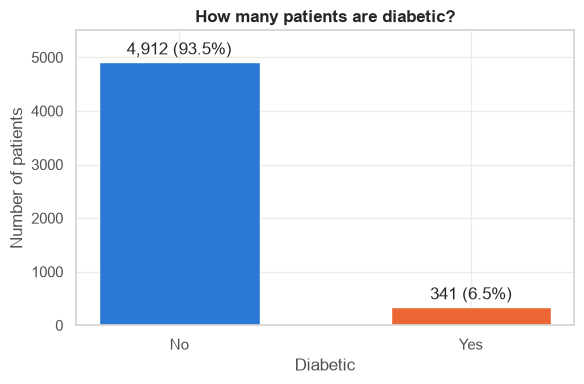

In [112]:
eda = EDAVisualizer(df)
eda.plot_target_balance()
plt.show()

Only **about 6.5 %** of patients are diabetic (341 vs 4,912). This **class imbalance** matters for two reasons:

1. The two groups have very different sizes, so later we use **Welch's t-test**, which does not assume equal group sizes or variances.
2. Any outlier rule that removes many diabetic patients could wipe out a large share of a small group. We check this in Section 4.

### 2.2 Distribution of each measurement

A **histogram** counts how many patients fall into each value range, and the smooth line (KDE) traces its shape. **Skewness** gives the shape as a number:

- **≈ 0** → symmetric (bell-shaped)
- **> 0** → long tail to the right (a few very high values)
- **< 0** → long tail to the left

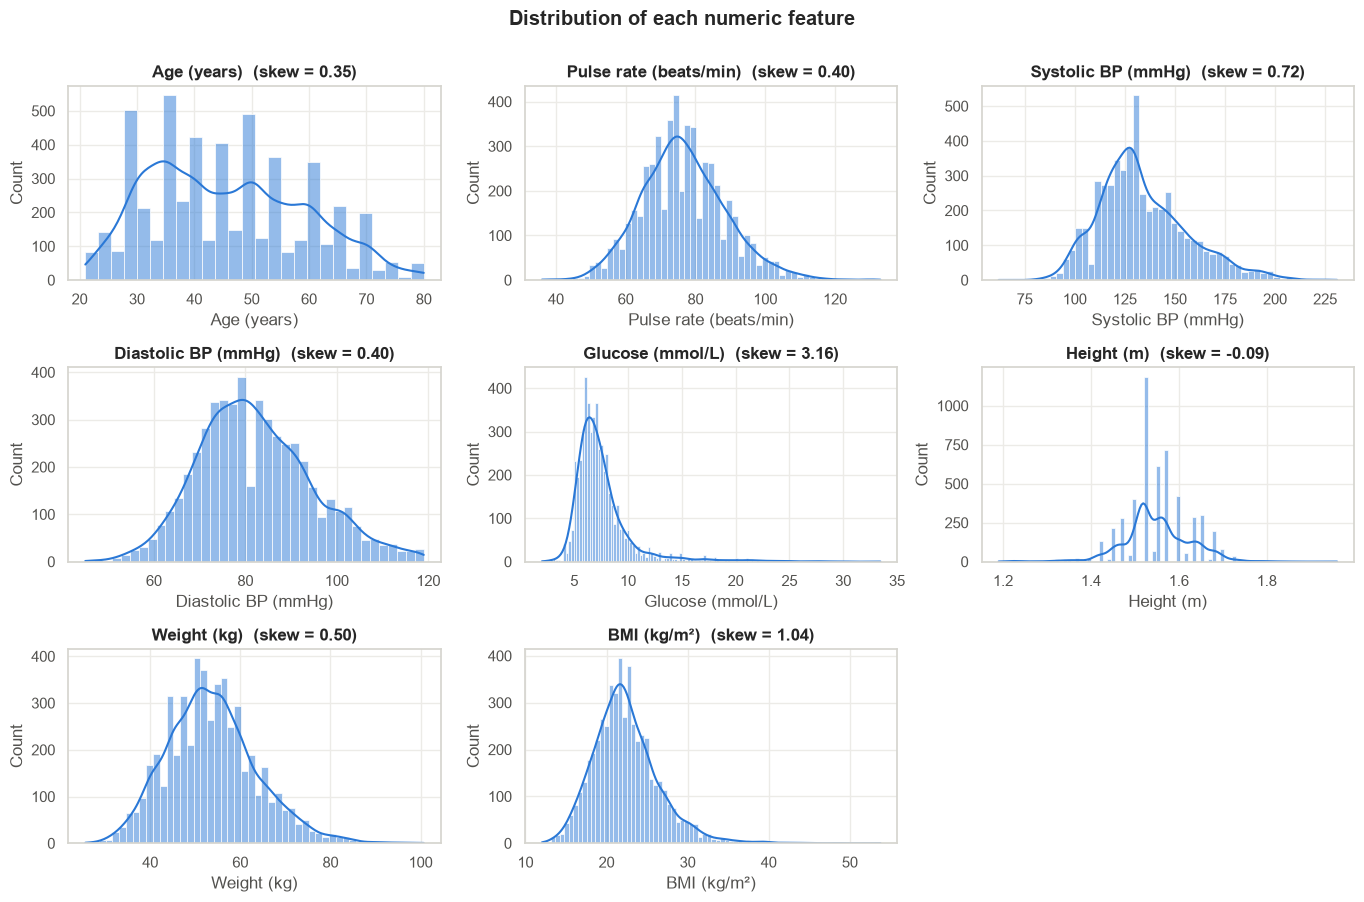

In [113]:
eda.plot_distributions(NUMERIC_FEATURES)
plt.show()

**Observations**

- **Glucose** is strongly **right-skewed** (skew ≈ 3). Most patients sit around 5–9 mmol/L, with a long tail up past 30.
- **BMI** is moderately right-skewed (≈ 1).
- **Age, blood pressure, height, and weight** are fairly symmetric.
- None of the measurements is perfectly bell-shaped. We return to this in the formal normality checks in Part 3.

### 2.3 Do the groups look different?

A **box plot** per group lets us compare medians and spreads side by side.

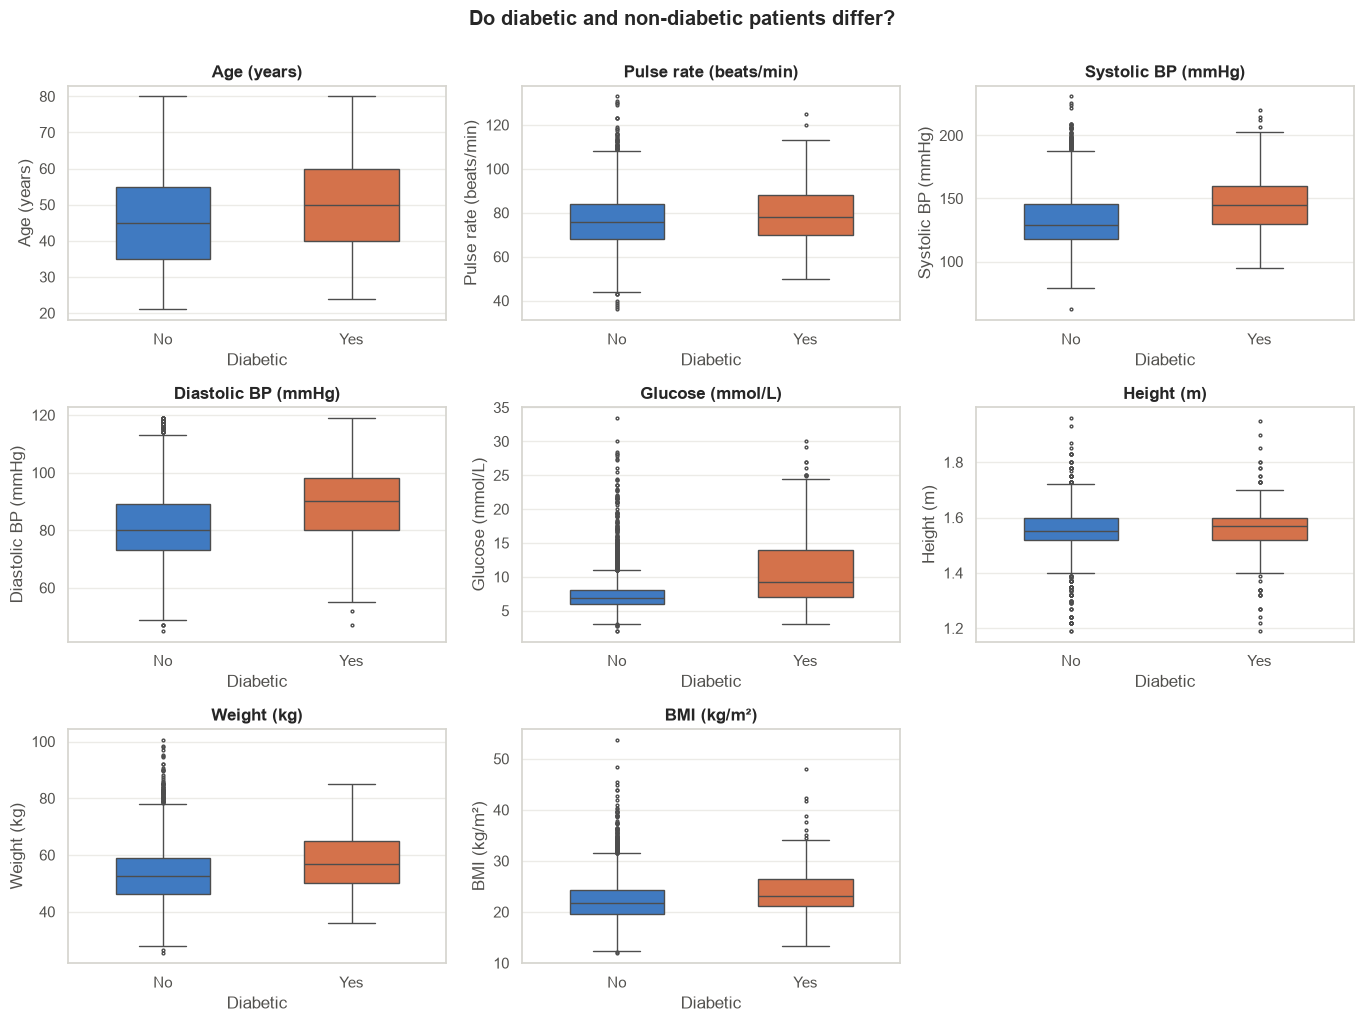

Summary of the three research-question features by group:


diabetic                No     Yes
glucose     mean      7.36   11.01
            median    6.86    9.28
            std       2.47    5.39
bmi         mean     22.27   23.89
            median   21.83   23.19
            std       4.05    4.46
systolic_bp mean    133.05  147.04
            median  129.00  145.00
            std      21.90   22.63

In [114]:
eda.plot_by_target(NUMERIC_FEATURES)
plt.show()

print("Summary of the three research-question features by group:")
display(eda.group_summary(ANALYSIS_FEATURES))

**Observations relevant to the research question**

- **Glucose:** the diabetic group's median is clearly higher (≈ 9.3 vs 6.9 mmol/L), and their spread is about twice as large.
- **Systolic BP:** diabetic patients are about **14 mmHg higher** on average.
- **BMI:** diabetic patients are higher, but only by about **1.6 kg/m²**, and the boxes overlap heavily.
- **Age** is also higher in the diabetic group, which is expected since type 2 diabetes becomes more common with age.

These are only *visual* differences. Part 3 tests whether they are bigger than random chance would produce.

### 2.4 Relationships between measurements

A **correlation heatmap** shows the Pearson correlation *r* between each pair of features (−1 = perfect negative, 0 = none, +1 = perfect positive).

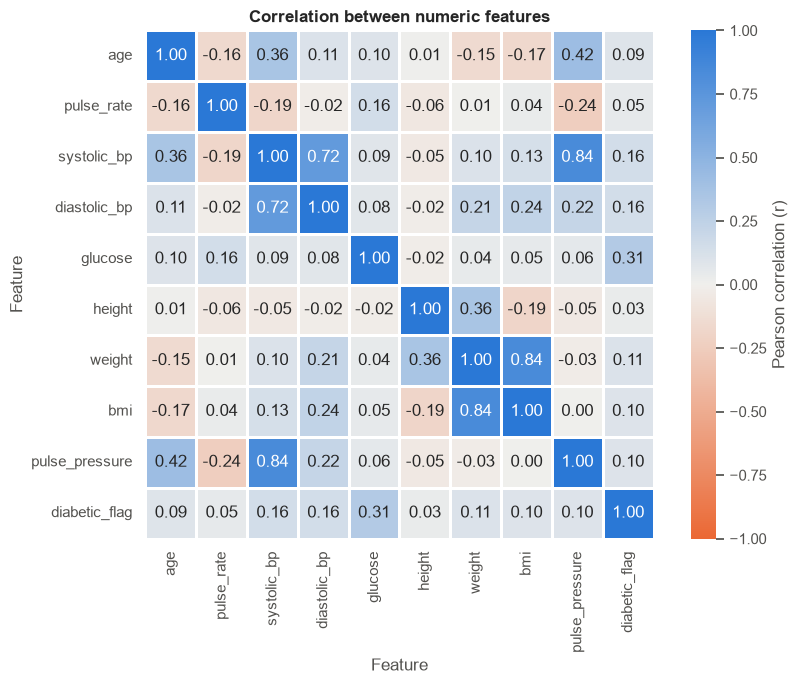

In [115]:
eda.plot_correlation_heatmap(NUMERIC_FEATURES + ["pulse_pressure", "diabetic_flag"])
plt.show()

**Observations**

- **Systolic & diastolic BP** are strongly correlated, as expected.
- **Weight ↔ BMI** is strongly correlated, because BMI is calculated from weight.
- **Glucose** has by far the strongest correlation with `diabetic_flag` (r ≈ 0.31), followed by **systolic and diastolic BP** (r ≈ 0.16).
- **BMI**'s correlation with `diabetic_flag` is weak (r ≈ 0.10). This suggests BMI will show the smallest group difference.
- All correlations with the outcome are modest. No single measurement separates the groups on its own.

### 2.5 Diabetes rate across engineered categories

The engineered features let us see how the **rate** of diabetes changes across groups.

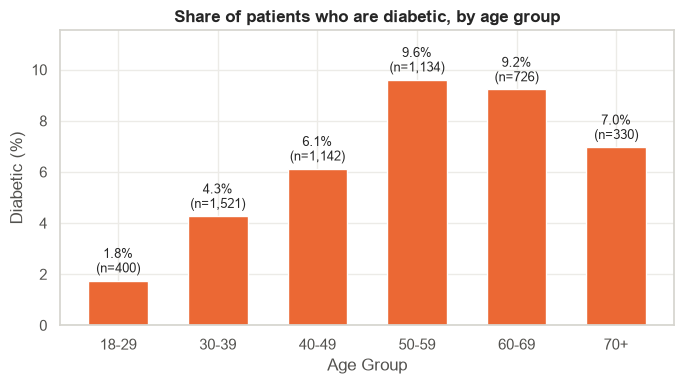

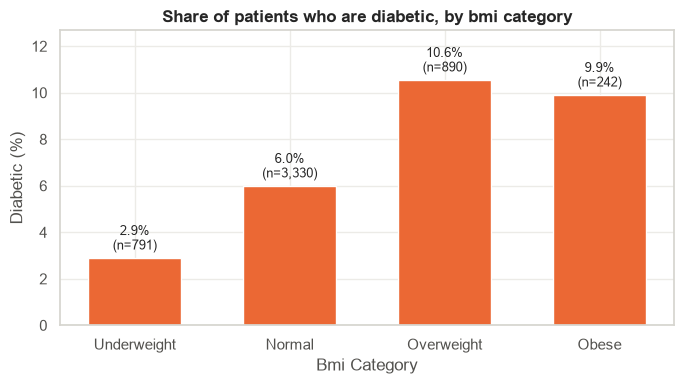

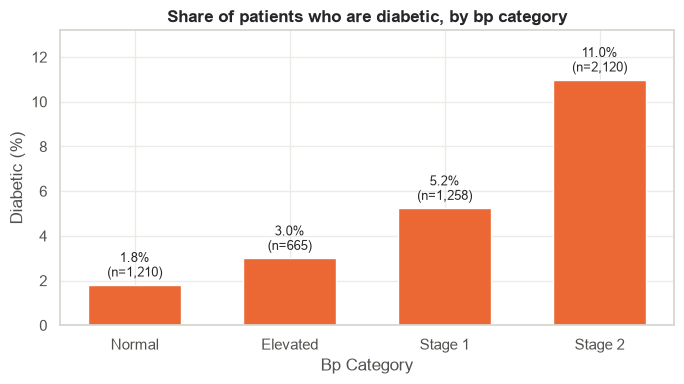

In [116]:
eda.plot_rate_by_category("age_group")
plt.show()
eda.plot_rate_by_category("bmi_category")
plt.show()
eda.plot_rate_by_category("bp_category")
plt.show()

**Observations**

- The diabetes rate rises from about **2 % in 18–29-year-olds to roughly 10 % at 50–59**.
- **Overweight/Obese** patients have more than **3× the rate** of underweight patients (about 10 % vs 3 %).
- The rate climbs steadily across blood-pressure categories, from about **2 % (Normal) to 11 % (Stage 2)**, which fits the known link between hypertension and diabetes.

**EDA conclusion:** all three research-question measurements *look* higher in diabetic patients. The next step is to test this formally.

---
## **Part 3 – Inferential Statistics**

EDA describes **this sample**. Inferential statistics asks whether what we see would hold for the **wider population**, or whether it could be random variation.

### 3.0 The hypotheses

For each feature (glucose, BMI, systolic BP):

- **H₀ (null hypothesis):** mean(diabetic) = mean(non-diabetic). There is no real difference.
- **H₁ (alternative hypothesis):** mean(diabetic) ≠ mean(non-diabetic).
- **Significance level:** α = 0.05. If the p-value is below 0.05, we reject H₀.

> **What is a p-value?** It is the probability of seeing a difference at least this large *if H₀ were true*. A tiny p-value means the observed difference would be very surprising under "no real difference", so we reject H₀.

### 3.1 Why we check normality first

The **independent-samples t-test** assumes each group's values come from a roughly **normal** (bell-shaped) distribution. So before running any t-test we do two mandatory checks:

1. **Q-Q plot** – a visual check
2. **Shapiro-Wilk test** – a formal check

Both are run **separately for each group**, because the assumption applies to each group on its own. The `NormalityChecker` class ([hypothesis_tests.py](src/diabetes_dataset/hypothesis_tests.py)) handles both.

### 3.2 Normality check 1 – Q-Q plots

A **Q-Q (quantile-quantile) plot** sorts the data and plots each value against where it *would* fall if the data were perfectly normal.

- Dots **on the straight line** → normal
- Dots **curving upward at the right end** → right skew / a heavy upper tail
- An **S-shape** → tails that are heavier or lighter than normal

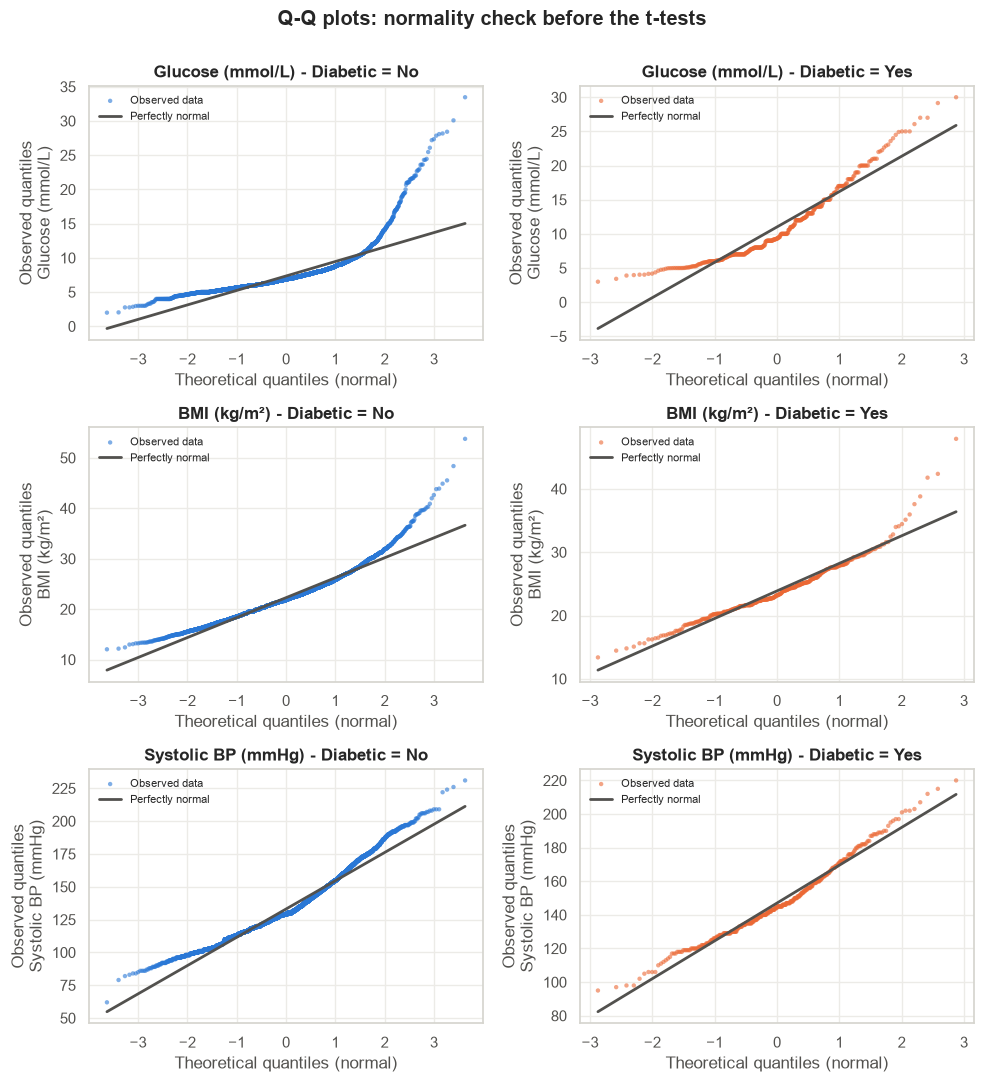

In [117]:
normality = NormalityChecker(df)
normality.plot_qq(ANALYSIS_FEATURES)
plt.show()

**Reading the Q-Q plots**

- **Glucose (both groups):** the dots bend sharply upward on the right, so the distribution is clearly **not normal** (heavy right tail). This is worst for non-diabetic patients.
- **BMI:** close to the line in the middle but curving up at the right, so it is **right-skewed**.
- **Systolic BP:** the closest to normal, with only mild departure at the ends.

### 3.3 Normality check 2 – Shapiro-Wilk test

- **H₀:** the data are normally distributed.
- **W** is close to 1 for normal data.
- **p < 0.05** → reject H₀ → **not normal**.

In [118]:
shapiro_results = normality.shapiro_wilk(ANALYSIS_FEATURES)
display(format_p_values(shapiro_results))

,feature,group,n,skewness,W,p_value,is_normal
0,glucose,No,4912,3.442,0.7287,4.22e-67,False
1,glucose,Yes,341,1.050,0.9094,1.94e-13,False
2,bmi,No,4912,1.031,0.9544,1.18e-36,False
3,bmi,Yes,341,1.134,0.9431,3.58e-10,False
4,systolic_bp,No,4912,0.737,0.9656,1.06e-32,False
5,systolic_bp,Yes,341,0.549,0.9774,3.42e-05,False


**Interpretation**

Every feature in every group has **p < 0.05**, so the Shapiro-Wilk test says *none* of them is perfectly normal. That matches the Q-Q plots.

**Does this mean we cannot use a t-test?** Not necessarily. Two points matter:

1. **Shapiro-Wilk is very sensitive with large samples.** With 4,912 non-diabetic patients, even a tiny, harmless departure from normality gives p < 0.05. This is why we always look at the Q-Q plot too.
2. **The Central Limit Theorem (CLT).** The t-test actually depends on the *sample mean* being normally distributed, not the raw values. The CLT says sample means become approximately normal as *n* grows, even if the raw data are skewed. With n = 341 and n = 4,912, both groups are large enough.

**Our plan, based on these checks:**

- Run **Welch's t-test**, which is valid here thanks to the CLT and does not assume equal variances.
- **Confirm** each result with the **Mann-Whitney U test**, a *non-parametric* test that makes no normality assumption at all.
- If both tests agree, the conclusion does not depend on the normality assumption.

### 3.4 Equal variances? Levene's test

The classic (Student's) t-test also assumes both groups have the same **variance** (spread). **Levene's test** checks this (H₀: the variances are equal). The `GroupComparison` class runs it alongside the t-tests.

### 3.5 Welch's t-tests, Mann-Whitney U, and effect sizes

For each feature, `GroupComparison.compare_all()` reports:

| Column | Meaning |
|---|---|
| `mean_Yes`, `mean_No`, `mean_diff` | Group means and the difference between them |
| `levene_p` | p < 0.05 → the variances differ → Welch's test is the right choice |
| `welch_t`, `welch_df`, `welch_p` | Welch's t-test result |
| `mannwhitney_p` | Non-parametric confirmation |
| `cohens_d` | **Effect size**: how *big* the difference is, in standard deviations (0.2 small, 0.5 medium, 0.8 large) |

In [119]:
comparison = GroupComparison(df, group_a="Yes", group_b="No")
ttest_results = comparison.compare_all(ANALYSIS_FEATURES)
display(format_p_values(ttest_results))

,mean_Yes,mean_No,mean_diff,levene_p,welch_t,welch_df,welch_p,mannwhitney_p,cohens_d,effect_size,significant
feature,,,,,,,,,,,
glucose,11.01,7.36,3.66,1.27e-101,12.443,350.0,1.11e-29,7.15e-42,1.327,large,True
bmi,23.89,22.27,1.61,4.82e-02,6.496,379.8,2.60e-10,1.64e-12,0.396,small,True
systolic_bp,147.04,133.05,13.99,2.78e-01,11.067,385.6,6.58e-25,6.42e-30,0.638,medium,True


### 3.6 Interpretation

| Feature | Difference (diabetic − not) | Welch p | Mann-Whitney p | Cohen's d | Verdict |
|---|---|---|---|---|---|
| **Glucose** | ≈ +3.7 mmol/L | ≪ 0.001 | ≪ 0.001 | ≈ 1.3 (**large**) | Significant |
| **Systolic BP** | ≈ +14 mmHg | ≪ 0.001 | ≪ 0.001 | ≈ 0.6 (**medium**) | Significant |
| **BMI** | ≈ +1.6 kg/m² | ≪ 0.001 | ≪ 0.001 | ≈ 0.4 (**small**) | Significant |

- For **all three** features we **reject H₀**: diabetic patients have significantly higher mean glucose, systolic BP, and BMI.
- **Mann-Whitney agrees every time**, so the non-normality found in 3.2–3.3 does not change the conclusion.
- **Significance is not the same as importance.** With 5,000+ patients even small differences become "significant". Cohen's d shows that the **glucose** difference is large, **blood pressure** is moderate, and **BMI** is real but small.

**Preliminary answer:** yes, all three are significantly higher in diabetic patients. Section 4 now checks the second half of the question: *does this still hold once outliers are dealt with?*

---
## **Section 4 – Outlier Detection (Diabetes Dataset)**

### **Learning Topic: Outlier Detection and Treatment**

An **outlier** is an observation that differs substantially from most of the data. Outliers can come from measurement errors, data-entry problems, unusual but legitimate cases, or genuinely rare events.

Outliers can distort means and standard deviations, correlations, regression coefficients, distance-based algorithms, scaling, and model evaluation.

**Important:** detecting an outlier does **not** automatically mean it should be deleted. Treatment has to be justified in the context of the data.

The `OutlierDetector` class ([outliers.py](src/diabetes_dataset/outliers.py)) implements every method used below. It never changes the DataFrame it is given. Instead it returns **boolean masks** (a True/False table where `True` = potential outlier), which we can count, plot, or use to build a cleaned *copy*.

#### **Task 4.1 – Load and Explore the Diabetes Dataset**

The data was loaded from Neon in Part 0 and cleaned in Part 1. Here we confirm what we are working with and choose the features to examine.

In [120]:
print("Data source:", data_source)
print("Raw shape  :", raw_df.shape, "  Clean shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:")
print(df.dtypes.value_counts())

print("\nMissing values in clean data:", int(df.isna().sum().sum()))
print("Impossible values removed in Part 1:", len(raw_df) - len(df))

print("\nNumeric features examined for outliers:", NUMERIC_FEATURES)
display(df[NUMERIC_FEATURES].describe().T.round(2))

Data source: Neon table 'diabetes_raw'
Raw shape  : (5288, 15)   Clean shape: (5253, 20)

Columns: ['age', 'gender', 'pulse_rate', 'systolic_bp', 'diastolic_bp', 'glucose', 'height', 'weight', 'bmi', 'family_diabetes', 'hypertensive', 'family_hypertension', 'cardiovascular_disease', 'stroke', 'diabetic', 'diabetic_flag', 'pulse_pressure', 'age_group', 'bmi_category', 'bp_category']

Data types:
int64       5
Int8        5
float64     4
category    1
str         1
int8        1
category    1
category    1
category    1
Name: count, dtype: int64

Missing values in clean data: 0
Impossible values removed in Part 1: 35

Numeric features examined for outliers: ['age', 'pulse_rate', 'systolic_bp', 'diastolic_bp', 'glucose', 'height', 'weight', 'bmi']


,count,mean,std,min,25%,50%,75%,max
age,5253.0,45.73,13.41,21.00,35.00,45.00,55.00,80.00
pulse_rate,5253.0,76.67,12.11,36.00,69.00,76.00,84.00,133.00
systolic_bp,5253.0,133.96,22.22,62.00,119.00,130.00,147.00,231.00
diastolic_bp,5253.0,82.22,12.49,45.00,73.00,81.00,90.00,119.00
glucose,5253.0,7.59,2.90,2.00,6.00,6.94,8.14,33.46
height,5253.0,1.55,0.08,1.19,1.52,1.55,1.60,1.96
weight,5253.0,53.68,10.04,25.60,46.80,53.00,60.00,100.70
bmi,5253.0,22.38,4.09,12.04,19.65,21.89,24.46,53.77


**Which features, and why?** We examine all eight continuous measurements (`NUMERIC_FEATURES`). The 0/1 history flags are left out because a value can only be 0 or 1, so "extreme" has no meaning for them.

**Missing/invalid values:** there are no NaNs. The 35 impossible readings (glucose ≈ 0, height 0.36 m, BMI 574, pulse 5, …) were already removed in Part 1, so everything examined below is at least *physically possible*.

#### **Task 4.2 – Box Plot Method**

How to read a box plot:

| Part | Meaning |
|---|---|
| **Box** | Middle 50 % of the data, from **Q1** (25th percentile) to **Q3** (75th percentile) |
| **Line inside the box** | **Median** (50th percentile) |
| **Box height** | **IQR** = Q3 − Q1 |
| **Whiskers** | Extend to the furthest point still within **1.5 × IQR** of the box |
| **Red dots** | Points beyond the whiskers → **potential outliers** |

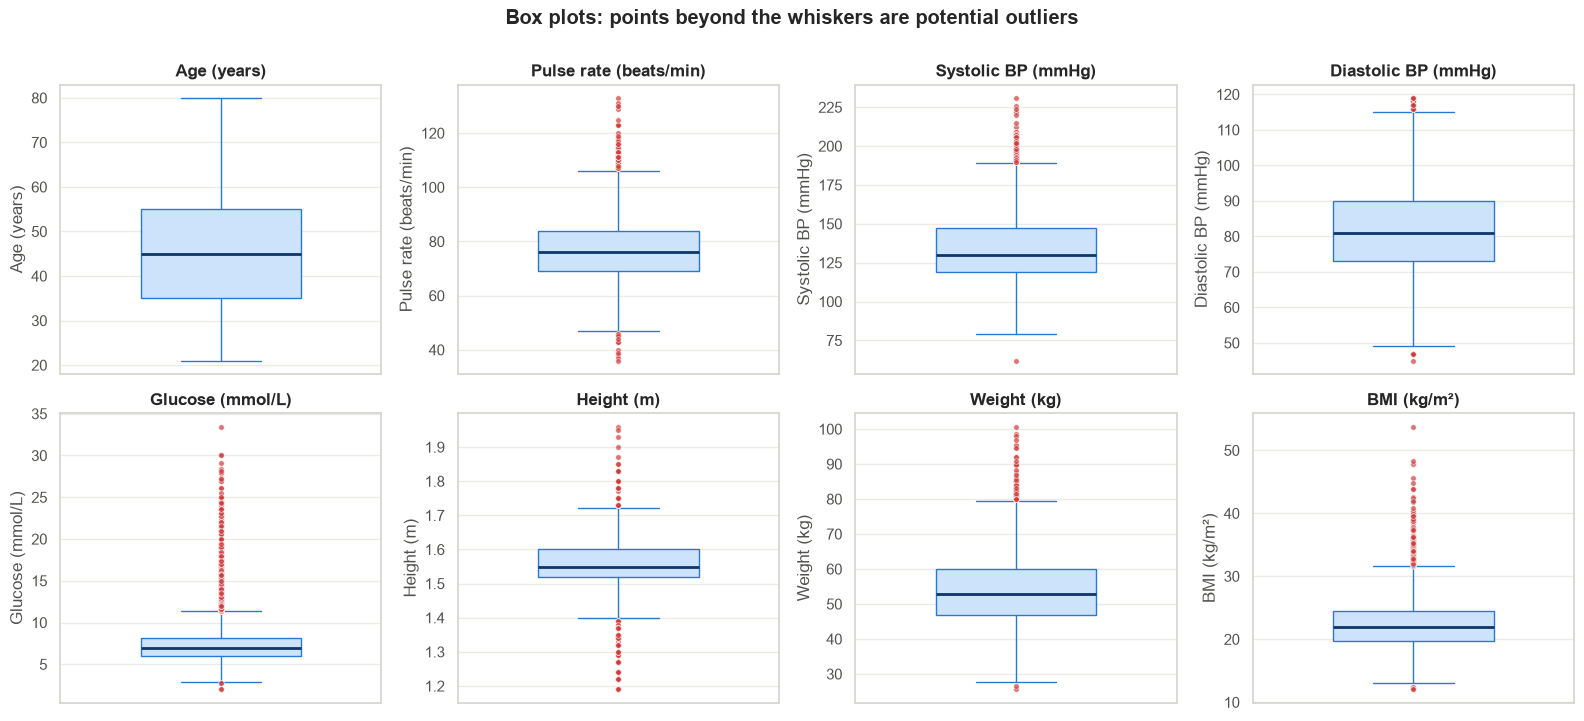

Points beyond the whiskers per feature:
glucose         366
height          186
bmi             132
systolic_bp     111
pulse_rate       93
weight           75
diastolic_bp     54
age               0
Name: box_plot, dtype: int64


In [121]:
detector = OutlierDetector(df, NUMERIC_FEATURES)
detector.plot_boxplots()
plt.show()

print("Points beyond the whiskers per feature:")
print(detector.boxplot_flier_counts().sort_values(ascending=False))

**Observations**

- **Glucose** has by far the most extreme values: a long column of red dots above about 11.4 mmol/L, all on the **high** side.
- **Height** has many points on *both* sides. Its IQR is very narrow (1.52–1.60 m), so even ordinary tall or short people fall outside the whiskers.
- **BMI, systolic BP, and pulse rate** have upper-tail outliers.
- **Age** has **no** outliers: every age from 21 to 80 is within the whiskers.

#### **Task 4.3 – Scatter Plot Method**

A scatter plot shows **two** features at once, so it can reveal points that are unusual in *combination* even when neither value is extreme on its own.

**Glucose vs BMI** links our two main metabolic measurements. Points are coloured by diabetic status. Red rings mark values flagged by the Z-score rule (|z| > 3) on either axis, which is computed formally in Task 4.4.

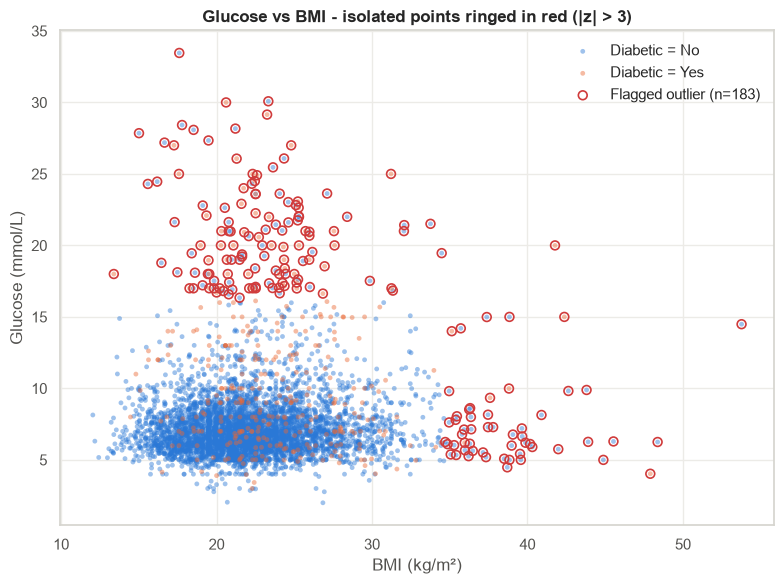

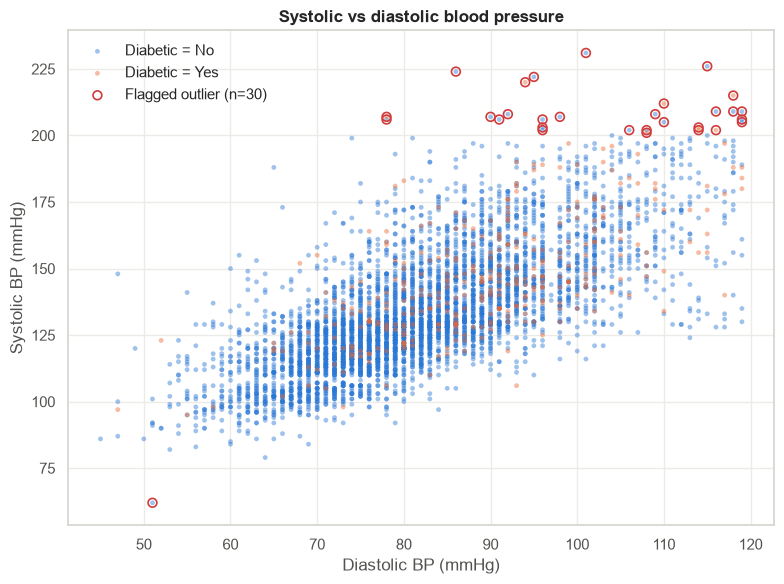

In [122]:
z_mask = detector.z_score_outliers()

detector.plot_scatter("bmi", "glucose", mask=z_mask,
                      title="Glucose vs BMI - isolated points ringed in red (|z| > 3)")
plt.show()

detector.plot_scatter("diastolic_bp", "systolic_bp", mask=z_mask,
                      title="Systolic vs diastolic blood pressure")
plt.show()

**Observations**

- **Glucose vs BMI:** the main cloud sits at BMI 15–30 and glucose 4–10. Two groups of points stand apart:
  - a **horizontal band of very high glucose** (above about 16 mmol/L) spread across all BMI values;
  - a few points with **very high BMI** (above about 35) and normal glucose.
- **Systolic vs diastolic:** the strong diagonal trend is clear. The most isolated points are at the top right (systolic above 200 mmHg).
- **Key insight:** diabetic (orange) patients are heavily **over-represented** in the high-glucose band. They make up only 6.5 % of the data but about **45 %** of the glucose Z-score outliers (58 of 129). These points carry the very signal our research question is about. The high-glucose *non-diabetic* patients are also plausible: they could be undiagnosed cases, or readings taken after a meal.

#### **Task 4.4 – Z-Score Method**

$$ z = \frac{x - \mu}{\sigma} $$

A Z-score measures how many **standard deviations** a value is from the mean. With the conventional threshold **|z| > 3**, a value is flagged if it lies more than 3 SDs away. For truly normal data that happens to only about 0.3 % of observations.

First, step by step for **glucose** so the formula is visible:

In [123]:
glucose = df["glucose"]
mu = glucose.mean()
sigma = glucose.std(ddof=0)          # population standard deviation, matching the formula

z_glucose = (glucose - mu) / sigma
glucose_z_outliers = df[z_glucose.abs() > Z_THRESHOLD]

print(f"mean (mu)  = {mu:.3f}")
print(f"std (sigma) = {sigma:.3f}")
print(f"|z| > {Z_THRESHOLD} means glucose < {mu - Z_THRESHOLD * sigma:.2f} or > {mu + Z_THRESHOLD * sigma:.2f} mmol/L")
print(f"Glucose Z-score outliers: {len(glucose_z_outliers)}")
display(glucose_z_outliers[["age", "gender", "glucose", "bmi", TARGET]]
        .assign(z=z_glucose).sort_values("z", ascending=False).head(8))

mean (mu)  = 7.593
std (sigma) = 2.902
|z| > 3.0 means glucose < -1.11 or > 16.30 mmol/L
Glucose Z-score outliers: 129


,age,gender,glucose,bmi,diabetic,z
453,35,Female,33.46,17.60,No,8.914884
3468,40,Female,30.08,23.33,No,7.749997
3706,30,Female,30.00,20.61,Yes,7.722426
393,55,Male,29.15,23.25,Yes,7.429481
1925,70,Male,28.42,17.78,No,7.177893
4304,49,Female,28.17,21.21,No,7.091733
1155,35,Female,28.08,18.52,No,7.060715
1796,60,Female,27.85,15.01,No,6.981447


Now for every feature at once using the class (it applies the same formula to each column):

In [124]:
z_counts = detector.z_score_outliers().sum().rename("z_score_outliers")
print(f"Z-score outliers per feature (|z| > {Z_THRESHOLD}):")
print(z_counts.sort_values(ascending=False))
print(f"\nTotal flagged values: {z_counts.sum()}   |   "
      f"rows with at least one flag: {detector.z_score_outliers().any(axis=1).sum()}")

Z-score outliers per feature (|z| > 3.0):
glucose         129
height           55
bmi              55
weight           31
systolic_bp      30
pulse_rate       27
age               0
diastolic_bp      0
Name: z_score_outliers, dtype: int64

Total flagged values: 327   |   rows with at least one flag: 284


**Observations**

- **Glucose: 129** values flagged, all above about 16.3 mmol/L. There are none on the low side, because the skew means mean − 3σ is below zero.
- **Age and diastolic BP: 0**. Their distributions are compact and symmetric.
- **Caveat:** the Z-score uses the mean and SD, and both are *pulled up* by the outliers themselves. On skewed data (like glucose) this makes the rule less reliable, which is why we also use IQR.

#### **Task 4.5 – Interquartile Range (IQR) Method**

$$ IQR = Q3 - Q1 $$

$$ Lower\ Bound = Q1 - 1.5(IQR) \qquad Upper\ Bound = Q3 + 1.5(IQR) $$

The IQR rule is built from **percentiles**, so extreme values do not affect the bounds. That makes it **robust** for skewed data.

Step by step for **glucose**:

In [125]:
q1 = df["glucose"].quantile(0.25)
q3 = df["glucose"].quantile(0.75)
iqr = q3 - q1
lower = q1 - IQR_MULTIPLIER * iqr
upper = q3 + IQR_MULTIPLIER * iqr

glucose_iqr_outliers = df[(df["glucose"] < lower) | (df["glucose"] > upper)]

print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Lower bound = {q1:.2f} - 1.5 x {iqr:.2f} = {lower:.2f}")
print(f"Upper bound = {q3:.2f} + 1.5 x {iqr:.2f} = {upper:.2f}")
print(f"Glucose IQR outliers: {len(glucose_iqr_outliers)}")

Q1 = 6.00, Q3 = 8.14, IQR = 2.14
Lower bound = 6.00 - 1.5 x 2.14 = 2.79
Upper bound = 8.14 + 1.5 x 2.14 = 11.35
Glucose IQR outliers: 366


For every feature, with the class:

In [126]:
display(detector.iqr_bounds().round(2))

iqr_mask = detector.iqr_outliers()
print("IQR outliers per feature:")
print(iqr_mask.sum().sort_values(ascending=False))
print(f"\nRows with at least one IQR flag: {iqr_mask.any(axis=1).sum()} of {len(df):,}")

,Q1,Q3,IQR,lower_bound,upper_bound,min,max
age,35.00,55.00,20.00,5.00,85.00,21.00,80.00
pulse_rate,69.00,84.00,15.00,46.50,106.50,36.00,133.00
systolic_bp,119.00,147.00,28.00,77.00,189.00,62.00,231.00
diastolic_bp,73.00,90.00,17.00,47.50,115.50,45.00,119.00
glucose,6.00,8.14,2.14,2.79,11.35,2.00,33.46
height,1.52,1.60,0.08,1.40,1.72,1.19,1.96
weight,46.80,60.00,13.20,27.00,79.80,25.60,100.70
bmi,19.65,24.46,4.81,12.43,31.68,12.04,53.77


IQR outliers per feature:
glucose         366
height          186
bmi             132
systolic_bp     111
pulse_rate       93
weight           75
diastolic_bp     54
age               0
dtype: int64

Rows with at least one IQR flag: 832 of 5,253


**Observations**

- **Glucose: 366** values above 11.35 mmol/L. That is nearly 3× as many as the Z-score method found.
- **Height: 186**. With a narrow IQR (0.08 m), anyone shorter than 1.40 m or taller than 1.72 m is flagged, even though these are normal adult heights.
- The IQR rule flags **more** values than the Z-score rule for every feature.

#### **Task 4.6 – Compare Detection Methods**

,box_plot,z_score,iqr_rule,flagged_by_both,skewness,iqr_%
age,0,0,0,0,0.35,0.00
pulse_rate,93,27,93,27,0.40,1.77
systolic_bp,111,30,111,30,0.72,2.11
diastolic_bp,54,0,54,0,0.40,1.03
glucose,366,129,366,129,3.16,6.97
height,186,55,186,55,-0.09,3.54
weight,75,31,75,31,0.50,1.43
bmi,132,55,132,55,1.04,2.51


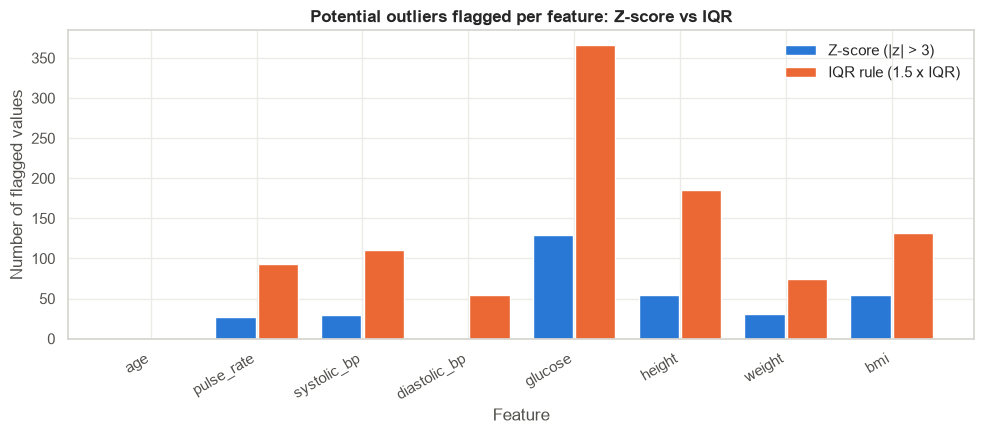

In [127]:
outlier_summary = detector.summary()
display(outlier_summary)

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(outlier_summary))
ax.bar(x - 0.2, outlier_summary["z_score"], width=0.38, color="#2a78d6", label="Z-score (|z| > 3)")
ax.bar(x + 0.2, outlier_summary["iqr_rule"], width=0.38, color="#eb6834", label="IQR rule (1.5 x IQR)")
ax.set_xticks(x, outlier_summary.index, rotation=30, ha="right")
ax.set(title="Potential outliers flagged per feature: Z-score vs IQR",
       xlabel="Feature", ylabel="Number of flagged values")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**Why the methods disagree**

| | Box plot | IQR rule | Z-score |
|---|---|---|---|
| Based on | Quartiles (visual) | Quartiles (numeric) | Mean & SD |
| Affected by outliers? | No | No | **Yes**: outliers inflate the SD, which widens the bounds |
| Assumes normality? | No | No | **Yes**: "3 SD = rare" only holds for bell-shaped data |
| Best for | Spotting patterns | Skewed data | Roughly normal data |

1. **Box plot = IQR.** The counts match exactly because matplotlib draws whiskers using the same 1.5 × IQR rule. The box plot is the *picture* of the IQR rule.
2. **The Z-score always flags fewer.** For a normal distribution the IQR fences sit at about ±2.7 SD, which is tighter than ±3 SD. Also, outliers inflate σ, so the Z-score bounds stretch outwards, an effect called **masking**.
3. **The gap is biggest for skewed features.** For glucose (skew ≈ 3.2) the IQR rule flags 366 values and the Z-score flags 129. For near-symmetric features the two are closer.
4. **"Flagged by both"** equals the Z-score count for every feature, so every Z-score outlier is also an IQR outlier, but not the other way around.

Given that glucose and BMI are skewed (Part 2) and the Q-Q plots showed non-normal data (Part 3), **IQR is the more appropriate detector here**. Being *detected* is still not the same as deserving *removal*, though.

#### **Task 4.7 – Treat Outliers Carefully**

##### Step 1 – Who are the outliers?
Before removing anything, check **which patients** each rule would delete.

In [128]:
by_group = detector.outliers_by_group(iqr_mask)
by_group["% of diabetic group"] = (by_group["Yes"] / (df[TARGET] == "Yes").sum() * 100).round(1)
print("IQR outliers split by diabetic status:")
display(by_group)

IQR outliers split by diabetic status:


diabetic,No,Yes,% of diabetic group
age,0,0,0.0
pulse_rate,81,12,3.5
systolic_bp,96,15,4.4
diastolic_bp,44,10,2.9
glucose,233,133,39.0
height,155,31,9.1
weight,68,7,2.1
bmi,120,12,3.5


**This is the critical finding.** Diabetic patients are only 6.5 % of the data but **36 %** of the glucose IQR outliers. Removing those outliers would delete **133 of the 341 diabetic patients (39 %)**. High glucose is *how diabetes is diagnosed*, so these values are **legitimate and highly informative**, not errors. Deleting them would remove much of the effect we are trying to measure and make the diabetic group look healthier than it really is.

##### Step 2 – Our documented treatment rule

| Feature | Decision | Justification |
|---|---|---|
| **Glucose** | **Keep** all values | Extreme glucose is the diagnostic signal of diabetes |
| **Age, height, weight, pulse, diastolic BP** | **Keep** | Values are plausible, and flagged heights are ordinary adult heights |
| **BMI, systolic BP** | **Remove rows with \|z\| > 3** | Rare, very extreme values (BMI ≈ 35+, SBP ≈ 200+) inflate the SD; they are not diagnostic criteria; the conservative Z rule removes far fewer rows than IQR |

We use the **Z-score rule (not IQR)** for treatment on purpose. The aim is to trim only the most *extreme* tail, not 2–3 % of every column. The cleaned data is a **copy**; `df` stays untouched as the baseline.

In [129]:
TREAT_FEATURES = ["bmi", "systolic_bp"]

df_treated = detector.remove(method="z_score", features=TREAT_FEATURES)   # returns a COPY

print(f"Rows before: {len(df):,}   after: {len(df_treated):,}   removed: {len(df) - len(df_treated)}")
print("\nDiabetic status of the treated data:")
print(df_treated[TARGET].value_counts())
assert len(df) == 5253, "Original df must not be modified"

Rows before: 5,253   after: 5,168   removed: 85

Diabetic status of the treated data:
diabetic
No     4842
Yes     326
Name: count, dtype: int64


##### Step 3 – Compare descriptive statistics before vs after

In [130]:
stats_comparison = OutlierDetector.compare_statistics(df, df_treated, ANALYSIS_FEATURES)
display(stats_comparison)

count            mean                   median            std                
              after  before   after  before change_%   after  before  after before change_%
glucose      5168.0  5253.0    7.59    7.59    -0.02    6.94    6.94   2.90   2.90    -0.09
bmi          5168.0  5253.0   22.20   22.38    -0.80   21.87   21.89   3.72   4.09    -9.08
systolic_bp  5168.0  5253.0  133.38  133.96    -0.43  130.00  130.00  21.45  22.22    -3.45

**Reading the table**

- **Means** move only slightly (well under 1 %).
- **Medians** barely change at all. The median is robust because it ignores how extreme the tails are.
- **Standard deviation** drops the most for **BMI** (about 9 %) and systolic BP (about 3.5 %). Removing just 85 rows (1.6 %) shows how much a handful of extreme values was inflating the spread.
- Glucose was not treated, so its tiny change comes only from the removed BMI/SBP rows.

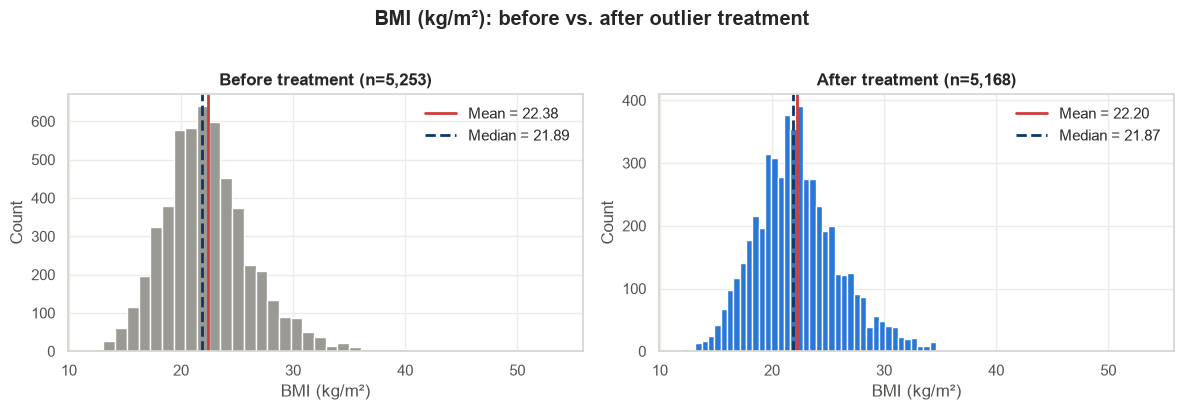

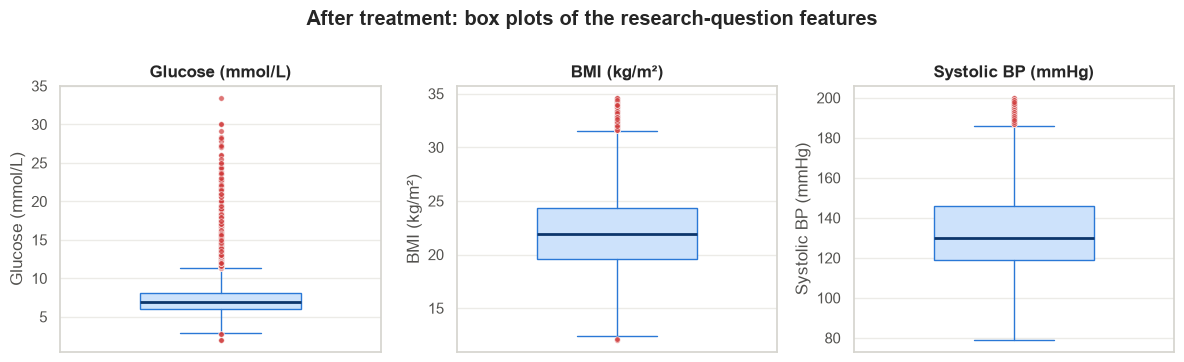

In [131]:
detector.plot_before_after(df_treated, "bmi")
plt.show()

OutlierDetector(df_treated, NUMERIC_FEATURES).plot_boxplots(
    features=ANALYSIS_FEATURES, ncols=3,
    title="After treatment: box plots of the research-question features")
plt.show()

The BMI histogram loses its thin right tail (values ≈ 35–54), and the mean moves slightly closer to the median. Glucose still shows its high tail, as intended.

##### Step 4 – Does our research conclusion survive the treatment? (sensitivity analysis)

This step answers the second half of the research question. We re-run the exact same tests on the treated data.

In [132]:
ttest_treated = GroupComparison(df_treated).compare_all(ANALYSIS_FEATURES)

sensitivity = pd.DataFrame({
    "cohens_d (original)": ttest_results["cohens_d"],
    "cohens_d (treated)": ttest_treated["cohens_d"],
    "welch_p (original)": ttest_results["welch_p"],
    "welch_p (treated)": ttest_treated["welch_p"],
    "significant (treated)": ttest_treated["significant"],
})
display(format_p_values(sensitivity))

,cohens_d (original),cohens_d (treated),welch_p (original),welch_p (treated),significant (treated)
feature,,,,,
glucose,1.327,1.349,1.11e-29,6.19e-29,True
bmi,0.396,0.378,2.60e-10,2.49e-10,True
systolic_bp,0.638,0.602,6.58e-25,7.41e-24,True


**Result:** after outlier treatment, all three differences remain **highly significant** and the effect sizes barely move. **The conclusion is robust**: it is not driven by a few extreme patients.

#### **Task 4.8 – Diabetes Reflection**

> *Draft answers based on this notebook's output. Rewrite them in your own words before submitting.*

1. **What is an outlier?** An observation that lies far from most of the data, for example a glucose reading of 30 mmol/L when the typical range is 5–9.

2. **Three possible causes:** (a) measurement or sensor error; (b) data-entry mistakes such as typos or wrong units (height entered as 0.36 m); (c) genuine but rare cases, such as a patient with severe uncontrolled diabetes. Sampling from a different population can also produce outliers.

3. **Clearest visual outliers:** **glucose** (a long tail of high values), then **height**, **BMI**, and **systolic BP**. **Age** had none.

4. **Z-score (|z| > 3):** 327 flagged values in total (glucose 129, BMI 55, height 55, weight 31, systolic BP 30, pulse 27).

5. **IQR rule:** 1,017 flagged values in total (glucose 366, height 186, BMI 132, systolic BP 111, pulse 93, weight 75, diastolic BP 54).

6. **Why they differ:** the Z-score uses the mean and SD, which the outliers themselves inflate (masking), and it assumes normality. IQR uses quartiles, which outliers do not affect. On skewed data like glucose the IQR rule flags far more values.

7. **When to retain an outlier:** when it is plausible and meaningful. Here, high glucose *is* diabetes. Removing it would delete 39 % of diabetic patients and hide the effect we are studying.

8. **When removal is justified:** when a value is impossible (glucose 0, BMI 574, which we removed in Part 1), or when a rare extreme value distorts statistics without carrying meaning for the question, and the rule is documented and applied to a copy.

9. **Effect on descriptive statistics:** means and medians changed by less than 1 %. BMI's standard deviation fell by about 9 %, and systolic BP's by a few percent. The t-test conclusions and effect sizes stayed the same.

10. **Effect on a downstream ML model:** untreated outliers can pull regression coefficients towards them, dominate distance-based models (k-NN, k-means), distort `StandardScaler` (mean/SD), and inflate error metrics such as RMSE. Wrongly *removing* informative outliers is just as harmful: a diabetes classifier trained without high-glucose patients would miss the very cases it most needs to catch.

---
## **Answer to the Research Question**

> **Do diabetic patients have significantly higher blood glucose, BMI, and systolic blood pressure than non-diabetic patients, and does that conclusion still hold once outliers are taken into account?**

**Yes, on both counts.**

| Feature | Diabetic vs non-diabetic | Effect size | Survives outlier treatment? |
|---|---|---|---|
| Glucose | ≈ +3.7 mmol/L | **Large** (d ≈ 1.3) | ✅ |
| Systolic BP | ≈ +14 mmHg | **Medium** (d ≈ 0.6) | ✅ |
| BMI | ≈ +1.6 kg/m² | **Small** (d ≈ 0.4) | ✅ |

**How we got here**

1. **Preparation:** 35 physically impossible rows were removed, not imputed, because they were errors. Six interpretable features were engineered.
2. **EDA:** showed that all three measurements look higher in diabetic patients, and that glucose and BMI are right-skewed.
3. **Inferential statistics:** Q-Q plots and Shapiro-Wilk showed the data are not normal. With large samples (CLT), Welch's t-test is still valid, and the non-parametric Mann-Whitney U test confirmed every result.
4. **Outlier detection:** IQR suits these skewed features better than the Z-score. Most glucose "outliers" turned out to be diabetic patients, so they were kept. Trimming only extreme BMI/SBP values left the conclusion unchanged.

**Limitations**

- This is **observational** data. It shows *association*, not *causation*.
- Diabetic patients are also **older** on average. Age may explain part of the blood-pressure difference. A regression model controlling for age would be a natural next step.
- Glucose was measured at an unknown time (fasting vs random), which limits clinical interpretation.

---
# **Final Validation and Submission Checklist**

- [x] All four required sections are in this single notebook.
- [x] PEW uses `pd.melt()` or `DataFrame.melt()`.
- [x] Billboard uses `melt()` and Pandas string manipulation.
- [x] Cars demonstrates missing-value analysis, dropping, imputation, duplicates, and validation.
- [x] Diabetes includes box plot, scatter plot, Z-Score, and IQR.
- [x] Every required visualization has a meaningful title and axis labels.
- [x] Reflection questions are answered in Markdown.
- [x] Data is loaded using relative paths from a clearly named data folder (or from the team's Neon database).
- [x] `README.md`, `requirements.txt`, and `.gitignore` are included.
- [x] There are no unnecessary `!pip install` cells.
- [x] The kernel was restarted and **Run All** completed from top to bottom (see the Replicability Check).